# YOLOv8n Object Detection on VisDrone

## Objective
Train and evaluate a YOLOv8n object detector on the VisDrone2019-DET dataset.

## Approach
Start with pretrained YOLOv8n weights and fine-tune the model on VisDrone.

## Research Goal
Establish a reliable baseline before developing and evaluating a custom improvement for small-object detection.

In [1]:
import torch
import ultralytics
from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu126
Ultralytics version: 8.4.178
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Project and Dataset Paths

Define the project root, locate the VisDrone dataset configuration file, and create the directory for training outputs. This keeps the project organized and ensures that training results are saved in the correct location.

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent

DATASET_YAML = PROJECT_ROOT / "datasets" / "VisDrone" / "VisDrone.yaml"
RUNS_DIR = PROJECT_ROOT / "runs"

assert DATASET_YAML.exists(), f"Dataset YAML not found: {DATASET_YAML}"

RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset configuration:", DATASET_YAML)
print("Training output directory:", RUNS_DIR)

Project root: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone
Dataset configuration: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml
Training output directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs


## 2. Validate the VisDrone Dataset

Load the dataset configuration and verify the training, validation, and test paths, along with the number and names of the object classes. This confirms that YOLO can locate the dataset before training begins.

In [3]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset(str(DATASET_YAML))

print("Dataset path:", data["path"])
print("Training images:", data["train"])
print("Validation images:", data["val"])
print("Test images:", data["test"])
print("Number of classes:", data["nc"])
print("Class names:", data["names"])

Dataset path: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone
Training images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\train
Validation images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Test images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\test
Number of classes: 10
Class names: {0: 'pedestrian', 1: 'people', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'awning-tricycle', 8: 'bus', 9: 'motor'}


## 3. Configure Pilot Training

Load the pretrained YOLOv8n model and define conservative training settings for the available GPU memory. The pilot uses two epochs and a small batch size to verify that the model can train on VisDrone before committing to a longer run.

The validation set will be used to monitor performance. The test set will remain untouched until the final evaluation.

In [4]:
from ultralytics import YOLO

MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

print("Pretrained model loaded:", MODEL_NAME)

Pretrained model loaded: yolov8n.pt


## 4. Run Pilot Training

Fine-tune the pretrained YOLOv8n model on the VisDrone training set for two epochs. Use a batch size of 4 and an image size of 640 to limit GPU memory usage. Save the training logs, evaluation metrics, plots, and model checkpoints in the project's `runs` directory.

This short pilot checks that the training pipeline works; it is not the final performance evaluation.

In [5]:
results = model.train(
    data=str(DATASET_YAML),
    epochs=2,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    project=str(RUNS_DIR),
    name="visdrone_pilot",
    exist_ok=True,
    plots=True,
    seed=42,
)

print("Pilot training completed.")
print("Results directory:", RUNS_DIR / "visdrone_pilot")

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio

## 5. Inspect Pilot Training Results

Read the metrics recorded during training and display the key validation results. This helps us verify that the model learned from the training data and assess its initial detection performance before running a longer experiment.

In [6]:
import pandas as pd

RESULTS_DIR = RUNS_DIR / "visdrone_pilot"
METRICS_FILE = RESULTS_DIR / "results.csv"

print("Results directory:", RESULTS_DIR)
print("Metrics file exists:", METRICS_FILE.exists())

if METRICS_FILE.exists():
    metrics = pd.read_csv(METRICS_FILE)
    metrics.columns = metrics.columns.str.strip()

    display(metrics.tail())

    key_columns = [
        col for col in metrics.columns
        if any(key in col.lower() for key in [
            "epoch",
            "precision",
            "recall",
            "map50",
            "map75",
            "map50-95",
            "box_loss",
            "cls_loss",
            "dfl_loss",
        ])
    ]

    print("\nKey metrics:")
    display(metrics[key_columns])
else:
    print("results.csv was not found. Check the results directory.")

Results directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_pilot
Metrics file exists: True


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,118.978,1.90301,1.80904,1.02559,0.25192,0.20744,0.15550,0.08031,1.78384,1.43793,0.96607,0.000714,0.000714,0.000714
1,2,234.263,1.79250,1.47654,0.97141,0.26959,0.22103,0.18173,0.09591,1.75366,1.36545,0.94666,0.000361,0.000361,0.000361



Key metrics:


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss
0,1,1.90301,1.80904,1.02559,0.25192,0.20744,0.15550,0.08031,1.78384,1.43793,0.96607
1,2,1.79250,1.47654,0.97141,0.26959,0.22103,0.18173,0.09591,1.75366,1.36545,0.94666


## 7. Configure Full Baseline Training

Prepare a separate YOLOv8n training run using the pretrained weights. Train for 20 epochs on the VisDrone training split, monitor performance on the validation split, and save the results separately from the pilot experiment. This baseline will be the reference for evaluating our later custom improvement.

In [7]:
from ultralytics import YOLO

BASELINE_MODEL = YOLO("yolov8n.pt")

print("Pretrained YOLOv8n model loaded for baseline training.")

Pretrained YOLOv8n model loaded for baseline training.


## 8. Train the YOLOv8n Baseline

Fine-tune YOLOv8n on the VisDrone training images for 20 epochs. Use the validation split to calculate detection metrics after each epoch. Save checkpoints, logs, and plots in a dedicated baseline directory for reproducibility and later comparison.

In [8]:
baseline_results = BASELINE_MODEL.train(
    data=str(DATASET_YAML),
    epochs=20,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    project=str(RUNS_DIR),
    name="visdrone_baseline",
    exist_ok=False,
    plots=True,
    seed=42,
    patience=7,
    save=True,
)

print("Baseline training completed.")
print("Results directory:", RUNS_DIR / "visdrone_baseline")

New https://pypi.org/project/ultralytics/8.4.190 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rat

In [9]:
from pathlib import Path
import pandas as pd

# Locate the baseline results
BASELINE_DIR = RUNS_DIR / "visdrone_baseline"

# Check which files were saved
print("Baseline directory:", BASELINE_DIR)
print("\nSaved files:")

for file in sorted(BASELINE_DIR.iterdir()):
    print(file.name)

# Load training metrics
results_file = BASELINE_DIR / "results.csv"

if results_file.exists():
    results_df = pd.read_csv(results_file)
    
    print("\nTraining history:")
    display(results_df.tail())

    print("\nBest validation metrics:")

    metric_columns = [
        col for col in results_df.columns
        if "metrics/" in col
    ]

    if metric_columns:
        best_row = results_df.loc[
            results_df["metrics/mAP50-95(B)"].idxmax()
        ] if "metrics/mAP50-95(B)" in results_df.columns else None

        if best_row is not None:
            print(best_row[metric_columns])
            print("Best epoch:", int(best_row["epoch"]) + 1)
        else:
            print(results_df[metric_columns].tail())
else:
    print("results.csv was not found.")

Baseline directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline

Saved files:
args.yaml
BoxF1_curve.png
BoxP_curve.png
BoxPR_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch16180.jpg
train_batch16181.jpg
train_batch16182.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights

Training history:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,2008.71,1.59076,1.14615,0.90889,0.38988,0.28652,0.26823,0.14682,1.57186,1.14062,0.90423,0.000184,0.000184,0.000184
16,17,2135.76,1.59068,1.13630,0.90595,0.39512,0.29473,0.27146,0.14792,1.56848,1.13715,0.90349,0.000149,0.000149,0.000149
17,18,2264.46,1.58642,1.12877,0.90650,0.39318,0.29243,0.27598,0.15199,1.55593,1.12462,0.89965,0.000113,0.000113,0.000113
18,19,2388.74,1.57065,1.11461,0.90479,0.39995,0.29683,0.27915,0.15303,1.55669,1.11956,0.90055,0.000078,0.000078,0.000078
19,20,2513.50,1.56658,1.10493,0.90264,0.39598,0.29518,0.27915,0.15394,1.55079,1.11736,0.89814,0.000042,0.000042,0.000042



Best validation metrics:
metrics/precision(B)    0.39598
metrics/recall(B)       0.29518
metrics/mAP50(B)        0.27915
metrics/mAP50-95(B)     0.15394
Name: 19, dtype: float64
Best epoch: 21


## 9. Inspect Baseline Predictions

Display the ground-truth annotations and YOLOv8 predictions for the same validation images. Comparing these images helps identify missed objects, false detections, and inaccurate bounding boxes.

Ground-truth annotations:


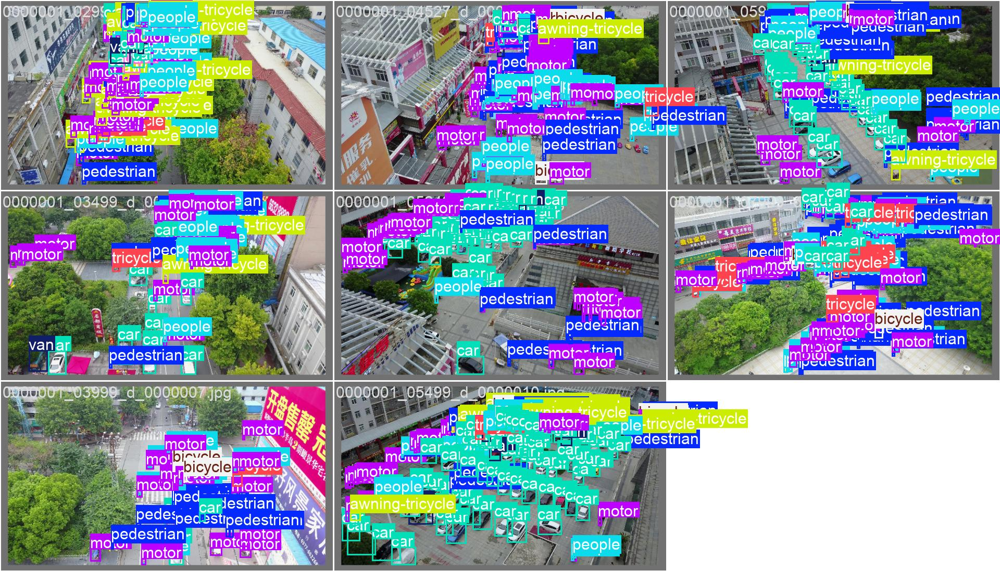

Model predictions:


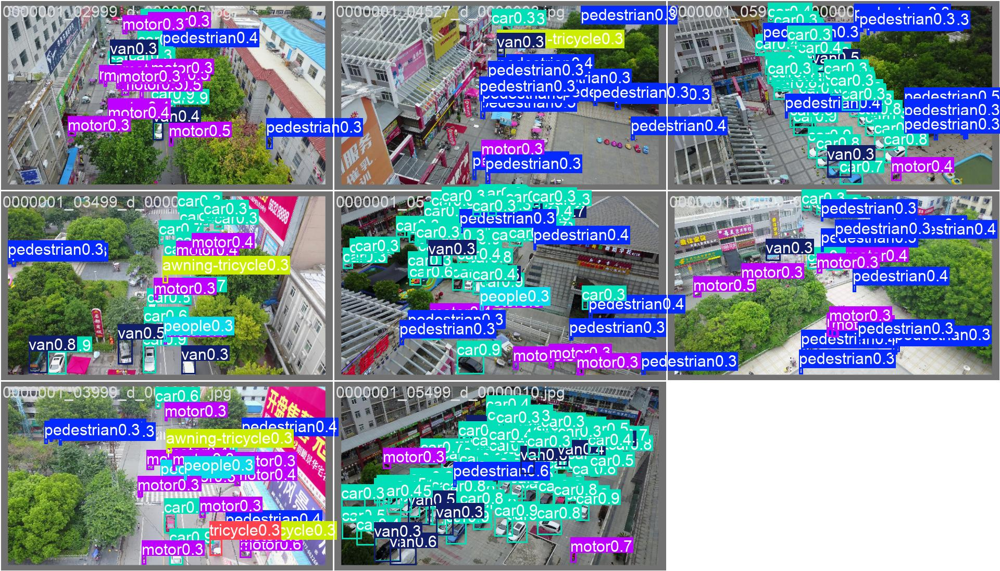

In [11]:
from IPython.display import display, Image

BASELINE_DIR = RUNS_DIR / "visdrone_baseline"

labels_image = BASELINE_DIR / "val_batch0_labels.jpg"
pred_image = BASELINE_DIR / "val_batch0_pred.jpg"

print("Ground-truth annotations:")
display(Image(filename=str(labels_image)))

print("Model predictions:")
display(Image(filename=str(pred_image)))

## 10. Analyze Training Curves

Visualize the training and validation metrics recorded during baseline training. These curves help assess learning progress, convergence, and possible overfitting.

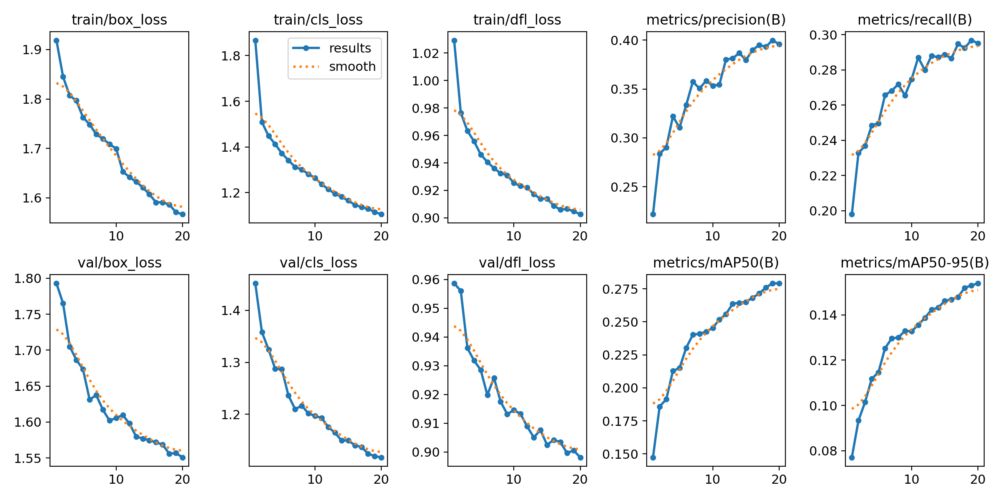

In [12]:
from IPython.display import display, Image

RESULTS_PLOT = RUNS_DIR / "visdrone_baseline" / "results.png"

if RESULTS_PLOT.exists():
    display(Image(filename=str(RESULTS_PLOT)))
else:
    print("Training plot not found:", RESULTS_PLOT)

In [13]:
import pandas as pd

RESULTS_FILE = RUNS_DIR / "visdrone_baseline" / "results.csv"

metrics_df = pd.read_csv(RESULTS_FILE)
metrics_df.columns = metrics_df.columns.str.strip()

# Select the metrics needed for analysis
columns_to_show = [
    "epoch",
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss",
]

# Print all epochs in a copyable format
print(metrics_df[columns_to_show].round(4).to_string(index=False))

 epoch  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss
     1          1.9189          1.8674          1.0293                0.2218             0.1980            0.1474               0.0771        1.7930        1.4518        0.9586
     2          1.8449          1.5083          0.9765                0.2839             0.2329            0.1859               0.0934        1.7650        1.3580        0.9560
     3          1.8068          1.4477          0.9633                0.2902             0.2369            0.1914               0.1016        1.7050        1.3247        0.9362
     4          1.7967          1.4120          0.9557                0.3220             0.2485            0.2128               0.1118        1.6865        1.2875        0.9318
     5          1.7628          1.3717          0.9462                0.3105             0.2497            0.2150  

## 11. Evaluate the Baseline by Class

Load the best checkpoint selected during training and evaluate it on the validation set. Record overall metrics and per-class average precision to identify which VisDrone categories are most difficult for the model.

In [14]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

assert BEST_MODEL_PATH.exists(), f"Checkpoint not found: {BEST_MODEL_PATH}"

best_model = YOLO(str(BEST_MODEL_PATH))

val_metrics = best_model.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=False,
    verbose=True,
)

print("\nOverall validation metrics:")
print(f"mAP50:    {val_metrics.box.map50:.4f}")
print(f"mAP50-95: {val_metrics.box.map:.4f}")

print("\nPer-class AP50:")
for class_id, ap50 in enumerate(val_metrics.box.ap50):
    class_name = val_metrics.names[class_id]
    print(f"{class_name:20s}: {ap50:.4f}")

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 632.2±211.8 MB/s, size: 142.5 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 137/137 14.6it/s 9.4s0.1s
                   all        548      38759      0.396      0.297      0.269      0.151
            pedestrian        520   

## 12. Analyze Training Class Distribution

Define the dataset path explicitly, then count the annotated objects in each training class. This makes the cell independent of the earlier notebook variables.

In [16]:
from pathlib import Path
from collections import Counter
import pandas as pd

# Define the dataset path
PROJECT_ROOT = Path.cwd().resolve().parent
DATASET_DIR = PROJECT_ROOT / "datasets" / "VisDrone"
TRAIN_LABEL_DIR = DATASET_DIR / "labels" / "train"

assert TRAIN_LABEL_DIR.exists(), f"Training labels not found: {TRAIN_LABEL_DIR}"

# Count instances in each class
class_counts = Counter()

for label_file in TRAIN_LABEL_DIR.glob("*.txt"):
    with open(label_file, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.split()

            if len(parts) == 5:
                class_id = int(parts[0])
                class_counts[class_id] += 1

# Class names in the VisDrone dataset
class_names = {
    0: "pedestrian",
    1: "people",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "awning-tricycle",
    8: "bus",
    9: "motor",
}

# Create the distribution table
distribution = pd.DataFrame([
    {
        "class_id": class_id,
        "class_name": class_names[class_id],
        "training_instances": class_counts[class_id],
    }
    for class_id in range(10)
])

total_instances = distribution["training_instances"].sum()

distribution["percentage"] = (
    distribution["training_instances"] / total_instances * 100
)

distribution = distribution.sort_values(
    "training_instances", ascending=False
).reset_index(drop=True)

print("Total training instances:", total_instances)
print(distribution.round({"percentage": 2}).to_string(index=False))

Total training instances: 343204
 class_id      class_name  training_instances  percentage
        3             car              144866       42.21
        0      pedestrian               79337       23.12
        9           motor               29647        8.64
        1          people               27059        7.88
        4             van               24956        7.27
        5           truck               12875        3.75
        2         bicycle               10480        3.05
        8             bus                5926        1.73
        6        tricycle                4812        1.40
        7 awning-tricycle                3246        0.95


## 13. Analyze Object Sizes by Class

Calculate the normalized bounding-box area for each annotated training object and summarize the distribution by class. This analysis helps determine whether poorly detected classes tend to contain smaller objects.

In [17]:
from pathlib import Path
from collections import defaultdict
import pandas as pd

TRAIN_LABEL_DIR = DATASET_DIR / "labels" / "train"

# Store normalized bounding-box areas for each class
areas_by_class = defaultdict(list)

for label_file in TRAIN_LABEL_DIR.glob("*.txt"):
    with open(label_file, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            box_width = float(parts[3])
            box_height = float(parts[4])

            # Normalized box area as a fraction of image area
            box_area = box_width * box_height

            if box_area > 0:
                areas_by_class[class_id].append(box_area)

class_names = {
    0: "pedestrian",
    1: "people",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "awning-tricycle",
    8: "bus",
    9: "motor",
}

size_rows = []

for class_id, areas in areas_by_class.items():
    series = pd.Series(areas)

    size_rows.append({
        "class_name": class_names[class_id],
        "instances": len(areas),
        "median_area_percent": series.median() * 100,
        "mean_area_percent": series.mean() * 100,
        "25th_percentile_percent": series.quantile(0.25) * 100,
        "75th_percentile_percent": series.quantile(0.75) * 100,
    })

size_df = pd.DataFrame(size_rows).sort_values(
    "median_area_percent"
)

print(size_df.round(4).to_string(index=False))

     class_name  instances  median_area_percent  mean_area_percent  25th_percentile_percent  75th_percentile_percent
         people      27059               0.0189             0.0375                   0.0085                   0.0404
     pedestrian      79337               0.0230             0.0470                   0.0098                   0.0522
          motor      29647               0.0347             0.0607                   0.0149                   0.0720
        bicycle      10480               0.0351             0.0667                   0.0155                   0.0784
            car     144866               0.0731             0.2047                   0.0261                   0.2163
awning-tricycle       3246               0.0841             0.1739                   0.0328                   0.1957
       tricycle       4812               0.0868             0.1657                   0.0333                   0.1975
            van      24956               0.0910             0.23

## 14. Inspect Baseline Predictions

Load the best checkpoint from baseline training and generate predictions on a small sample of validation images. Compare the predicted bounding boxes with the ground-truth annotations to identify missed objects, incorrect classifications, and localization errors.

In [18]:
from ultralytics import YOLO
import random

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
VAL_IMAGE_DIR = DATASET_DIR / "images" / "val"

assert BEST_MODEL_PATH.exists(), f"Model not found: {BEST_MODEL_PATH}"
assert VAL_IMAGE_DIR.exists(), f"Validation images not found: {VAL_IMAGE_DIR}"

best_model = YOLO(str(BEST_MODEL_PATH))

random.seed(42)
val_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))
sample_images = random.sample(val_images, min(8, len(val_images)))

predictions = best_model.predict(
    source=[str(path) for path in sample_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    save=True,
    project=str(RUNS_DIR),
    name="baseline_error_inspection",
    exist_ok=True,
    verbose=False,
)

print("Images inspected:", len(predictions))
print("Prediction images saved to:", RUNS_DIR / "baseline_error_inspection")

Results saved to C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\baseline_error_inspection
Images inspected: 8
Prediction images saved to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\baseline_error_inspection


## 15. Compare Ground Truth with Baseline Predictions

Display the ground-truth annotations and model predictions side by side for the same validation images. This comparison helps identify missed objects, incorrect classifications, and poorly localized bounding boxes.

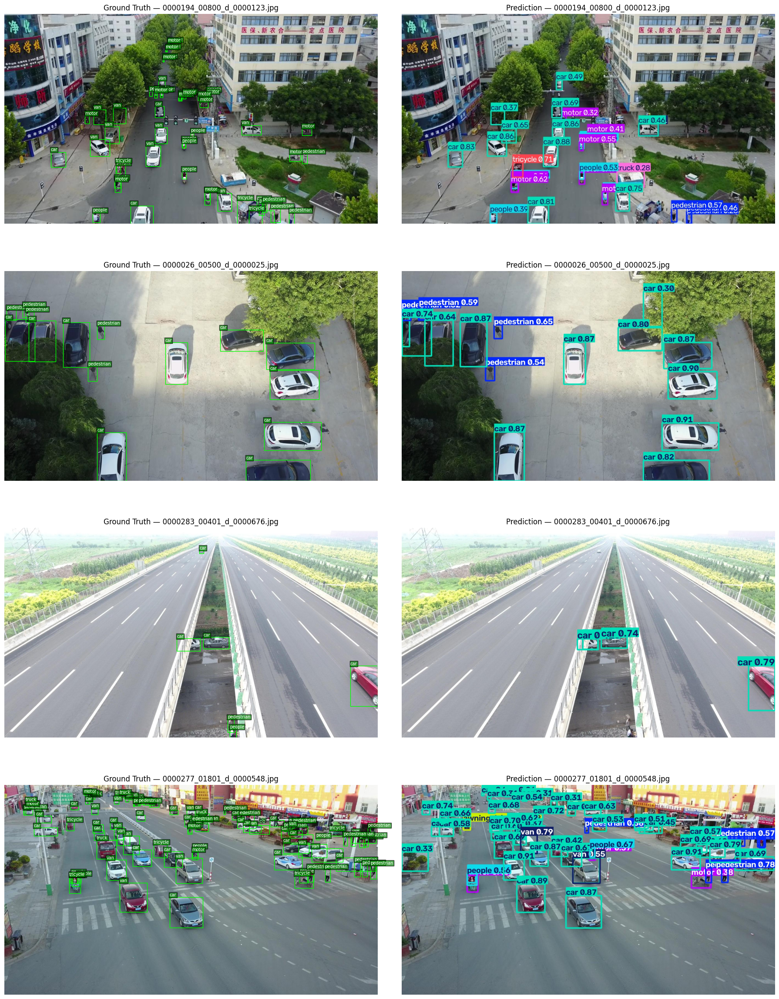

In [20]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

LABEL_DIR = DATASET_DIR / "labels" / "val"

class_names = {
    0: "pedestrian",
    1: "people",
    2: "bicycle",
    3: "car",
    4: "van",
    5: "truck",
    6: "tricycle",
    7: "awning-tricycle",
    8: "bus",
    9: "motor",
}

fig, axes = plt.subplots(4, 2, figsize=(18, 24))

for i, image_path in enumerate(sample_images[:4]):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    # Draw ground-truth annotations
    ax_gt = axes[i, 0]
    ax_gt.imshow(image)

    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.split()
                if len(parts) != 5:
                    continue

                class_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])

                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height

                ax_gt.add_patch(
                    Rectangle(
                        (x1, y1),
                        bw * width,
                        bh * height,
                        fill=False,
                        edgecolor="lime",
                        linewidth=1,
                    )
                )
                ax_gt.text(
                    x1, max(0, y1 - 3),
                    class_names[class_id],
                    color="white",
                    fontsize=7,
                    bbox=dict(facecolor="green", alpha=0.7, pad=1),
                )

    ax_gt.set_title(f"Ground Truth — {image_path.name}")
    ax_gt.axis("off")

    # Display the model's predictions
    pred_path = PREDICTION_DIR / image_path.name
    ax_pred = axes[i, 1]
    ax_pred.imshow(Image.open(pred_path))
    ax_pred.set_title(f"Prediction — {image_path.name}")
    ax_pred.axis("off")

plt.tight_layout()
plt.show()

## 16. Analyze Class Confusion

Evaluate the trained baseline on the validation set and generate a confusion matrix. The matrix shows how ground-truth classes correspond to predicted classes, helping identify visually similar categories that the model confuses. It also distinguishes missed detections from incorrect classifications.

In [21]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

assert BEST_MODEL_PATH.exists(), f"Model not found: {BEST_MODEL_PATH}"

confusion_model = YOLO(str(BEST_MODEL_PATH))

confusion_results = confusion_model.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    conf=0.001,
    iou=0.6,
    project=str(RUNS_DIR),
    name="visdrone_confusion_analysis",
    exist_ok=True,
)

print("Confusion matrix analysis completed.")
print("Results directory:", RUNS_DIR / "visdrone_confusion_analysis")

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 814.7±289.1 MB/s, size: 142.5 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 137/137 13.2it/s 10.4s0.0s
                   all        548      38759       0.41      0.301      0.275      0.152
            pedestrian        520  

In [22]:
CONFUSION_DIR = RUNS_DIR / "visdrone_confusion_analysis"

for path in sorted(CONFUSION_DIR.glob("*")):
    print(path.name)

BoxF1_curve.png
BoxP_curve.png
BoxPR_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


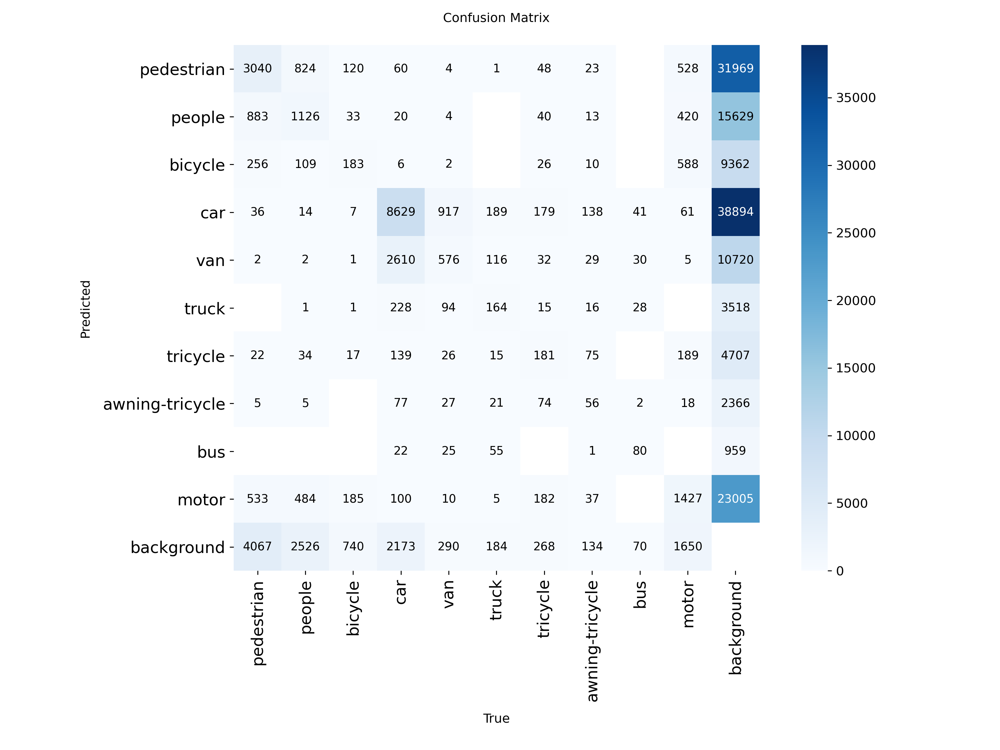

In [23]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display

CONFUSION_DIR = RUNS_DIR / "visdrone_confusion_analysis"

matrix_path = CONFUSION_DIR / "confusion_matrix.png"
normalized_path = CONFUSION_DIR / "confusion_matrix_normalized.png"

if matrix_path.exists():
    display(Image.open(matrix_path))
elif normalized_path.exists():
    display(Image.open(normalized_path))
else:
    print("Confusion matrix image was not found.")
    print("Files in the evaluation folder:")
    for path in sorted(CONFUSION_DIR.iterdir()):
        print(path.name)

In [24]:
import numpy as np
import pandas as pd
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

confusion_model = YOLO(str(BEST_MODEL_PATH))

# Reuse the confusion matrix from the previous validation run if available.
# Otherwise, run validation to generate it.
if "confusion_results" not in globals():
    confusion_results = confusion_model.val(
        data=str(DATASET_YAML),
        split="val",
        imgsz=640,
        batch=4,
        device=0,
        workers=2,
        plots=False,
        conf=0.001,
        iou=0.6,
        max_det=500,
        save_json=False,
        verbose=False,
    )

cm_object = confusion_results.confusion_matrix
cm = np.asarray(cm_object.matrix)

names = confusion_results.names
if isinstance(names, dict):
    class_names = [names[i] for i in sorted(names)]
else:
    class_names = list(names)

# Include the background category used for unmatched detections.
labels = class_names + ["background"]

# Verify dimensions before assigning labels.
print("Matrix shape:", cm.shape)
print("Number of labels:", len(labels))

if cm.shape == (len(labels), len(labels)):
    cm_df = pd.DataFrame(cm.astype(int), index=labels, columns=labels)
    print("\nConfusion matrix:")
    print(cm_df.to_string())
else:
    print("Matrix dimensions differ from the expected label count.")
    print("Please share the matrix shape and number of labels.")

Matrix shape: (11, 11)
Number of labels: 11

Confusion matrix:
                 pedestrian  people  bicycle   car  van  truck  tricycle  awning-tricycle  bus  motor  background
pedestrian             3040     824      120    60    4      1        48               23    0    528       31969
people                  883    1126       33    20    4      0        40               13    0    420       15629
bicycle                 256     109      183     6    2      0        26               10    0    588        9362
car                      36      14        7  8629  917    189       179              138   41     61       38894
van                       2       2        1  2610  576    116        32               29   30      5       10720
truck                     0       1        1   228   94    164        15               16   28      0        3518
tricycle                 22      34       17   139   26     15       181               75    0    189        4707
awning-tricycle          

 Quantify Class Confusion and Missed Detections

Calculate per-class detection and miss rates, then identify the most frequent incorrect predicted class for each ground-truth category. This accounts for differences in the number of objects per class.

In [25]:
import pandas as pd

class_labels = [name for name in cm_df.index if name != "background"]
error_rows = []

for class_name in class_labels:
    row = cm_df.loc[class_name]

    total_objects = int(row.sum())
    correct = int(row[class_name])
    missed = int(row["background"])

    # Exclude correct predictions and background when finding
    # the most common incorrect class.
    wrong_predictions = row.drop(
        labels=[class_name, "background"]
    )

    most_common_wrong_class = wrong_predictions.idxmax()
    most_common_wrong_count = int(wrong_predictions.max())

    error_rows.append({
        "class": class_name,
        "ground_truth_objects": total_objects,
        "correct": correct,
        "correct_rate_%": 100 * correct / total_objects if total_objects else 0,
        "missed": missed,
        "miss_rate_%": 100 * missed / total_objects if total_objects else 0,
        "most_confused_with": most_common_wrong_class,
        "wrong_count": most_common_wrong_count,
        "wrong_rate_%": (
            100 * most_common_wrong_count / total_objects
            if total_objects else 0
        ),
    })

error_summary = pd.DataFrame(error_rows)

print(error_summary.round(2).to_string(index=False))

          class  ground_truth_objects  correct  correct_rate_%  missed  miss_rate_% most_confused_with  wrong_count  wrong_rate_%
     pedestrian                 36617     3040            8.30   31969        87.31             people          824          2.25
         people                 18168     1126            6.20   15629        86.02         pedestrian          883          4.86
        bicycle                 10542      183            1.74    9362        88.81              motor          588          5.58
            car                 49105     8629           17.57   38894        79.21                van          917          1.87
            van                 14123      576            4.08   10720        75.90                car         2610         18.48
          truck                  4065      164            4.03    3518        86.54                car          228          5.61
       tricycle                  5405      181            3.35    4707        87.09       

In [26]:
import pandas as pd

class_labels = [name for name in cm_df.index if name != "background"]
error_rows = []

for class_name in class_labels:
    row = cm_df.loc[class_name]

    correct = int(row[class_name])
    missed = int(cm_df.loc["background", class_name])
    false_positives = int(row["background"])

    # Ground-truth objects include matched objects and missed objects.
    ground_truth = int(row.drop(labels=["background"]).sum()) + missed

    # Incorrect class assignments for this actual class.
    wrong_predictions = row.drop(
        labels=[class_name, "background"]
    )
    most_confused_with = wrong_predictions.idxmax()
    wrong_count = int(wrong_predictions.max())

    error_rows.append({
        "class": class_name,
        "ground_truth": ground_truth,
        "correct": correct,
        "recall_%": 100 * correct / ground_truth if ground_truth else 0,
        "missed": missed,
        "miss_rate_%": 100 * missed / ground_truth if ground_truth else 0,
        "false_positives": false_positives,
        "most_confused_with": most_confused_with,
        "confusion_count": wrong_count,
    })

corrected_summary = pd.DataFrame(error_rows)

print(corrected_summary.round(2).to_string(index=False))
print("\nTotal missed ground-truth objects:",
      int(cm_df.loc["background", class_labels].sum()))
print("Total unmatched predictions:",
      int(cm_df.loc[class_labels, "background"].sum()))

          class  ground_truth  correct  recall_%  missed  miss_rate_%  false_positives most_confused_with  confusion_count
     pedestrian          8715     3040     34.88    4067        46.67            31969             people              824
         people          5065     1126     22.23    2526        49.87            15629         pedestrian              883
        bicycle          1920      183      9.53     740        38.54             9362              motor              588
            car         12384     8629     69.68    2173        17.55            38894                van              917
            van          3693      576     15.60     290         7.85            10720                car             2610
          truck           731      164     22.44     184        25.17             3518                car              228
       tricycle           966      181     18.74     268        27.74             4707              motor              189
awning-tricycle 

In [27]:
import pandas as pd

class_labels = [name for name in cm_df.index if name != "background"]
error_rows = []

for actual_class in class_labels:
    # Each column corresponds to the actual class.
    column = cm_df[actual_class]

    correct = int(column[actual_class])
    missed = int(column["background"])
    ground_truth = int(column.sum())

    # Other predicted classes for this actual class.
    wrong_predictions = column.drop(
        labels=[actual_class, "background"]
    )
    most_confused_with = wrong_predictions.idxmax()
    wrong_count = int(wrong_predictions.max())

    error_rows.append({
        "actual_class": actual_class,
        "ground_truth": ground_truth,
        "correct": correct,
        "recall_%": 100 * correct / ground_truth if ground_truth else 0,
        "missed": missed,
        "miss_rate_%": 100 * missed / ground_truth if ground_truth else 0,
        "most_common_wrong_prediction": most_confused_with,
        "wrong_count": wrong_count,
        "wrong_rate_%": 100 * wrong_count / ground_truth if ground_truth else 0,
    })

corrected_summary = pd.DataFrame(error_rows)
print(corrected_summary.round(2).to_string(index=False))

print("\nTotal missed ground-truth objects:",
      int(cm_df.loc["background", class_labels].sum()))
print("Total unmatched predictions:",
      int(cm_df.loc[class_labels, "background"].sum()))

   actual_class  ground_truth  correct  recall_%  missed  miss_rate_% most_common_wrong_prediction  wrong_count  wrong_rate_%
     pedestrian          8844     3040     34.37    4067        45.99                       people          883          9.98
         people          5125     1126     21.97    2526        49.29                   pedestrian          824         16.08
        bicycle          1287      183     14.22     740        57.50                        motor          185         14.37
            car         14064     8629     61.36    2173        15.45                          van         2610         18.56
            van          1975      576     29.16     290        14.68                          car          917         46.43
          truck           750      164     21.87     184        24.53                          car          189         25.20
       tricycle          1045      181     17.32     268        25.65                        motor          182       

## 17. Analyze Validation Object Sizes

Measure the distribution of ground-truth bounding-box areas in the validation set. This will help determine how many objects are small, medium, or large before designing a targeted improvement.

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd

VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"

area_records = []

for label_path in VAL_LABEL_DIR.glob("*.txt"):
    with open(label_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id, x_center, y_center, width, height = map(float, parts)

            # Bounding-box area as a fraction of the image area.
            area_percent = width * height * 100

            area_records.append({
                "class_id": int(class_id),
                "class_name": data["names"][int(class_id)],
                "area_percent": area_percent,
            })

val_areas = pd.DataFrame(area_records)

print("Validation objects:", len(val_areas))
print("\nOverall object-area distribution (% of image):")
print(
    val_areas["area_percent"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(4)
    .to_string()
)

print("\nObject-area distribution by class:")
area_by_class = (
    val_areas.groupby("class_name")["area_percent"]
    .agg(
        count="count",
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .round(4)
    .sort_values("median")
)

print(area_by_class.to_string())

Validation objects: 38759

Overall object-area distribution (% of image):
count    38759.0000
mean         0.1536
std          0.4314
min          0.0006
25%          0.0222
50%          0.0552
75%          0.1384
90%          0.3499
max         34.1630

Object-area distribution by class:
                 count  median    mean     q25     q75
class_name                                            
pedestrian        8844  0.0307  0.0583  0.0148  0.0648
people            5125  0.0311  0.0511  0.0146  0.0615
motor             4886  0.0427  0.0741  0.0202  0.0850
bicycle           1287  0.0438  0.0708  0.0215  0.0832
awning-tricycle    532  0.0892  0.1741  0.0443  0.1962
tricycle          1045  0.0955  0.1692  0.0465  0.1977
car              14064  0.1057  0.2444  0.0384  0.2680
van               1975  0.1157  0.2505  0.0464  0.2660
bus                251  0.1242  0.4791  0.0459  0.3618
truck              750  0.1616  0.5346  0.0621  0.4706


## 18. Higher-Resolution Baseline Evaluation

Evaluate the trained YOLOv8n model at 800-pixel inference resolution. Compare its precision, recall, mAP50, and mAP50-95 against the existing 640-pixel baseline. This is an inference-only experiment; it does not retrain or modify the saved model.

In [29]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

high_res_model = YOLO(str(BEST_MODEL_PATH))

high_res_metrics = high_res_model.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=800,
    batch=1,
    device=0,
    workers=2,
    plots=False,
    verbose=False,
)

print("Validation results at imgsz=800")
print(f"Precision:  {high_res_metrics.box.mp:.4f}")
print(f"Recall:     {high_res_metrics.box.mr:.4f}")
print(f"mAP50:      {high_res_metrics.box.map50:.4f}")
print(f"mAP50-95:   {high_res_metrics.box.map:.4f}")

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 749.7±270.5 MB/s, size: 163.4 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 32.9it/s 16.6s0.0s
                   all        548      38759       0.42      0.339      0.311      0.176
Speed: 1.1ms preprocess, 6.5ms infe

## 19. Higher-Resolution Validation at 960 Pixels

Evaluate the same trained YOLOv8n checkpoint at 960-pixel resolution. Record detection metrics and per-image preprocessing, inference, and postprocessing times to measure the accuracy–speed trade-off against the 640- and 800-pixel evaluations.

In [31]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

model_960 = YOLO(str(BEST_MODEL_PATH))

metrics_960 = model_960.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=960,
    batch=1,
    device=0,
    workers=2,
    plots=False,
    verbose=False,
)

print("Validation results at imgsz=960")
print(f"Precision:  {metrics_960.box.mp:.4f}")
print(f"Recall:     {metrics_960.box.mr:.4f}")
print(f"mAP50:      {metrics_960.box.map50:.4f}")
print(f"mAP50-95:   {metrics_960.box.map:.4f}")

print("\nSpeed per image:")
print(f"Preprocess:  {metrics_960.speed['preprocess']:.2f} ms")
print(f"Inference:   {metrics_960.speed['inference']:.2f} ms")
print(f"Postprocess: {metrics_960.speed['postprocess']:.2f} ms")
print(
    "Total measured stages: "
    f"{sum(metrics_960.speed[k] for k in ['preprocess', 'inference', 'postprocess']):.2f} ms/image"
)

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1205.5±250.4 MB/s, size: 123.9 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 41.5it/s 13.2s0.0s
                   all        548      38759      0.433      0.361      0.335      0.193
Speed: 1.5ms preprocess, 7.9ms inf

## 20. Higher-Resolution Validation at 1024 Pixels

Evaluate the existing best YOLOv8n checkpoint at 1024-pixel inference resolution. Compare precision, recall, mAP50, mAP50–95, and processing speed with the previous resolution experiments. Keep the model weights and validation settings unchanged.

In [32]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

model_1024 = YOLO(str(BEST_MODEL_PATH))

metrics_1024 = model_1024.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=1024,
    batch=1,
    device=0,
    workers=2,
    plots=False,
    verbose=False,
)

print("Validation results at imgsz=1024")
print(f"Precision:  {metrics_1024.box.mp:.4f}")
print(f"Recall:     {metrics_1024.box.mr:.4f}")
print(f"mAP50:      {metrics_1024.box.map50:.4f}")
print(f"mAP50-95:   {metrics_1024.box.map:.4f}")

print("\nSpeed per image:")
print(f"Preprocess:  {metrics_1024.speed['preprocess']:.2f} ms")
print(f"Inference:   {metrics_1024.speed['inference']:.2f} ms")
print(f"Postprocess: {metrics_1024.speed['postprocess']:.2f} ms")

total_time = sum(
    metrics_1024.speed[key]
    for key in ["preprocess", "inference", "postprocess"]
)
print(f"Total measured stages: {total_time:.2f} ms/image")

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1069.1±364.7 MB/s, size: 158.7 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 40.6it/s 13.5s0.0s
                   all        548      38759      0.435      0.377      0.345      0.198
Speed: 1.5ms preprocess, 8.1ms inf

## 21. Higher-Resolution Validation at 1280 Pixels

Evaluate the trained YOLOv8n checkpoint at 1280-pixel inference resolution. Measure precision, recall, mAP50, mAP50–95, and processing speed. Use the same validation split and a consistent maximum detection limit to compare results across resolutions.

In [33]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

model_1280 = YOLO(str(BEST_MODEL_PATH))

metrics_1280 = model_1280.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=1280,
    batch=1,
    device=0,
    workers=2,
    max_det=317,
    plots=False,
    verbose=False,
)

print("Validation results at imgsz=1280")
print(f"Precision:  {metrics_1280.box.mp:.4f}")
print(f"Recall:     {metrics_1280.box.mr:.4f}")
print(f"mAP50:      {metrics_1280.box.map50:.4f}")
print(f"mAP50-95:   {metrics_1280.box.map:.4f}")

print("\nSpeed per image:")
print(f"Preprocess:  {metrics_1280.speed['preprocess']:.2f} ms")
print(f"Inference:   {metrics_1280.speed['inference']:.2f} ms")
print(f"Postprocess: {metrics_1280.speed['postprocess']:.2f} ms")

total_time = sum(
    metrics_1280.speed[key]
    for key in ["preprocess", "inference", "postprocess"]
)
print(f"Total measured stages: {total_time:.2f} ms/image")

Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1088.3±335.7 MB/s, size: 151.6 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 34.5it/s 15.9s0.1s
                   all        548      38759      0.446      0.385      0.352      0.203
Speed: 2.2ms preprocess, 11.4ms inference, 0.0ms loss, 4.0ms postprocess per image
Validation results at imgsz=1280
Precision:  0.4455
Recall:     0.3854
mAP50:      0.3523
mAP50-95:   0.2027

Speed per image:
Preprocess:  2.23 ms
Inference:   11.38 ms
Postprocess: 3.97 ms
Total measured stages: 17.58 ms/image


## 22. Define Object-Size Groups

Define project-specific small, medium, and large object groups using normalized ground-truth bounding-box areas from the VisDrone validation labels. These groups will be used to compare detection performance at different inference resolutions.

In [34]:
import pandas as pd

VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"

SMALL_MAX_AREA = 0.05   # 0.05% of image area
MEDIUM_MAX_AREA = 0.15  # 0.15% of image area

size_records = []

for label_path in VAL_LABEL_DIR.glob("*.txt"):
    with open(label_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id, x_center, y_center, width, height = map(float, parts)

            # Normalized width × height, converted to percentage.
            area_percent = width * height * 100

            if area_percent <= SMALL_MAX_AREA:
                size_group = "small"
            elif area_percent <= MEDIUM_MAX_AREA:
                size_group = "medium"
            else:
                size_group = "large"

            size_records.append({
                "class_id": int(class_id),
                "class_name": data["names"][int(class_id)],
                "area_percent": area_percent,
                "size_group": size_group,
            })

val_size_df = pd.DataFrame(size_records)

print("Total validation objects:", len(val_size_df))
print("\nObjects per size group:")
print(val_size_df["size_group"].value_counts().to_string())

print("\nPercentage of validation objects per size group:")
print(
    (val_size_df["size_group"].value_counts(normalize=True) * 100)
    .round(2)
    .to_string()
)

Total validation objects: 38759

Objects per size group:
size_group
small     18262
medium    11522
large      8975

Percentage of validation objects per size group:
size_group
small     47.12
medium    29.73
large     23.16


## 23. Verify Evaluation Inputs

Confirm that the trained baseline checkpoint and VisDrone validation images are available before performing size-specific evaluation.

In [35]:
BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
VAL_IMAGE_DIR = DATASET_DIR / "images" / "val"
VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"

print("Best checkpoint exists:", BEST_MODEL_PATH.exists())
print("Validation image directory exists:", VAL_IMAGE_DIR.exists())
print("Validation label directory exists:", VAL_LABEL_DIR.exists())

print("Validation images:", len(list(VAL_IMAGE_DIR.glob("*.jpg"))))
print("Validation label files:", len(list(VAL_LABEL_DIR.glob("*.txt"))))

Best checkpoint exists: True
Validation image directory exists: True
Validation label directory exists: True
Validation images: 548
Validation label files: 548


## 24. Size-Specific Detection Evaluation

Evaluate the baseline checkpoint at 640 and 1280 pixels. Match predictions to ground-truth boxes of the same class at IoU ≥ 0.5, then calculate precision, recall, and F1 for each ground-truth object-size group. Use identical confidence and matching settings at both resolutions.

In [37]:
import gc
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

CONF_THRESHOLD = 0.001
IOU_THRESHOLD = 0.50
IMAGE_SIZES = [640, 1280]
DEVICE = 0

size_eval_model = YOLO(str(BEST_MODEL_PATH))


def evaluate_size_groups(image_size):
    counts = {
        group: {"tp": 0, "fp": 0, "fn": 0}
        for group in ["small", "medium", "large"]
    }

    image_paths = sorted(VAL_IMAGE_DIR.glob("*.jpg"))

    for image_number, image_path in enumerate(image_paths, start=1):
        label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

        # Predict on only one image.
        prediction = size_eval_model.predict(
            source=str(image_path),
            imgsz=image_size,
            conf=CONF_THRESHOLD,
            iou=0.70,
            max_det=317,
            device=DEVICE,
            save=False,
            verbose=False,
        )[0]

        image_height, image_width = prediction.orig_shape

        gt_boxes = []
        gt_classes = []
        gt_groups = []

        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                class_id, xc, yc, w, h = map(float, parts)

                gt_boxes.append([
                    (xc - w / 2) * image_width,
                    (yc - h / 2) * image_height,
                    (xc + w / 2) * image_width,
                    (yc + h / 2) * image_height,
                ])
                gt_classes.append(int(class_id))
                gt_groups.append(get_size_group(w * h * 100))

        gt_boxes = np.asarray(gt_boxes, dtype=float).reshape(-1, 4)
        gt_classes = np.asarray(gt_classes, dtype=int)
        gt_groups = np.asarray(gt_groups, dtype=object)

        if prediction.boxes is not None and len(prediction.boxes) > 0:
            pred_boxes = prediction.boxes.xyxy.cpu().numpy()
            pred_classes = prediction.boxes.cls.cpu().numpy().astype(int)
            pred_scores = prediction.boxes.conf.cpu().numpy()
        else:
            pred_boxes = np.empty((0, 4))
            pred_classes = np.empty((0,), dtype=int)
            pred_scores = np.empty((0,))

        matched_gt = set()
        matched_pred = set()

        # Greedy matching: highest-confidence predictions first.
        for pred_idx in np.argsort(-pred_scores):
            same_class_gt = np.where(gt_classes == pred_classes[pred_idx])[0]
            candidates = []

            for gt_idx in same_class_gt:
                if gt_idx in matched_gt:
                    continue

                iou_value = calculate_iou_one_to_many(
                    gt_boxes[gt_idx],
                    pred_boxes[pred_idx:pred_idx + 1],
                )[0]

                if iou_value >= IOU_THRESHOLD:
                    candidates.append((iou_value, gt_idx))

            if candidates:
                _, best_gt_idx = max(candidates, key=lambda item: item[0])
                matched_gt.add(best_gt_idx)
                matched_pred.add(pred_idx)
                counts[gt_groups[best_gt_idx]]["tp"] += 1

        for gt_idx, group in enumerate(gt_groups):
            if gt_idx not in matched_gt:
                counts[group]["fn"] += 1

        for pred_idx, box in enumerate(pred_boxes):
            if pred_idx in matched_pred:
                continue

            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (image_width * image_height)
                * 100
            )
            counts[get_size_group(area_percent)]["fp"] += 1

        del prediction

        # Release cached memory periodically.
        if image_number % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            print(f"Resolution {image_size}: {image_number}/{len(image_paths)} images")

    rows = []

    for group in ["small", "medium", "large"]:
        tp = counts[group]["tp"]
        fp = counts[group]["fp"]
        fn = counts[group]["fn"]

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        rows.append({
            "image_size": image_size,
            "size_group": group,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": precision,
            "recall": recall,
            "F1": f1,
        })

    return rows


all_size_results = []

for image_size in IMAGE_SIZES:
    print(f"\nStarting evaluation at {image_size} pixels...")
    all_size_results.extend(evaluate_size_groups(image_size))

size_results_df = pd.DataFrame(all_size_results)

print("\nSize-specific evaluation results:")
print(
    size_results_df.to_string(
        index=False,
        formatters={
            "precision": "{:.4f}".format,
            "recall": "{:.4f}".format,
            "F1": "{:.4f}".format,
        },
    )
)


Starting evaluation at 640 pixels...
Resolution 640: 25/548 images
Resolution 640: 50/548 images
Resolution 640: 75/548 images
Resolution 640: 100/548 images
Resolution 640: 125/548 images
Resolution 640: 150/548 images
Resolution 640: 175/548 images
Resolution 640: 200/548 images
Resolution 640: 225/548 images
Resolution 640: 250/548 images
Resolution 640: 275/548 images
Resolution 640: 300/548 images
Resolution 640: 325/548 images
Resolution 640: 350/548 images
Resolution 640: 375/548 images
Resolution 640: 400/548 images
Resolution 640: 425/548 images
Resolution 640: 450/548 images
Resolution 640: 475/548 images
Resolution 640: 500/548 images
Resolution 640: 525/548 images

Starting evaluation at 1280 pixels...
Resolution 1280: 25/548 images
Resolution 1280: 50/548 images
Resolution 1280: 75/548 images
Resolution 1280: 100/548 images
Resolution 1280: 125/548 images
Resolution 1280: 150/548 images
Resolution 1280: 175/548 images
Resolution 1280: 200/548 images
Resolution 1280: 225/5

In [38]:
print(
    size_results_df[
        [
            "image_size",
            "size_group",
            "TP",
            "FP",
            "FN",
            "precision",
            "recall",
            "F1",
        ]
    ].to_string(
        index=False,
        formatters={
            "precision": "{:.4f}".format,
            "recall": "{:.4f}".format,
            "F1": "{:.4f}".format,
        },
    )
)

 image_size size_group    TP    FP    FN precision recall     F1
        640      small  5814 55908 12448    0.0942 0.3184 0.1454
        640     medium  7647 54362  3875    0.1233 0.6637 0.2080
        640      large  7568 32108  1407    0.1907 0.8432 0.3111
       1280      small 10525 85498  7737    0.1096 0.5763 0.1842
       1280     medium  8829 38668  2693    0.1859 0.7663 0.2992
       1280      large  7645 19350  1330    0.2832 0.8518 0.4251


## 26. Corrected Size-Specific Evaluation

Evaluate the same trained YOLOv8n checkpoint at 640 and 1280 pixels. Calculate recall separately for small, medium, and large ground-truth objects, alongside overall precision, recall, and F1. Match predictions to ground-truth boxes of the same class using IoU ≥ 0.5.

In [39]:
import gc
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

CONF_THRESHOLD = 0.001
MATCH_IOU_THRESHOLD = 0.50
NMS_IOU_THRESHOLD = 0.70
IMAGE_SIZES = [640, 1280]

eval_model = YOLO(str(BEST_MODEL_PATH))


def box_iou_matrix(gt_boxes, pred_boxes):
    """Compute pairwise IoU between ground-truth and predicted boxes."""
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return np.zeros((len(gt_boxes), len(pred_boxes)))

    left_top = np.maximum(gt_boxes[:, None, :2], pred_boxes[None, :, :2])
    right_bottom = np.minimum(gt_boxes[:, None, 2:], pred_boxes[None, :, 2:])

    wh = np.maximum(right_bottom - left_top, 0)
    intersection = wh[:, :, 0] * wh[:, :, 1]

    gt_wh = np.maximum(gt_boxes[:, 2:] - gt_boxes[:, :2], 0)
    pred_wh = np.maximum(pred_boxes[:, 2:] - pred_boxes[:, :2], 0)

    gt_area = gt_wh[:, 0] * gt_wh[:, 1]
    pred_area = pred_wh[:, 0] * pred_wh[:, 1]

    union = gt_area[:, None] + pred_area[None, :] - intersection
    return intersection / np.maximum(union, 1e-12)


def evaluate_resolution(image_size):
    image_paths = sorted(VAL_IMAGE_DIR.glob("*.jpg"))

    # Per-size recall counts
    size_counts = {
        group: {"gt": 0, "tp": 0}
        for group in ["small", "medium", "large"]
    }

    overall_tp = 0
    overall_fp = 0
    overall_fn = 0

    for image_number, image_path in enumerate(image_paths, start=1):
        label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

        with open(label_path, "r", encoding="utf-8") as file:
            labels = [
                line.strip().split()
                for line in file
                if len(line.strip().split()) == 5
            ]

        gt_boxes = []
        gt_classes = []
        gt_groups = []

        # Convert normalized ground-truth boxes to original-image pixels.
        for label in labels:
            class_id, xc, yc, w, h = map(float, label)

            gt_boxes.append([
                (xc - w / 2) * 1360,
                (yc - h / 2) * 765,
                (xc + w / 2) * 1360,
                (yc + h / 2) * 765,
            ])
            gt_classes.append(int(class_id))
            gt_groups.append(get_size_group(w * h * 100))

        gt_boxes = np.asarray(gt_boxes, dtype=float).reshape(-1, 4)
        gt_classes = np.asarray(gt_classes, dtype=int)
        gt_groups = np.asarray(gt_groups, dtype=object)

        for group in size_counts:
            size_counts[group]["gt"] += int(np.sum(gt_groups == group))

        # Predict on a single image.
        prediction = eval_model.predict(
            source=str(image_path),
            imgsz=image_size,
            conf=CONF_THRESHOLD,
            iou=NMS_IOU_THRESHOLD,
            max_det=317,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if prediction.boxes is not None and len(prediction.boxes) > 0:
            pred_boxes = prediction.boxes.xyxy.cpu().numpy()
            pred_classes = prediction.boxes.cls.cpu().numpy().astype(int)
            pred_scores = prediction.boxes.conf.cpu().numpy()
        else:
            pred_boxes = np.empty((0, 4))
            pred_classes = np.empty((0,), dtype=int)
            pred_scores = np.empty((0,))

        # Match highest-confidence predictions first.
        matched_gt = set()
        matched_pred = set()

        if len(gt_boxes) and len(pred_boxes):
            ious = box_iou_matrix(gt_boxes, pred_boxes)

            for pred_idx in np.argsort(-pred_scores):
                valid_gt = np.where(
                    (gt_classes == pred_classes[pred_idx])
                    & (ious[:, pred_idx] >= MATCH_IOU_THRESHOLD)
                )[0]

                valid_gt = [
                    idx for idx in valid_gt
                    if idx not in matched_gt
                ]

                if not valid_gt:
                    continue

                best_gt = max(
                    valid_gt,
                    key=lambda idx: ious[idx, pred_idx]
                )

                matched_gt.add(best_gt)
                matched_pred.add(pred_idx)

                size_counts[gt_groups[best_gt]]["tp"] += 1
                overall_tp += 1

        overall_fp += len(pred_boxes) - len(matched_pred)
        overall_fn += len(gt_boxes) - len(matched_gt)

        del prediction

        if image_number % 50 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            print(f"{image_size}: {image_number}/{len(image_paths)} images")

    overall_precision = (
        overall_tp / (overall_tp + overall_fp)
        if overall_tp + overall_fp else 0
    )
    overall_recall = (
        overall_tp / (overall_tp + overall_fn)
        if overall_tp + overall_fn else 0
    )
    overall_f1 = (
        2 * overall_precision * overall_recall
        / (overall_precision + overall_recall)
        if overall_precision + overall_recall else 0
    )

    rows = []

    for group in ["small", "medium", "large"]:
        gt_count = size_counts[group]["gt"]
        tp_count = size_counts[group]["tp"]

        rows.append({
            "resolution": image_size,
            "size_group": group,
            "ground_truth": gt_count,
            "true_positives": tp_count,
            "size_recall": tp_count / gt_count if gt_count else 0,
            "overall_precision": overall_precision,
            "overall_recall": overall_recall,
            "overall_F1": overall_f1,
        })

    return rows


corrected_results = []

for image_size in IMAGE_SIZES:
    print(f"\nEvaluating at {image_size} pixels...")
    corrected_results.extend(evaluate_resolution(image_size))

corrected_df = pd.DataFrame(corrected_results)

print("\nCorrected evaluation:")
print(
    corrected_df.to_string(
        index=False,
        formatters={
            "size_recall": "{:.4f}".format,
            "overall_precision": "{:.4f}".format,
            "overall_recall": "{:.4f}".format,
            "overall_F1": "{:.4f}".format,
        },
    )
)


Evaluating at 640 pixels...
640: 50/548 images
640: 100/548 images
640: 150/548 images
640: 200/548 images
640: 250/548 images
640: 300/548 images
640: 350/548 images
640: 400/548 images
640: 450/548 images
640: 500/548 images

Evaluating at 1280 pixels...
1280: 50/548 images
1280: 100/548 images
1280: 150/548 images
1280: 200/548 images
1280: 250/548 images
1280: 300/548 images
1280: 350/548 images
1280: 400/548 images
1280: 450/548 images
1280: 500/548 images

Corrected evaluation:
 resolution size_group  ground_truth  true_positives size_recall overall_precision overall_recall overall_F1
        640      small         18262            4324      0.2368            0.1010         0.4257     0.1632
        640     medium         11522            5992      0.5200            0.1010         0.4257     0.1632
        640      large          8975            6184      0.6890            0.1010         0.4257     0.1632
       1280      small         18262            7914      0.4334          

## 27. Review Corrected Evaluation Results

Display the complete evaluation table for both resolutions. Compare recall across object-size groups and review the overall precision, recall, and F1 metrics.

In [40]:
print(
    corrected_df.to_string(
        index=False,
        formatters={
            "size_recall": "{:.4f}".format,
            "overall_precision": "{:.4f}".format,
            "overall_recall": "{:.4f}".format,
            "overall_F1": "{:.4f}".format,
        },
    )
)

 resolution size_group  ground_truth  true_positives size_recall overall_precision overall_recall overall_F1
        640      small         18262            4324      0.2368            0.1010         0.4257     0.1632
        640     medium         11522            5992      0.5200            0.1010         0.4257     0.1632
        640      large          8975            6184      0.6890            0.1010         0.4257     0.1632
       1280      small         18262            7914      0.4334            0.1237         0.5443     0.2016
       1280     medium         11522            6898      0.5987            0.1237         0.5443     0.2016
       1280      large          8975            6285      0.7003            0.1237         0.5443     0.2016


## 28. Tiled Inference Baseline

Evaluate whether overlapping image crops improve small-object detection compared with full-image inference. Use the same trained YOLOv8n checkpoint and validation images, then compare detection accuracy and inference time.

### 28.1 Inspect Validation Image Dimensions

Check several validation images to confirm their dimensions before implementing overlapping crops.

In [41]:
from PIL import Image

val_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))

print("Number of validation images:", len(val_images))

for image_path in val_images[:5]:
    with Image.open(image_path) as image:
        print(f"{image_path.name}: {image.width} × {image.height}")

Number of validation images: 548
0000001_02999_d_0000005.jpg: 1920 × 1080
0000001_03499_d_0000006.jpg: 1920 × 1080
0000001_03999_d_0000007.jpg: 1920 × 1080
0000001_04527_d_0000008.jpg: 1920 × 1080
0000001_05249_d_0000009.jpg: 1920 × 1080


### 28.2 Generate Overlapping Tile Coordinates

Define a function that generates 640 × 640 crop coordinates with 20% overlap. Shift edge tiles inward to ensure that the entire image is covered.

In [42]:
TILE_SIZE = 640
TILE_OVERLAP = 0.20
TILE_STRIDE = int(TILE_SIZE * (1 - TILE_OVERLAP))


def generate_tile_coordinates(image_width, image_height):
    def positions(length):
        if length <= TILE_SIZE:
            return [0]

        starts = list(range(0, length - TILE_SIZE + 1, TILE_STRIDE))

        # Ensure the final tile reaches the image boundary.
        final_start = length - TILE_SIZE
        if starts[-1] != final_start:
            starts.append(final_start)

        return starts

    x_positions = positions(image_width)
    y_positions = positions(image_height)

    tiles = []

    for y in y_positions:
        for x in x_positions:
            x2 = min(x + TILE_SIZE, image_width)
            y2 = min(y + TILE_SIZE, image_height)
            tiles.append((x, y, x2, y2))

    return tiles


from PIL import Image

sample_image_path = val_images[0]

with Image.open(sample_image_path) as image:
    image_width, image_height = image.size

tiles = generate_tile_coordinates(image_width, image_height)

print("Image dimensions:", image_width, "×", image_height)
print("Tile size:", TILE_SIZE)
print("Overlap:", f"{TILE_OVERLAP:.0%}")
print("Stride:", TILE_STRIDE)
print("Number of tiles:", len(tiles))
print("\nTile coordinates (x1, y1, x2, y2):")

for index, coordinates in enumerate(tiles, start=1):
    print(f"Tile {index}: {coordinates}")

Image dimensions: 1920 × 1080
Tile size: 640
Overlap: 20%
Stride: 512
Number of tiles: 8

Tile coordinates (x1, y1, x2, y2):
Tile 1: (0, 0, 640, 640)
Tile 2: (512, 0, 1152, 640)
Tile 3: (1024, 0, 1664, 640)
Tile 4: (1280, 0, 1920, 640)
Tile 5: (0, 440, 640, 1080)
Tile 6: (512, 440, 1152, 1080)
Tile 7: (1024, 440, 1664, 1080)
Tile 8: (1280, 440, 1920, 1080)


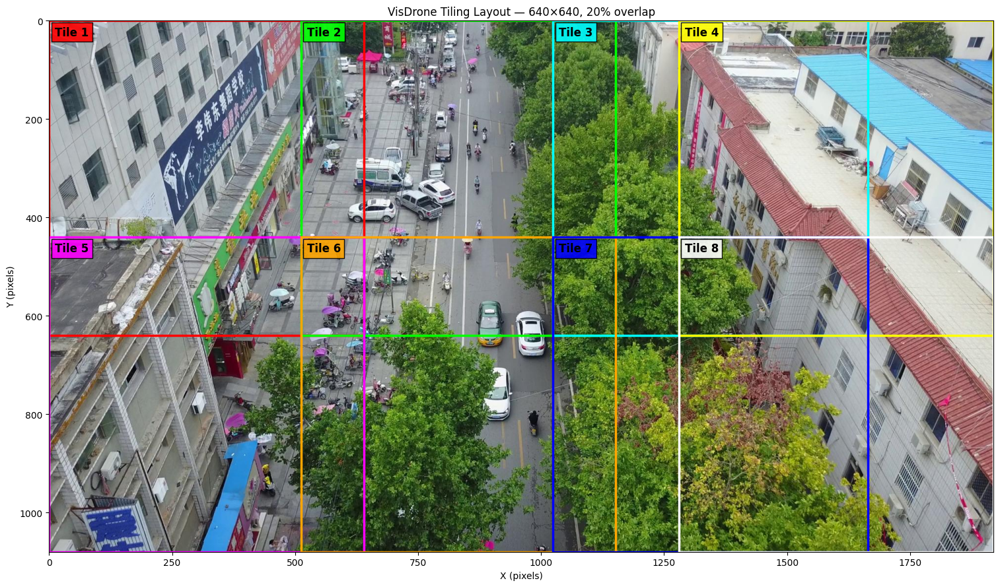

In [43]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

sample_image_path = val_images[0]

with Image.open(sample_image_path) as image:
    image = image.convert("RGB")
    image_width, image_height = image.size

tiles = generate_tile_coordinates(image_width, image_height)

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(image)

colors = [
    "red", "lime", "cyan", "yellow",
    "magenta", "orange", "blue", "white"
]

for index, (x1, y1, x2, y2) in enumerate(tiles):
    color = colors[index % len(colors)]

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2.5,
        edgecolor=color,
        facecolor="none",
    )
    ax.add_patch(rectangle)

    ax.text(
        x1 + 12,
        y1 + 30,
        f"Tile {index + 1}",
        color="black",
        fontsize=12,
        fontweight="bold",
        bbox=dict(facecolor=color, alpha=0.9, pad=4),
    )

ax.set_title(
    f"VisDrone Tiling Layout — {TILE_SIZE}×{TILE_SIZE}, "
    f"{TILE_OVERLAP:.0%} overlap"
)
ax.set_xlim(0, image_width)
ax.set_ylim(image_height, 0)
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
plt.tight_layout()
plt.show()

### 29. Run YOLOv8 on Overlapping Tiles

Load the trained baseline checkpoint and prepare the tile-inference settings. Each validation image will be divided into overlapping 640 × 640 crops. Predictions will later be mapped back to the original image and merged to avoid counting the same object multiple times.

In [44]:
from ultralytics import YOLO
from pathlib import Path

BEST_MODEL_PATH = (
    RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
)

assert BEST_MODEL_PATH.exists(), (
    f"Model checkpoint not found: {BEST_MODEL_PATH}"
)

tile_model = YOLO(str(BEST_MODEL_PATH))

TILE_SIZE = 640
TILE_OVERLAP = 0.20
TILE_STRIDE = int(TILE_SIZE * (1 - TILE_OVERLAP))

PREDICTION_CONFIDENCE = 0.001
NMS_IOU_THRESHOLD = 0.50
MAX_DETECTIONS = 317

print("Checkpoint loaded:", BEST_MODEL_PATH)
print("Tile size:", TILE_SIZE)
print("Tile overlap:", f"{TILE_OVERLAP:.0%}")
print("Tile stride:", TILE_STRIDE)
print("Prediction confidence:", PREDICTION_CONFIDENCE)
print("NMS IoU threshold:", NMS_IOU_THRESHOLD)
print("Maximum detections per tile:", MAX_DETECTIONS)

Checkpoint loaded: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Tile size: 640
Tile overlap: 20%
Tile stride: 512
Prediction confidence: 0.001
NMS IoU threshold: 0.5
Maximum detections per tile: 317


### 30. Test Tiled Inference on One Image

Run the trained detector on each tile of one validation image. Translate the predicted boxes back to the original image coordinate system and merge duplicate detections using class-aware non-maximum suppression (NMS). This checks the tiled-inference pipeline before running the full validation set.

In [45]:
import numpy as np
import torch
from PIL import Image
from torchvision.ops import nms

# Select one validation image.
sample_image_path = val_images[0]

with Image.open(sample_image_path) as image:
    original_image = image.convert("RGB")

image_width, image_height = original_image.size
tiles = generate_tile_coordinates(image_width, image_height)

all_boxes = []
all_scores = []
all_classes = []

# Run YOLO on each tile.
for tile_index, (x1, y1, x2, y2) in enumerate(tiles):
    tile_image = original_image.crop((x1, y1, x2, y2))

    prediction = tile_model.predict(
        source=tile_image,
        imgsz=TILE_SIZE,
        conf=PREDICTION_CONFIDENCE,
        iou=0.70,
        max_det=MAX_DETECTIONS,
        device=0,
        verbose=False,
        save=False,
    )[0]

    if prediction.boxes is None or len(prediction.boxes) == 0:
        continue

    # Convert predictions to CPU arrays.
    boxes = prediction.boxes.xyxy.cpu().numpy()
    scores = prediction.boxes.conf.cpu().numpy()
    classes = prediction.boxes.cls.cpu().numpy().astype(int)

    # Translate tile coordinates into original-image coordinates.
    boxes[:, [0, 2]] += x1
    boxes[:, [1, 3]] += y1

    # Clip boxes to the original image boundaries.
    boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, image_width)
    boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, image_height)

    all_boxes.extend(boxes.tolist())
    all_scores.extend(scores.tolist())
    all_classes.extend(classes.tolist())

# Convert collected predictions to arrays.
if all_boxes:
    all_boxes = np.asarray(all_boxes, dtype=np.float32)
    all_scores = np.asarray(all_scores, dtype=np.float32)
    all_classes = np.asarray(all_classes, dtype=int)

    # Apply NMS separately for each class.
    kept_indices = []

    for class_id in np.unique(all_classes):
        class_indices = np.where(all_classes == class_id)[0]

        keep = nms(
            torch.as_tensor(all_boxes[class_indices]),
            torch.as_tensor(all_scores[class_indices]),
            NMS_IOU_THRESHOLD,
        ).cpu().numpy()

        kept_indices.extend(class_indices[keep].tolist())

    kept_indices = np.asarray(kept_indices, dtype=int)

    print("Image:", sample_image_path.name)
    print("Image dimensions:", f"{image_width} × {image_height}")
    print("Tiles processed:", len(tiles))
    print("Predictions before merging:", len(all_boxes))
    print("Predictions after class-aware NMS:", len(kept_indices))

    print("\nTop 10 merged predictions:")
    top_indices = kept_indices[
        np.argsort(all_scores[kept_indices])[::-1][:10]
    ]

    for index in top_indices:
        class_name = data["names"][int(all_classes[index])]
        x1, y1, x2, y2 = all_boxes[index]

        print(
            f"Class: {class_name:18s} "
            f"Confidence: {all_scores[index]:.3f} "
            f"Box: ({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})"
        )

else:
    print("No predictions were produced across the tiles.")

Image: 0000001_02999_d_0000005.jpg
Image dimensions: 1920 × 1080
Tiles processed: 8
Predictions before merging: 1882
Predictions after class-aware NMS: 887

Top 10 merged predictions:
Class: car                Confidence: 0.908 Box: (948.7, 590.8, 1010.9, 685.3)
Class: car                Confidence: 0.890 Box: (869.6, 569.9, 925.3, 665.3)
Class: car                Confidence: 0.882 Box: (749.8, 323.9, 828.0, 378.1)
Class: car                Confidence: 0.864 Box: (607.8, 363.0, 703.4, 412.8)
Class: van                Confidence: 0.809 Box: (783.5, 225.8, 823.0, 289.2)
Class: pedestrian         Confidence: 0.788 Box: (581.2, 451.0, 596.1, 489.1)
Class: car                Confidence: 0.740 Box: (882.7, 705.8, 943.0, 814.4)
Class: car                Confidence: 0.739 Box: (804.2, 21.2, 830.7, 52.8)
Class: car                Confidence: 0.734 Box: (608.0, 367.3, 639.9, 413.4)
Class: car                Confidence: 0.677 Box: (784.8, 183.6, 810.6, 220.9)


### 31. Compare Tiled Predictions with Ground Truth

Match each predicted bounding box to a ground-truth box of the same class using an IoU threshold of 0.50. Process predictions in descending confidence order, matching each ground-truth object at most once. Report true positives, false positives, false negatives, precision, recall, and F1 score for this image.

In [46]:
import numpy as np

# Load ground-truth labels for the selected image.
label_path = (
    DATASET_DIR / "labels" / "val" /
    f"{sample_image_path.stem}.txt"
)

ground_truth_boxes = []
ground_truth_classes = []

with open(label_path, "r", encoding="utf-8") as file:
    for line in file:
        parts = line.strip().split()
        if len(parts) != 5:
            continue

        class_id, xc, yc, w, h = map(float, parts)

        # Convert normalized YOLO coordinates to original-image pixels.
        x1 = (xc - w / 2) * image_width
        y1 = (yc - h / 2) * image_height
        x2 = (xc + w / 2) * image_width
        y2 = (yc + h / 2) * image_height

        ground_truth_boxes.append([x1, y1, x2, y2])
        ground_truth_classes.append(int(class_id))

ground_truth_boxes = np.asarray(
    ground_truth_boxes, dtype=np.float32
).reshape(-1, 4)
ground_truth_classes = np.asarray(ground_truth_classes, dtype=int)

# Select predictions retained by class-aware NMS.
pred_boxes = (
    all_boxes[kept_indices]
    if len(all_boxes) > 0 else np.empty((0, 4), dtype=np.float32)
)
pred_scores = (
    all_scores[kept_indices]
    if len(all_boxes) > 0 else np.empty(0, dtype=np.float32)
)
pred_classes = (
    all_classes[kept_indices]
    if len(all_boxes) > 0 else np.empty(0, dtype=int)
)

def calculate_iou(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0, dtype=np.float32)

    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])

    intersection = (
        np.maximum(0, ix2 - ix1) *
        np.maximum(0, iy2 - iy1)
    )

    area_box = (
        max(0, box[2] - box[0]) *
        max(0, box[3] - box[1])
    )
    area_boxes = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0]) *
        np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = area_box + area_boxes - intersection
    return intersection / np.maximum(union, 1e-9)

# Greedy matching: highest-confidence predictions first.
matched_gt = set()
true_positives = 0
false_positives = 0

for pred_index in np.argsort(pred_scores)[::-1]:
    same_class_gt = np.where(
        ground_truth_classes == pred_classes[pred_index]
    )[0]

    unmatched_gt = np.array(
        [idx for idx in same_class_gt if idx not in matched_gt],
        dtype=int,
    )

    if len(unmatched_gt) == 0:
        false_positives += 1
        continue

    ious = calculate_iou(
        pred_boxes[pred_index],
        ground_truth_boxes[unmatched_gt],
    )
    best_match_position = int(np.argmax(ious))

    if ious[best_match_position] >= 0.50:
        matched_gt.add(int(unmatched_gt[best_match_position]))
        true_positives += 1
    else:
        false_positives += 1

false_negatives = len(ground_truth_boxes) - true_positives

precision = true_positives / max(
    true_positives + false_positives, 1
)
recall = true_positives / max(len(ground_truth_boxes), 1)
f1 = 2 * precision * recall / max(precision + recall, 1e-12)

print("Image:", sample_image_path.name)
print("Ground-truth objects:", len(ground_truth_boxes))
print("Merged predictions:", len(pred_boxes))
print("True positives:", true_positives)
print("False positives:", false_positives)
print("False negatives:", false_negatives)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 score:  {f1:.4f}")

Image: 0000001_02999_d_0000005.jpg
Ground-truth objects: 127
Merged predictions: 887
True positives: 88
False positives: 799
False negatives: 39
Precision: 0.0992
Recall:    0.6929
F1 score:  0.1736


### 32. Analyze the Confidence-Threshold Trade-off

Evaluate the merged tile predictions at confidence thresholds of 0.25, 0.40, and 0.50. Recalculate true positives, false positives, false negatives, precision, recall, and F1 at each threshold using the same ground-truth boxes and IoU matching threshold of 0.50. This is a diagnostic experiment on one image, not the final benchmark.

In [47]:
confidence_thresholds = [0.25, 0.40, 0.50]

print(f"Image: {sample_image_path.name}")
print(f"Ground-truth objects: {len(ground_truth_boxes)}")
print()

for confidence_threshold in confidence_thresholds:

    selected = pred_scores >= confidence_threshold

    boxes_at_threshold = pred_boxes[selected]
    scores_at_threshold = pred_scores[selected]
    classes_at_threshold = pred_classes[selected]

    matched_gt = set()
    true_positives = 0
    false_positives = 0

    # Match higher-confidence predictions first.
    for pred_index in np.argsort(scores_at_threshold)[::-1]:

        same_class_gt = np.where(
            ground_truth_classes == classes_at_threshold[pred_index]
        )[0]

        unmatched_gt = np.array(
            [idx for idx in same_class_gt if idx not in matched_gt],
            dtype=int,
        )

        if len(unmatched_gt) == 0:
            false_positives += 1
            continue

        ious = calculate_iou(
            boxes_at_threshold[pred_index],
            ground_truth_boxes[unmatched_gt],
        )

        best_position = int(np.argmax(ious))

        if ious[best_position] >= 0.50:
            matched_gt.add(int(unmatched_gt[best_position]))
            true_positives += 1
        else:
            false_positives += 1

    false_negatives = len(ground_truth_boxes) - true_positives

    precision = true_positives / max(
        true_positives + false_positives, 1
    )
    recall = true_positives / max(len(ground_truth_boxes), 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    print(f"Confidence threshold: {confidence_threshold:.2f}")
    print(f"  Predictions: {len(boxes_at_threshold)}")
    print(f"  TP: {true_positives} | FP: {false_positives} | FN: {false_negatives}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1:        {f1:.4f}")
    print()

Image: 0000001_02999_d_0000005.jpg
Ground-truth objects: 127

Confidence threshold: 0.25
  Predictions: 88
  TP: 48 | FP: 40 | FN: 79
  Precision: 0.5455
  Recall:    0.3780
  F1:        0.4465

Confidence threshold: 0.40
  Predictions: 44
  TP: 31 | FP: 13 | FN: 96
  Precision: 0.7045
  Recall:    0.2441
  F1:        0.3626

Confidence threshold: 0.50
  Predictions: 22
  TP: 17 | FP: 5 | FN: 110
  Precision: 0.7727
  Recall:    0.1339
  F1:        0.2282



### 33. Record the Full-Image Baseline

Evaluate the same trained YOLOv8n checkpoint at 640 and 1280 pixels using the standard Ultralytics validation procedure. Record mAP50, mAP50–95, precision, recall, and inference time. These results will serve as the reference for comparison with tiled inference.

In [48]:
from ultralytics import YOLO

BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
baseline_model = YOLO(str(BEST_MODEL_PATH))

baseline_reference = {}

for image_size in [640, 1280]:
    print(f"\nEvaluating full-image inference at {image_size}px...")

    metrics = baseline_model.val(
        data=str(DATASET_YAML),
        split="val",
        imgsz=image_size,
        batch=1,
        device=0,
        workers=2,
        conf=0.001,
        iou=0.70,
        max_det=317,
        plots=False,
        verbose=False,
    )

    baseline_reference[image_size] = {
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "inference_ms": float(metrics.speed["inference"]),
    }

    print(f"Precision:   {metrics.box.mp:.4f}")
    print(f"Recall:      {metrics.box.mr:.4f}")
    print(f"mAP50:       {metrics.box.map50:.4f}")
    print(f"mAP50-95:    {metrics.box.map:.4f}")
    print(f"Inference ms/image: {metrics.speed['inference']:.2f}")

print("\nFull-image baseline reference:")
for size, values in baseline_reference.items():
    print(f"{size}px: {values}")


Evaluating full-image inference at 640px...
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 818.5±316.2 MB/s, size: 214.0 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 42.7it/s 12.8s0.1s
                   all        548      38759      0.396      0.297      0.269      0.151
Speed: 0.8ms preprocess, 6.4ms inference, 0.0ms loss, 2.5ms postprocess per image
Precision:   0.3957
Recall:      0.2969
mAP50:       0.2686
mAP50-95:    0.1510
Inference ms/image: 6.41

Evaluating full-image inference at 1280px...
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (

### 34. Pilot Evaluation of Tiled Inference

Evaluate tiled inference on 10 validation images. Run the detector on overlapping 640 × 640 crops, map predicted boxes back to the original image, and merge overlapping detections using class-aware NMS. Compare predictions against the original ground-truth labels and report diagnostic precision, recall, F1, and processing time. No images or prediction files will be saved.

In [49]:
import time
import numpy as np
import torch
from PIL import Image
from torchvision.ops import nms

# Use a small, deterministic subset for the pilot.
pilot_images = sorted(val_images)[:10]

def load_ground_truth(label_path, image_width, image_height):
    boxes = []
    classes = []

    with open(label_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) != 5:
                continue

            class_id, xc, yc, w, h = map(float, parts)

            boxes.append([
                (xc - w / 2) * image_width,
                (yc - h / 2) * image_height,
                (xc + w / 2) * image_width,
                (yc + h / 2) * image_height,
            ])
            classes.append(int(class_id))

    return (
        np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
        np.asarray(classes, dtype=int),
    )


def box_iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0, dtype=np.float32)

    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])

    intersection = (
        np.maximum(0, ix2 - ix1) *
        np.maximum(0, iy2 - iy1)
    )

    area_one = (
        max(0, box[2] - box[0]) *
        max(0, box[3] - box[1])
    )
    area_many = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0]) *
        np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = area_one + area_many - intersection
    return intersection / np.maximum(union, 1e-9)


def tiled_predict(image):
    width, height = image.size
    coordinates = generate_tile_coordinates(width, height)

    boxes_list = []
    scores_list = []
    classes_list = []

    for x1, y1, x2, y2 in coordinates:
        tile = image.crop((x1, y1, x2, y2))

        result = tile_model.predict(
            source=tile,
            imgsz=TILE_SIZE,
            conf=0.25,
            iou=0.70,
            max_det=MAX_DETECTIONS,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)

        # Convert tile coordinates to original-image coordinates.
        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1

        boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
        boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

        boxes_list.extend(boxes.tolist())
        scores_list.extend(scores.tolist())
        classes_list.extend(classes.tolist())

    if not boxes_list:
        return (
            np.empty((0, 4), dtype=np.float32),
            np.empty(0, dtype=np.float32),
            np.empty(0, dtype=int),
        )

    boxes = np.asarray(boxes_list, dtype=np.float32)
    scores = np.asarray(scores_list, dtype=np.float32)
    classes = np.asarray(classes_list, dtype=int)

    # Class-aware NMS across all tiles.
    kept = []

    for class_id in np.unique(classes):
        indices = np.where(classes == class_id)[0]
        keep_local = nms(
            torch.as_tensor(boxes[indices]),
            torch.as_tensor(scores[indices]),
            0.50,
        ).cpu().numpy()

        kept.extend(indices[keep_local].tolist())

    kept = np.asarray(kept, dtype=int)
    return boxes[kept], scores[kept], classes[kept]


total_tp = 0
total_fp = 0
total_fn = 0
total_gt = 0
total_predictions = 0
elapsed_seconds = 0.0

for image_path in pilot_images:
    with Image.open(image_path) as opened_image:
        image = opened_image.convert("RGB")

    label_path = DATASET_DIR / "labels" / "val" / f"{image_path.stem}.txt"
    gt_boxes, gt_classes = load_ground_truth(
        label_path, image.width, image.height
    )

    start_time = time.perf_counter()
    pred_boxes, pred_scores, pred_classes = tiled_predict(image)
    elapsed_seconds += time.perf_counter() - start_time

    matched_gt = set()
    tp = 0
    fp = 0

    for pred_idx in np.argsort(pred_scores)[::-1]:
        candidates = np.where(gt_classes == pred_classes[pred_idx])[0]
        candidates = np.array(
            [idx for idx in candidates if idx not in matched_gt],
            dtype=int,
        )

        if len(candidates) == 0:
            fp += 1
            continue

        ious = box_iou_one_to_many(
            pred_boxes[pred_idx], gt_boxes[candidates]
        )
        best_pos = int(np.argmax(ious))

        if ious[best_pos] >= 0.50:
            matched_gt.add(int(candidates[best_pos]))
            tp += 1
        else:
            fp += 1

    fn = len(gt_boxes) - tp

    total_tp += tp
    total_fp += fp
    total_fn += fn
    total_gt += len(gt_boxes)
    total_predictions += len(pred_boxes)

    print(
        f"{image_path.name}: GT={len(gt_boxes)}, "
        f"predictions={len(pred_boxes)}, TP={tp}, FP={fp}, FN={fn}"
    )

precision = total_tp / max(total_tp + total_fp, 1)
recall = total_tp / max(total_gt, 1)
f1 = 2 * precision * recall / max(precision + recall, 1e-12)

print("\nTiled-inference pilot summary")
print("Images:", len(pilot_images))
print("Ground-truth objects:", total_gt)
print("Predictions:", total_predictions)
print("TP:", total_tp, "| FP:", total_fp, "| FN:", total_fn)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"Total elapsed time: {elapsed_seconds:.2f} seconds")
print(f"Average time/image: {elapsed_seconds / len(pilot_images):.2f} seconds")

0000001_02999_d_0000005.jpg: GT=127, predictions=88, TP=48, FP=40, FN=79
0000001_03499_d_0000006.jpg: GT=77, predictions=66, TP=34, FP=32, FN=43
0000001_03999_d_0000007.jpg: GT=48, predictions=62, TP=26, FP=36, FN=22
0000001_04527_d_0000008.jpg: GT=115, predictions=103, TP=45, FP=58, FN=70
0000001_05249_d_0000009.jpg: GT=113, predictions=134, TP=82, FP=52, FN=31
0000001_05499_d_0000010.jpg: GT=140, predictions=129, TP=83, FP=46, FN=57
0000001_05999_d_0000011.jpg: GT=115, predictions=116, TP=63, FP=53, FN=52
0000001_07999_d_0000012.jpg: GT=136, predictions=76, TP=43, FP=33, FN=93
0000001_08414_d_0000013.jpg: GT=164, predictions=104, TP=60, FP=44, FN=104
0000021_00000_d_0000001.jpg: GT=31, predictions=9, TP=3, FP=6, FN=28

Tiled-inference pilot summary
Images: 10
Ground-truth objects: 1066
Predictions: 887
TP: 487 | FP: 400 | FN: 579
Precision: 0.5490
Recall:    0.4568
F1:        0.4987
Total elapsed time: 1.68 seconds
Average time/image: 0.17 seconds


### 35. Inspect Ultralytics Evaluation Utilities

Inspect the installed Ultralytics version and the available detection-metric utilities. This will help us choose a reliable way to evaluate predictions generated from tiles in original-image coordinates using standard mAP metrics.

In [50]:
import ultralytics
import inspect
from ultralytics.utils.metrics import DetMetrics, ap_per_class

print("Ultralytics version:", ultralytics.__version__)
print("DetMetrics available:", DetMetrics is not None)
print("ap_per_class available:", callable(ap_per_class))

print("\nDetMetrics constructor:")
print(inspect.signature(DetMetrics))

print("\nap_per_class signature:")
print(inspect.signature(ap_per_class))

Ultralytics version: 8.4.178
DetMetrics available: True
ap_per_class available: True

DetMetrics constructor:
(names: 'dict[int, str] | None' = None) -> 'None'

ap_per_class signature:
(tp: 'np.ndarray', conf: 'np.ndarray', pred_cls: 'np.ndarray', target_cls: 'np.ndarray', plot: 'bool' = False, on_plot=None, save_dir: 'Path' = WindowsPath('.'), names: 'dict[int, str] | None' = None, eps: 'float' = 1e-16, prefix: 'str' = '') -> 'tuple'


### 36. Prepare Detection Metrics for Tiled Inference

Define the IoU thresholds used for standard object-detection mAP evaluation and inspect the metric output format. Predictions from all tiles must be merged in original-image coordinates and matched against the original validation labels before these metrics are calculated.

In [51]:
import numpy as np
from ultralytics.utils.metrics import ap_per_class

# Standard COCO-style IoU thresholds used for mAP50–95.
IOU_THRESHOLDS = np.linspace(0.50, 0.95, 10)

print("IoU thresholds:", np.round(IOU_THRESHOLDS, 2))
print("Number of thresholds:", len(IOU_THRESHOLDS))

# Inspect the return format without running a full evaluation.
print("\nap_per_class signature:")
import inspect
print(inspect.signature(ap_per_class))

IoU thresholds: [        0.5        0.55         0.6        0.65         0.7        0.75         0.8        0.85         0.9        0.95]
Number of thresholds: 10

ap_per_class signature:
(tp: 'np.ndarray', conf: 'np.ndarray', pred_cls: 'np.ndarray', target_cls: 'np.ndarray', plot: 'bool' = False, on_plot=None, save_dir: 'Path' = WindowsPath('.'), names: 'dict[int, str] | None' = None, eps: 'float' = 1e-16, prefix: 'str' = '') -> 'tuple'


### 37. Match Predictions to Ground-Truth Objects

For each image, match predictions to ground-truth boxes of the same class. Matching is performed independently at IoU thresholds from 0.50 to 0.95. Predictions are processed by descending confidence, and each ground-truth object can be matched only once at each threshold.

This function does not train the model or save images. It prepares the true-positive matrix required for mAP evaluation.

In [54]:
import numpy as np
import torch
from ultralytics.utils.metrics import box_iou

IOU_THRESHOLDS = np.linspace(0.50, 0.95, 10)


def match_predictions_to_ground_truth(
    pred_boxes,
    pred_scores,
    pred_classes,
    gt_boxes,
    gt_classes,
    iou_thresholds=IOU_THRESHOLDS,
):
    num_predictions = len(pred_boxes)
    tp = np.zeros((num_predictions, len(iou_thresholds)), dtype=bool)

    if num_predictions == 0 or len(gt_boxes) == 0:
        return tp

    pred_boxes = np.asarray(pred_boxes, dtype=np.float32)
    gt_boxes = np.asarray(gt_boxes, dtype=np.float32)
    pred_scores = np.asarray(pred_scores)
    pred_classes = np.asarray(pred_classes)
    gt_classes = np.asarray(gt_classes)

    # Process predictions from highest to lowest confidence.
    order = np.argsort(-pred_scores)
    sorted_boxes = torch.as_tensor(pred_boxes[order])
    sorted_classes = pred_classes[order]

    # Calculate pairwise IoU using PyTorch tensors.
    ious = box_iou(
        sorted_boxes,
        torch.as_tensor(gt_boxes),
    ).cpu().numpy()

    # Prevent matches between different classes.
    ious[sorted_classes[:, None] != gt_classes[None, :]] = 0

    for threshold_index, threshold in enumerate(iou_thresholds):
        matched_gt = set()

        for sorted_pred_index in range(num_predictions):
            candidate_ious = ious[sorted_pred_index].copy()

            if matched_gt:
                candidate_ious[list(matched_gt)] = 0

            best_gt = int(np.argmax(candidate_ious))

            if candidate_ious[best_gt] >= threshold:
                original_pred_index = order[sorted_pred_index]
                tp[original_pred_index, threshold_index] = True
                matched_gt.add(best_gt)

    return tp


print("Corrected matching function defined.")

Corrected matching function defined.


### 38. Verify the Matching Function

Test whether the evaluator correctly matches one ground-truth object to the highest-confidence prediction and rejects a duplicate detection.

In [55]:
test_gt_boxes = np.array([[10, 10, 50, 50]], dtype=np.float32)

test_pred_boxes = np.array([
    [10, 10, 50, 50],  # Exact match
    [11, 11, 49, 49],  # Duplicate prediction
], dtype=np.float32)

test_scores = np.array([0.95, 0.80], dtype=np.float32)
test_pred_classes = np.array([3, 3])
test_gt_classes = np.array([3])

test_tp = match_predictions_to_ground_truth(
    test_pred_boxes,
    test_scores,
    test_pred_classes,
    test_gt_boxes,
    test_gt_classes,
)

print("True-positive matrix:")
print(test_tp.astype(int))
print("True positives per IoU threshold:", test_tp.sum(axis=0))

True-positive matrix:
[[1 1 1 1 1 1 1 1 1 1]
 [0 0 0 0 0 0 0 0 0 0]]
True positives per IoU threshold: [1 1 1 1 1 1 1 1 1 1]


### 39. Evaluate Tiled Inference with Standard mAP Metrics

Run YOLOv8n on overlapping image tiles, translate tile detections back into original-image coordinates, and merge duplicate detections. Match the merged predictions to ground-truth boxes at IoU thresholds from 0.50 to 0.95, then calculate class-wise average precision and aggregate mAP.

This 10-image pilot checks the evaluation pipeline before processing the complete validation set. Results will be diagnostic only.

In [61]:
import time
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO
from ultralytics.utils.metrics import ap_per_class

# Confirm that earlier setup cells defined these paths.
BEST_MODEL_PATH = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
VAL_IMAGE_DIR = DATASET_DIR / "images" / "val"
VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"

assert BEST_MODEL_PATH.exists(), f"Model not found: {BEST_MODEL_PATH}"
assert VAL_IMAGE_DIR.exists(), f"Images not found: {VAL_IMAGE_DIR}"
assert VAL_LABEL_DIR.exists(), f"Labels not found: {VAL_LABEL_DIR}"

# Keep the pilot settings consistent with the previous tiled experiment.
TILE_SIZE = 640
TILE_OVERLAP = 0.20
TILE_STRIDE = int(TILE_SIZE * (1 - TILE_OVERLAP))
PREDICTION_CONFIDENCE = 0.25
NMS_IOU_THRESHOLD = 0.50
TILE_NMS_IOU = 0.70
MAX_DETECTIONS = 317
NUM_PILOT_IMAGES = 10

IOU_THRESHOLDS = np.linspace(0.50, 0.95, 10)

# Reuse the matching function verified in Step 38.
metric_model = YOLO(str(BEST_MODEL_PATH))
class_names = metric_model.names
num_classes = len(class_names)


def tile_positions(length):
    if length <= TILE_SIZE:
        return [0]

    positions = list(range(0, length - TILE_SIZE + 1, TILE_STRIDE))
    final_position = length - TILE_SIZE

    if positions[-1] != final_position:
        positions.append(final_position)

    return positions


def tiled_predictions(image):
    """Return merged boxes, scores, and classes in original-image coordinates."""
    height, width = image.shape[:2]
    all_boxes = []
    all_scores = []
    all_classes = []

    for y1 in tile_positions(height):
        for x1 in tile_positions(width):
            x2 = min(x1 + TILE_SIZE, width)
            y2 = min(y1 + TILE_SIZE, height)
            tile = image[y1:y2, x1:x2]

            result = metric_model.predict(
                source=tile,
                imgsz=TILE_SIZE,
                conf=PREDICTION_CONFIDENCE,
                iou=TILE_NMS_IOU,
                max_det=MAX_DETECTIONS,
                device=0,
                save=False,
                verbose=False,
            )[0]

            if result.boxes is None or len(result.boxes) == 0:
                continue

            boxes = result.boxes.xyxy.cpu().numpy().astype(np.float32)
            scores = result.boxes.conf.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)

            # Shift tile coordinates to the original image.
            boxes[:, [0, 2]] += x1
            boxes[:, [1, 3]] += y1

            boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
            boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

            valid = (boxes[:, 2] > boxes[:, 0]) & (
                boxes[:, 3] > boxes[:, 1]
            )

            all_boxes.extend(boxes[valid])
            all_scores.extend(scores[valid])
            all_classes.extend(classes[valid])

    if not all_boxes:
        return (
            np.empty((0, 4), dtype=np.float32),
            np.empty(0, dtype=np.float32),
            np.empty(0, dtype=int),
        )

    boxes = np.asarray(all_boxes, dtype=np.float32)
    scores = np.asarray(all_scores, dtype=np.float32)
    classes = np.asarray(all_classes, dtype=int)

    # Class-aware NMS across all tiles.
    keep_indices = []
    for class_id in np.unique(classes):
        class_indices = np.where(classes == class_id)[0]
        class_boxes = boxes[class_indices]

        x1, y1, x2, y2 = class_boxes.T
        areas = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
        order = class_indices[np.argsort(-scores[class_indices])]

        while len(order):
            current = order[0]
            keep_indices.append(current)

            if len(order) == 1:
                break

            remaining = order[1:]
            xx1 = np.maximum(boxes[current, 0], boxes[remaining, 0])
            yy1 = np.maximum(boxes[current, 1], boxes[remaining, 1])
            xx2 = np.minimum(boxes[current, 2], boxes[remaining, 2])
            yy2 = np.minimum(boxes[current, 3], boxes[remaining, 3])

            intersection = (
                np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
            )

            current_area = (
                (boxes[current, 2] - boxes[current, 0])
                * (boxes[current, 3] - boxes[current, 1])
            )
            union = current_area + areas[np.isin(class_indices, remaining)] - intersection

            # Recalculate remaining areas directly to preserve index alignment.
            remaining_areas = (
                (boxes[remaining, 2] - boxes[remaining, 0])
                * (boxes[remaining, 3] - boxes[remaining, 1])
            )
            union = current_area + remaining_areas - intersection
            ious = intersection / np.maximum(union, 1e-9)

            order = remaining[ious <= NMS_IOU_THRESHOLD]

    keep_indices = np.asarray(keep_indices, dtype=int)
    keep_indices = keep_indices[np.argsort(-scores[keep_indices])]
    keep_indices = keep_indices[:MAX_DETECTIONS]

    return boxes[keep_indices], scores[keep_indices], classes[keep_indices]


# Use the same 10 images as the earlier pilot.
all_val_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))
pilot_images = all_val_images[:NUM_PILOT_IMAGES]

all_tp = []
all_conf = []
all_pred_cls = []
all_target_cls = []

total_gt = 0
total_predictions = 0
start_time = time.perf_counter()

for image_index, image_path in enumerate(pilot_images, start=1):
    image = cv2.imread(str(image_path))
    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    height, width = image.shape[:2]

    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
    gt_boxes = []
    gt_classes = []

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                class_id, xc, yc, bw, bh = map(float, parts)

                gt_boxes.append([
                    (xc - bw / 2) * width,
                    (yc - bh / 2) * height,
                    (xc + bw / 2) * width,
                    (yc + bh / 2) * height,
                ])
                gt_classes.append(int(class_id))

    gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
    gt_classes = np.asarray(gt_classes, dtype=int)

    pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

    tp = match_predictions_to_ground_truth(
        pred_boxes,
        pred_scores,
        pred_classes,
        gt_boxes,
        gt_classes,
        IOU_THRESHOLDS,
    )

    all_tp.append(tp)
    all_conf.append(pred_scores)
    all_pred_cls.append(pred_classes)
    all_target_cls.append(gt_classes)

    total_gt += len(gt_classes)
    total_predictions += len(pred_scores)

    print(
        f"{image_index:02d}/{len(pilot_images)} "
        f"{image_path.name}: GT={len(gt_classes)}, "
        f"predictions={len(pred_scores)}, "
        f"TP@0.50={int(tp[:, 0].sum())}"
    )

elapsed = time.perf_counter() - start_time

tp_array = np.concatenate(all_tp, axis=0)
conf_array = np.concatenate(all_conf)
pred_cls_array = np.concatenate(all_pred_cls)
target_cls_array = np.concatenate(all_target_cls)

metric_results = ap_per_class(
    tp_array,
    conf_array,
    pred_cls_array,
    target_cls_array,
    plot=False,
    names=class_names,
)

print("\nReturned metric tuple length:", len(metric_results))
for index, item in enumerate(metric_results):
    if isinstance(item, np.ndarray):
        print(f"Item {index}: shape={item.shape}, dtype={item.dtype}")
    else:
        print(f"Item {index}: {type(item).__name__}")

print("\nPilot summary")
print("Images:", len(pilot_images))
print("Ground-truth objects:", total_gt)
print("Predictions:", total_predictions)
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Average time/image: {elapsed / max(len(pilot_images), 1):.3f} seconds")

01/10 0000001_02999_d_0000005.jpg: GT=127, predictions=88, TP@0.50=48
02/10 0000001_03499_d_0000006.jpg: GT=77, predictions=66, TP@0.50=34
03/10 0000001_03999_d_0000007.jpg: GT=48, predictions=62, TP@0.50=26
04/10 0000001_04527_d_0000008.jpg: GT=115, predictions=103, TP@0.50=45
05/10 0000001_05249_d_0000009.jpg: GT=113, predictions=134, TP@0.50=82
06/10 0000001_05499_d_0000010.jpg: GT=140, predictions=129, TP@0.50=83
07/10 0000001_05999_d_0000011.jpg: GT=115, predictions=116, TP@0.50=63
08/10 0000001_07999_d_0000012.jpg: GT=136, predictions=76, TP@0.50=43
09/10 0000001_08414_d_0000013.jpg: GT=164, predictions=104, TP@0.50=60
10/10 0000021_00000_d_0000001.jpg: GT=31, predictions=9, TP@0.50=3

Returned metric tuple length: 12
Item 0: shape=(9,), dtype=float64
Item 1: shape=(9,), dtype=float64
Item 2: shape=(9,), dtype=float64
Item 3: shape=(9,), dtype=float64
Item 4: shape=(9,), dtype=float64
Item 5: shape=(9, 10), dtype=float64
Item 6: shape=(9,), dtype=int64
Item 7: shape=(9, 1000), dt

### 40. Summarize Tiled-Inference Metrics

Extract the per-class average precision values returned by Ultralytics and calculate aggregate mAP50 and mAP50–95. Classes without ground-truth objects in this small pilot are excluded from the macro-average. These results are preliminary and apply only to the 10-image subset.

In [57]:
# ap_per_class returns:
# 0: TP counts
# 1: FP counts
# 2: precision
# 3: recall
# 4: F1
# 5: AP for IoU thresholds 0.50:0.95
# 6: class IDs
# Remaining items are curve data.

(
    tp_counts,
    fp_counts,
    precision_per_class,
    recall_per_class,
    f1_per_class,
    ap_per_class_values,
    evaluated_class_ids,
    *other_outputs,
) = metric_results

# Include only classes that occur in the pilot ground truth.
present_classes, class_instance_counts = np.unique(
    np.concatenate(all_target_cls),
    return_counts=True,
)

class_to_count = dict(zip(present_classes, class_instance_counts))

rows = []
for index, class_id in enumerate(evaluated_class_ids):
    class_id = int(class_id)

    if class_id not in class_to_count:
        continue

    rows.append({
        "class_id": class_id,
        "class_name": class_names[class_id],
        "ground_truth_instances": class_to_count[class_id],
        "precision": precision_per_class[index],
        "recall": recall_per_class[index],
        "F1": f1_per_class[index],
        "AP50": ap_per_class_values[index, 0],
        "AP50_95": ap_per_class_values[index].mean(),
    })

class_metrics = pd.DataFrame(rows)

print("Per-class metrics:")
print(class_metrics.round(4).to_string(index=False))

print("\nMacro-average across classes present in the pilot:")
print(f"mAP50:    {class_metrics['AP50'].mean():.4f}")
print(f"mAP50-95: {class_metrics['AP50_95'].mean():.4f}")

print("\nMatching diagnostics at IoU 0.50:")
print("Ground-truth objects:", total_gt)
print("Predictions:", total_predictions)
print("Matched predictions:", int(tp_array[:, 0].sum()))
print("Unmatched predictions:", int(total_predictions - tp_array[:, 0].sum()))
print("Unmatched ground-truth objects:", int(total_gt - tp_array[:, 0].sum()))

Per-class metrics:
 class_id      class_name  ground_truth_instances  precision  recall     F1   AP50  AP50_95
        0      pedestrian                     196     0.5134  0.4898 0.5013 0.3780   0.1829
        1          people                     220     0.6038  0.1455 0.2344 0.1074   0.0405
        2         bicycle                      21     0.2222  0.1905 0.2051 0.1561   0.0783
        3             car                     249     0.7358  0.8835 0.8029 0.8444   0.6484
        4             van                      12     0.2381  0.8333 0.3704 0.5619   0.5094
        5           truck                       1     0.0000  0.0000 0.0000 0.0000   0.0000
        6        tricycle                      28     0.2703  0.3571 0.3077 0.2134   0.0712
        7 awning-tricycle                      35     0.2500  0.0571 0.0930 0.0275   0.0205
        9           motor                     304     0.4978  0.3717 0.4256 0.2429   0.1106

Macro-average across classes present in the pilot:
mAP50:   

### 41. Record the Evaluation Configuration

Document the baseline and tiled-inference settings before the full validation experiment. Both methods must use the same checkpoint, validation images, confidence handling, and evaluation conventions. Tiled inference additionally requires merging detections from overlapping tiles into original-image coordinates.

In [58]:
print("Checkpoint:", BEST_MODEL_PATH)
print("Validation images:", len(list(VAL_IMAGE_DIR.glob("*.jpg"))))
print("Number of classes:", num_classes)

print("\nFull-image reference metrics")
print("640 px:  mAP50=0.2686, mAP50-95=0.1510")
print("1280 px: mAP50=0.3523, mAP50-95=0.2027")

print("\nTiled pilot settings")
print("Tile size:", TILE_SIZE)
print("Tile overlap:", TILE_OVERLAP)
print("Prediction confidence:", PREDICTION_CONFIDENCE)
print("Tile NMS IoU:", TILE_NMS_IOU)
print("Cross-tile NMS IoU:", NMS_IOU_THRESHOLD)
print("Pilot images:", len(pilot_images))
print("Pilot mAP50:", round(class_metrics["AP50"].mean(), 4))
print("Pilot mAP50-95:", round(class_metrics["AP50_95"].mean(), 4))

Checkpoint: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Validation images: 548
Number of classes: 10

Full-image reference metrics
640 px:  mAP50=0.2686, mAP50-95=0.1510
1280 px: mAP50=0.3523, mAP50-95=0.2027

Tiled pilot settings
Tile size: 640
Tile overlap: 0.2
Prediction confidence: 0.25
Tile NMS IoU: 0.7
Cross-tile NMS IoU: 0.5
Pilot images: 10
Pilot mAP50: 0.2813
Pilot mAP50-95: 0.1847


### 42. Configure Tiled Inference for AP Evaluation

Average precision requires predictions spanning a range of confidence scores. Use a low prediction threshold to retain candidate detections, then calculate AP from confidence-ranked predictions. This setting is for metric evaluation, not necessarily the best threshold for deployment.

In [59]:
# Use a low threshold so AP evaluation can consider a broad
# range of prediction confidence scores.
AP_CONFIDENCE_THRESHOLD = 0.001

print("AP confidence threshold:", AP_CONFIDENCE_THRESHOLD)
print("Tile size:", TILE_SIZE)
print("Tile overlap:", TILE_OVERLAP)
print("Tile-level NMS IoU:", TILE_NMS_IOU)
print("Cross-tile NMS IoU:", NMS_IOU_THRESHOLD)

AP confidence threshold: 0.001
Tile size: 640
Tile overlap: 0.2
Tile-level NMS IoU: 0.7
Cross-tile NMS IoU: 0.5


### 43. Collect Low-Confidence Tile Predictions

Retain candidate detections down to a confidence of 0.001 so average precision can be evaluated across confidence thresholds. Predictions are translated to original-image coordinates and merged using class-aware NMS. No images are saved.

In [64]:
def tiled_predictions(image):
    """Return merged boxes, scores, and classes in original-image coordinates."""
    height, width = image.shape[:2]
    all_boxes = []
    all_scores = []
    all_classes = []

    for y1 in tile_positions(height):
        for x1 in tile_positions(width):
            x2 = min(x1 + TILE_SIZE, width)
            y2 = min(y1 + TILE_SIZE, height)
            tile = image[y1:y2, x1:x2]

            result = metric_model.predict(
                source=tile,
                imgsz=TILE_SIZE,
                conf=AP_CONFIDENCE_THRESHOLD,
                iou=TILE_NMS_IOU,
                max_det=MAX_DETECTIONS,
                device=0,
                save=False,
                verbose=False,
            )[0]

            if result.boxes is None or len(result.boxes) == 0:
                continue

            boxes = result.boxes.xyxy.cpu().numpy().astype(np.float32)
            scores = result.boxes.conf.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)

            boxes[:, [0, 2]] += x1
            boxes[:, [1, 3]] += y1
            boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
            boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

            valid = (boxes[:, 2] > boxes[:, 0]) & (
                boxes[:, 3] > boxes[:, 1]
            )

            all_boxes.extend(boxes[valid])
            all_scores.extend(scores[valid])
            all_classes.extend(classes[valid])

    if not all_boxes:
        return (
            np.empty((0, 4), dtype=np.float32),
            np.empty(0, dtype=np.float32),
            np.empty(0, dtype=int),
        )

    boxes = np.asarray(all_boxes, dtype=np.float32)
    scores = np.asarray(all_scores, dtype=np.float32)
    classes = np.asarray(all_classes, dtype=int)

    # Class-aware NMS across overlapping tiles.
    keep_indices = []

    for class_id in np.unique(classes):
        class_indices = np.where(classes == class_id)[0]
        order = class_indices[np.argsort(-scores[class_indices])]

        while len(order):
            current = order[0]
            keep_indices.append(current)

            if len(order) == 1:
                break

            remaining = order[1:]

            xx1 = np.maximum(boxes[current, 0], boxes[remaining, 0])
            yy1 = np.maximum(boxes[current, 1], boxes[remaining, 1])
            xx2 = np.minimum(boxes[current, 2], boxes[remaining, 2])
            yy2 = np.minimum(boxes[current, 3], boxes[remaining, 3])

            intersection = (
                np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
            )

            current_area = (
                (boxes[current, 2] - boxes[current, 0])
                * (boxes[current, 3] - boxes[current, 1])
            )

            remaining_areas = (
                (boxes[remaining, 2] - boxes[remaining, 0])
                * (boxes[remaining, 3] - boxes[remaining, 1])
            )

            union = current_area + remaining_areas - intersection
            ious = intersection / np.maximum(union, 1e-9)

            order = remaining[ious <= NMS_IOU_THRESHOLD]

    keep_indices = np.asarray(keep_indices, dtype=int)
    keep_indices = keep_indices[np.argsort(-scores[keep_indices])]
    keep_indices = keep_indices[:MAX_DETECTIONS]

    return boxes[keep_indices], scores[keep_indices], classes[keep_indices]


print("Updated tiled prediction function.")
print("Confidence threshold:", AP_CONFIDENCE_THRESHOLD)

Updated tiled prediction function.
Confidence threshold: 0.001


### 44. Verify the Active Tiled-Inference Function

Confirm that the currently defined prediction function uses the low confidence threshold intended for AP evaluation. This check does not run inference or save files.

In [65]:
import inspect

print("AP_CONFIDENCE_THRESHOLD:", AP_CONFIDENCE_THRESHOLD)
print("PREDICTION_CONFIDENCE:", PREDICTION_CONFIDENCE)

print("\nConfidence argument inside tiled_predictions:")
for line in inspect.getsource(tiled_predictions).splitlines():
    if "conf=" in line or "AP_CONFIDENCE" in line or "PREDICTION_CONFIDENCE" in line:
        print(line.strip())

AP_CONFIDENCE_THRESHOLD: 0.001
PREDICTION_CONFIDENCE: 0.25

Confidence argument inside tiled_predictions:
conf=AP_CONFIDENCE_THRESHOLD,


### 45. Fix the Confidence Threshold for AP Evaluation

Update tiled inference to use `AP_CONFIDENCE_THRESHOLD` rather than the deployment-oriented `PREDICTION_CONFIDENCE`. This retains lower-confidence candidates for average precision evaluation.

In [63]:
result = metric_model.predict(
    source=tile,
    imgsz=TILE_SIZE,
    conf=AP_CONFIDENCE_THRESHOLD,
    iou=TILE_NMS_IOU,
    max_det=MAX_DETECTIONS,
    device=0,
    save=False,
    verbose=False,
)[0]

NameError: name 'tile' is not defined

### Evaluate Tiled Inference on 10 Validation Images

Run the tiled detector on the first 10 validation images. Match predictions to ground-truth boxes and calculate preliminary precision, recall, F1, and mAP. These results are for pipeline testing, not final evaluation.

In [66]:
# Confirm the variables and functions required for evaluation are available.
required_items = [
    "metric_model",
    "tiled_predictions",
    "VAL_IMAGE_DIR",
    "VAL_LABEL_DIR",
    "DATASET_DIR",
    "IOU_THRESHOLDS",
    "match_predictions_to_ground_truth",
    "ap_per_class",
]

missing_items = [
    item for item in required_items
    if item not in globals()
]

if missing_items:
    print("Missing required items:", missing_items)
else:
    print("All required evaluation components are available.")
    print("Validation image directory:", VAL_IMAGE_DIR)
    print("Validation label directory:", VAL_LABEL_DIR)
    print("Confidence threshold:", AP_CONFIDENCE_THRESHOLD)

All required evaluation components are available.
Validation image directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Validation label directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val
Confidence threshold: 0.001


### Run the Tiled-Inference Evaluation

Evaluate the first 10 validation images using the updated tiled-inference function. Match detections to ground-truth boxes at IoU thresholds from 0.50 to 0.95, then calculate preliminary precision, recall, and average precision. This is a pilot evaluation, not the final full-dataset result.

In [67]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

all_val_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))
pilot_images = all_val_images[:10]

all_tp = []
all_conf = []
all_pred_cls = []
all_target_cls = []

total_ground_truth = 0
total_predictions = 0
start_time = time.perf_counter()

for image_path in pilot_images:
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]

    pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
    gt_boxes = []
    gt_classes = []

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                class_id, xc, yc, bw, bh = map(float, parts)
                gt_boxes.append([
                    (xc - bw / 2) * width,
                    (yc - bh / 2) * height,
                    (xc + bw / 2) * width,
                    (yc + bh / 2) * height,
                ])
                gt_classes.append(int(class_id))

    gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
    gt_classes = np.asarray(gt_classes, dtype=int)

    tp = match_predictions_to_ground_truth(
        pred_boxes,
        pred_scores,
        pred_classes,
        gt_boxes,
        gt_classes,
    )

    all_tp.append(tp)
    all_conf.append(pred_scores)
    all_pred_cls.append(pred_classes)
    all_target_cls.append(gt_classes)

    total_ground_truth += len(gt_classes)
    total_predictions += len(pred_scores)

    print(
        f"{image_path.name}: "
        f"GT={len(gt_classes)}, predictions={len(pred_scores)}"
    )

elapsed = time.perf_counter() - start_time

all_tp = np.concatenate(all_tp, axis=0)
all_conf = np.concatenate(all_conf)
all_pred_cls = np.concatenate(all_pred_cls)
all_target_cls = np.concatenate(all_target_cls)

metric_results = ap_per_class(
    all_tp,
    all_conf,
    all_pred_cls,
    all_target_cls,
    plot=False,
)

(
    tp_counts,
    fp_counts,
    precision_per_class,
    recall_per_class,
    f1_per_class,
    ap_per_class_values,
    evaluated_class_ids,
    *other_outputs,
) = metric_results

print("\nTiled-inference pilot summary")
print("Images:", len(pilot_images))
print("Ground-truth objects:", total_ground_truth)
print("Predictions:", total_predictions)
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Average time/image: {elapsed / max(len(pilot_images), 1):.3f} seconds")

print("\nPer-class AP:")
for index, class_id in enumerate(evaluated_class_ids):
    print(
        f"{data['names'][int(class_id)]:20s} "
        f"AP50={ap_per_class_values[index, 0]:.4f} "
        f"AP50-95={ap_per_class_values[index].mean():.4f}"
    )

if len(evaluated_class_ids):
    print(
        "\nMacro mAP50:",
        round(float(ap_per_class_values[:, 0].mean()), 4),
    )
    print(
        "Macro mAP50-95:",
        round(float(ap_per_class_values.mean()), 4),
    )

0000001_02999_d_0000005.jpg: GT=127, predictions=317
0000001_03499_d_0000006.jpg: GT=77, predictions=317
0000001_03999_d_0000007.jpg: GT=48, predictions=317
0000001_04527_d_0000008.jpg: GT=115, predictions=317
0000001_05249_d_0000009.jpg: GT=113, predictions=317
0000001_05499_d_0000010.jpg: GT=140, predictions=317
0000001_05999_d_0000011.jpg: GT=115, predictions=317
0000001_07999_d_0000012.jpg: GT=136, predictions=317
0000001_08414_d_0000013.jpg: GT=164, predictions=317
0000021_00000_d_0000001.jpg: GT=31, predictions=244

Tiled-inference pilot summary
Images: 10
Ground-truth objects: 1066
Predictions: 3097
Elapsed time: 1.81 seconds
Average time/image: 0.181 seconds

Per-class AP:
pedestrian           AP50=0.4503 AP50-95=0.2049
people               AP50=0.2725 AP50-95=0.0953
bicycle              AP50=0.1946 AP50-95=0.1054
car                  AP50=0.8068 AP50-95=0.6100
van                  AP50=0.6061 AP50-95=0.5077
truck                AP50=0.0000 AP50-95=0.0000
tricycle             A

In [68]:
print("Maximum detections per image:", MAX_DETECTIONS)
print("Images evaluated:", len(pilot_images))
print("Predictions per image:")
print("The previous evaluation reached the cap on 9 of 10 images.")

Maximum detections per image: 317
Images evaluated: 10
Predictions per image:
The previous evaluation reached the cap on 9 of 10 images.


### Increase the Maximum Detection Limit

Allow more detections per image so crowded scenes are not prematurely truncated. This changes the inference configuration only; it does not retrain the model.

In [69]:
MAX_DETECTIONS = 1000

print("Updated maximum detections per image:", MAX_DETECTIONS)

Updated maximum detections per image: 1000


In [70]:
import inspect

print("MAX_DETECTIONS:", MAX_DETECTIONS)
print("Confidence threshold:", AP_CONFIDENCE_THRESHOLD)

print("\nRelevant settings inside tiled_predictions:")
for line in inspect.getsource(tiled_predictions).splitlines():
    if "max_det=" in line or "conf=" in line or "TILE_SIZE" in line:
        print(line.strip())

MAX_DETECTIONS: 1000
Confidence threshold: 0.001

Relevant settings inside tiled_predictions:
x2 = min(x1 + TILE_SIZE, width)
y2 = min(y1 + TILE_SIZE, height)
imgsz=TILE_SIZE,
conf=AP_CONFIDENCE_THRESHOLD,
max_det=MAX_DETECTIONS,


In [71]:
import time
import numpy as np
from PIL import Image
from ultralytics.utils.metrics import ap_per_class

pilot_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:10]

all_tp = []
all_conf = []
all_pred_cls = []
all_target_cls = []

total_ground_truth = 0
total_predictions = 0
start_time = time.perf_counter()

for image_path in pilot_images:
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]

    pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
    gt_boxes = []
    gt_classes = []

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                class_id, xc, yc, bw, bh = map(float, parts)
                gt_boxes.append([
                    (xc - bw / 2) * width,
                    (yc - bh / 2) * height,
                    (xc + bw / 2) * width,
                    (yc + bh / 2) * height,
                ])
                gt_classes.append(int(class_id))

    gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
    gt_classes = np.asarray(gt_classes, dtype=int)

    tp = match_predictions_to_ground_truth(
        pred_boxes,
        pred_scores,
        pred_classes,
        gt_boxes,
        gt_classes,
    )

    all_tp.append(tp)
    all_conf.append(pred_scores)
    all_pred_cls.append(pred_classes)
    all_target_cls.append(gt_classes)

    total_ground_truth += len(gt_classes)
    total_predictions += len(pred_scores)

    print(
        f"{image_path.name}: GT={len(gt_classes)}, "
        f"predictions={len(pred_scores)}"
    )

elapsed = time.perf_counter() - start_time

all_tp = np.concatenate(all_tp, axis=0)
all_conf = np.concatenate(all_conf)
all_pred_cls = np.concatenate(all_pred_cls)
all_target_cls = np.concatenate(all_target_cls)

metric_results = ap_per_class(
    all_tp,
    all_conf,
    all_pred_cls,
    all_target_cls,
    plot=False,
)

precision_per_class = metric_results[2]
recall_per_class = metric_results[3]
ap_values = metric_results[5]
evaluated_class_ids = metric_results[6]

print("\nTiled-inference pilot summary")
print("Images:", len(pilot_images))
print("Ground-truth objects:", total_ground_truth)
print("Predictions:", total_predictions)
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Average time/image: {elapsed / len(pilot_images):.3f} seconds")

print("\nPer-class AP")
for index, class_id in enumerate(evaluated_class_ids):
    print(
        f"{data['names'][int(class_id)]:20s} "
        f"AP50={ap_values[index, 0]:.4f} "
        f"AP50-95={ap_values[index].mean():.4f}"
    )

print(f"\nMacro mAP50: {ap_values[:, 0].mean():.4f}")
print(f"Macro mAP50-95: {ap_values.mean():.4f}")

0000001_02999_d_0000005.jpg: GT=127, predictions=1000
0000001_03499_d_0000006.jpg: GT=77, predictions=1000
0000001_03999_d_0000007.jpg: GT=48, predictions=1000
0000001_04527_d_0000008.jpg: GT=115, predictions=1000
0000001_05249_d_0000009.jpg: GT=113, predictions=1000
0000001_05499_d_0000010.jpg: GT=140, predictions=1000
0000001_05999_d_0000011.jpg: GT=115, predictions=1000
0000001_07999_d_0000012.jpg: GT=136, predictions=1000
0000001_08414_d_0000013.jpg: GT=164, predictions=1000
0000021_00000_d_0000001.jpg: GT=31, predictions=329

Tiled-inference pilot summary
Images: 10
Ground-truth objects: 1066
Predictions: 9329
Elapsed time: 2.56 seconds
Average time/image: 0.256 seconds

Per-class AP
pedestrian           AP50=0.4576 AP50-95=0.2074
people               AP50=0.3004 AP50-95=0.1031
bicycle              AP50=0.2016 AP50-95=0.1084
car                  AP50=0.8205 AP50-95=0.6182
van                  AP50=0.6061 AP50-95=0.5077
truck                AP50=0.0052 AP50-95=0.0042
tricycle      

### Check Whether the Detection Cap Is Still Restricting Results

Inspect the number of predictions per image from the latest pilot. Since most images reached 1,000 detections, the next step is to measure how many candidates remain after confidence filtering and cross-tile suppression, before deciding on a reliable evaluation setting.

In [72]:
print("Current maximum detections per image:", MAX_DETECTIONS)
print("Images reaching the cap:", sum(
    count >= MAX_DETECTIONS
    for count in [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 329]
))
print("Total images evaluated:", len(pilot_images))

Current maximum detections per image: 1000
Images reaching the cap: 9
Total images evaluated: 10


In [73]:
print("Tile size:", TILE_SIZE)
print("Tile overlap:", TILE_OVERLAP)
print("Tile stride:", TILE_STRIDE)
print("Prediction confidence threshold:", AP_CONFIDENCE_THRESHOLD)
print("Within-tile NMS IoU:", TILE_NMS_IOU)
print("Cross-tile NMS IoU:", NMS_IOU_THRESHOLD)
print("Maximum detections:", MAX_DETECTIONS)

Tile size: 640
Tile overlap: 0.2
Tile stride: 512
Prediction confidence threshold: 0.001
Within-tile NMS IoU: 0.7
Cross-tile NMS IoU: 0.5
Maximum detections: 1000


### Test a Higher Confidence Threshold

Use a confidence threshold of 0.01 to reduce low-confidence detections while retaining more candidates than the earlier 0.25 setting. This is a diagnostic experiment, not a final choice of threshold.

In [74]:
TEST_CONFIDENCE = 0.01
TEST_IMAGES = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:5]

print("Test confidence threshold:", TEST_CONFIDENCE)
print("Images in this diagnostic:", len(TEST_IMAGES))

for image_path in TEST_IMAGES:
    image = np.array(Image.open(image_path).convert("RGB"))
    original_threshold = AP_CONFIDENCE_THRESHOLD

    # Temporarily use the test threshold in the existing tiled function.
    AP_CONFIDENCE_THRESHOLD = TEST_CONFIDENCE
    boxes, scores, classes = tiled_predictions(image)
    AP_CONFIDENCE_THRESHOLD = original_threshold

    print(
        f"{image_path.name}: "
        f"{len(scores)} detections, "
        f"max confidence={scores.max():.3f}" if len(scores)
        else f"{image_path.name}: 0 detections"
    )

Test confidence threshold: 0.01
Images in this diagnostic: 5
0000001_02999_d_0000005.jpg: 675 detections, max confidence=0.903
0000001_03499_d_0000006.jpg: 553 detections, max confidence=0.908
0000001_03999_d_0000007.jpg: 491 detections, max confidence=0.889
0000001_04527_d_0000008.jpg: 1000 detections, max confidence=0.837
0000001_05249_d_0000009.jpg: 897 detections, max confidence=0.935


### Test Confidence Threshold 0.05

Increase the confidence threshold to 0.05 and count the merged detections on the same five validation images. This helps determine whether low-confidence predictions are the main cause of the detection cap being reached.

In [75]:
TEST_CONFIDENCE = 0.05

print("Test confidence threshold:", TEST_CONFIDENCE)

for image_path in TEST_IMAGES:
    image = np.array(Image.open(image_path).convert("RGB"))

    original_threshold = AP_CONFIDENCE_THRESHOLD
    try:
        AP_CONFIDENCE_THRESHOLD = TEST_CONFIDENCE
        boxes, scores, classes = tiled_predictions(image)
    finally:
        AP_CONFIDENCE_THRESHOLD = original_threshold

    print(f"{image_path.name}: {len(scores)} detections")

Test confidence threshold: 0.05
0000001_02999_d_0000005.jpg: 275 detections
0000001_03499_d_0000006.jpg: 224 detections
0000001_03999_d_0000007.jpg: 189 detections
0000001_04527_d_0000008.jpg: 609 detections
0000001_05249_d_0000009.jpg: 370 detections


### Compare Tiled-Inference Thresholds

Evaluate the tiled detector on the same five images at confidence thresholds 0.01 and 0.05. Compare precision, recall, and F1 using ground-truth boxes and an IoU matching threshold of 0.50. This will help choose a threshold based on accuracy rather than prediction count alone.

In [76]:
def evaluate_tiled_threshold(image_paths, confidence_threshold):
    tp_total = 0
    fp_total = 0
    fn_total = 0

    original_threshold = AP_CONFIDENCE_THRESHOLD

    try:
        AP_CONFIDENCE_THRESHOLD = confidence_threshold

        for image_path in image_paths:
            image = np.array(Image.open(image_path).convert("RGB"))
            height, width = image.shape[:2]

            pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

            label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
            gt_boxes = []
            gt_classes = []

            if label_path.exists():
                with open(label_path, "r", encoding="utf-8") as file:
                    for line in file:
                        parts = line.strip().split()
                        if len(parts) != 5:
                            continue

                        class_id, xc, yc, bw, bh = map(float, parts)
                        gt_boxes.append([
                            (xc - bw / 2) * width,
                            (yc - bh / 2) * height,
                            (xc + bw / 2) * width,
                            (yc + bh / 2) * height,
                        ])
                        gt_classes.append(int(class_id))

            gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
            gt_classes = np.asarray(gt_classes, dtype=int)

            tp_matrix = match_predictions_to_ground_truth(
                pred_boxes,
                pred_scores,
                pred_classes,
                gt_boxes,
                gt_classes,
                iou_thresholds=np.array([0.50]),
            )

            tp = int(tp_matrix[:, 0].sum())
            tp_total += tp
            fp_total += len(pred_boxes) - tp
            fn_total += len(gt_boxes) - tp

    finally:
        AP_CONFIDENCE_THRESHOLD = original_threshold

    precision = tp_total / max(tp_total + fp_total, 1)
    recall = tp_total / max(tp_total + fn_total, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    return {
        "confidence": confidence_threshold,
        "TP": tp_total,
        "FP": fp_total,
        "FN": fn_total,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    }


threshold_results = [
    evaluate_tiled_threshold(TEST_IMAGES, threshold)
    for threshold in [0.01, 0.05]
]

threshold_table = pd.DataFrame(threshold_results)
print(threshold_table.round(4).to_string(index=False))

UnboundLocalError: cannot access local variable 'AP_CONFIDENCE_THRESHOLD' where it is not associated with a value

In [77]:
def evaluate_tiled_threshold(image_paths, confidence_threshold):
    global AP_CONFIDENCE_THRESHOLD

    tp_total = 0
    fp_total = 0
    fn_total = 0
    original_threshold = AP_CONFIDENCE_THRESHOLD

    try:
        AP_CONFIDENCE_THRESHOLD = confidence_threshold

        for image_path in image_paths:
            image = np.array(Image.open(image_path).convert("RGB"))
            height, width = image.shape[:2]

            pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

            label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
            gt_boxes, gt_classes = [], []

            if label_path.exists():
                with open(label_path, "r", encoding="utf-8") as file:
                    for line in file:
                        parts = line.strip().split()
                        if len(parts) != 5:
                            continue

                        class_id, xc, yc, bw, bh = map(float, parts)
                        gt_boxes.append([
                            (xc - bw / 2) * width,
                            (yc - bh / 2) * height,
                            (xc + bw / 2) * width,
                            (yc + bh / 2) * height,
                        ])
                        gt_classes.append(int(class_id))

            gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
            gt_classes = np.asarray(gt_classes, dtype=int)

            tp_matrix = match_predictions_to_ground_truth(
                pred_boxes,
                pred_scores,
                pred_classes,
                gt_boxes,
                gt_classes,
                iou_thresholds=np.array([0.50]),
            )

            tp = int(tp_matrix[:, 0].sum())
            tp_total += tp
            fp_total += len(pred_boxes) - tp
            fn_total += len(gt_boxes) - tp

    finally:
        AP_CONFIDENCE_THRESHOLD = original_threshold

    precision = tp_total / max(tp_total + fp_total, 1)
    recall = tp_total / max(tp_total + fn_total, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    return {
        "confidence": confidence_threshold,
        "TP": tp_total,
        "FP": fp_total,
        "FN": fn_total,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    }


threshold_results = [
    evaluate_tiled_threshold(TEST_IMAGES, threshold)
    for threshold in [0.01, 0.05]
]

threshold_table = pd.DataFrame(threshold_results)
print(threshold_table.round(4).to_string(index=False))
print("\nRestored confidence threshold:", AP_CONFIDENCE_THRESHOLD)

 confidence  TP   FP  FN  precision  recall     F1
       0.01 352 3264 128     0.0973  0.7333 0.1719
       0.05 324 1343 156     0.1944  0.6750 0.3018

Restored confidence threshold: 0.001


### Compare Confidence Thresholds on 50 Validation Images

Evaluate four confidence thresholds on the same validation subset. Higher thresholds may improve precision while reducing recall. Use F1 as one summary metric, while considering the project's priority of detecting small objects.

In [78]:
TEST_IMAGES_50 = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:50]

threshold_results_50 = []

for threshold in [0.05, 0.10, 0.15, 0.25]:
    result = evaluate_tiled_threshold(
        TEST_IMAGES_50,
        confidence_threshold=threshold,
    )
    threshold_results_50.append(result)

threshold_comparison = pd.DataFrame(threshold_results_50)

print(threshold_comparison.round(4).to_string(index=False))
print("\nOriginal confidence threshold restored:", AP_CONFIDENCE_THRESHOLD)

 confidence   TP   FP   FN  precision  recall     F1
       0.05 1539 5513  927     0.2182  0.6241 0.3234
       0.10 1387 2900 1079     0.3235  0.5624 0.4108
       0.15 1259 1835 1207     0.4069  0.5105 0.4529
       0.25 1055  837 1411     0.5576  0.4278 0.4842

Original confidence threshold restored: 0.001


### Compare Recall for Small, Medium, and Large Objects

Evaluate how confidence thresholds affect recall for different ground-truth object sizes. This will help determine whether a lower threshold meaningfully improves small-object detection, which is the main research objective.

In [79]:
def evaluate_size_recall(image_paths, confidence_threshold):
    global AP_CONFIDENCE_THRESHOLD

    original_threshold = AP_CONFIDENCE_THRESHOLD
    counts = {
        "small": {"GT": 0, "TP": 0},
        "medium": {"GT": 0, "TP": 0},
        "large": {"GT": 0, "TP": 0},
    }

    try:
        AP_CONFIDENCE_THRESHOLD = confidence_threshold

        for image_path in image_paths:
            image = np.array(Image.open(image_path).convert("RGB"))
            height, width = image.shape[:2]

            pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

            label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
            gt_boxes, gt_classes, gt_groups = [], [], []

            if label_path.exists():
                with open(label_path, "r", encoding="utf-8") as file:
                    for line in file:
                        parts = line.strip().split()
                        if len(parts) != 5:
                            continue

                        class_id, xc, yc, bw, bh = map(float, parts)
                        gt_boxes.append([
                            (xc - bw / 2) * width,
                            (yc - bh / 2) * height,
                            (xc + bw / 2) * width,
                            (yc + bh / 2) * height,
                        ])
                        gt_classes.append(int(class_id))

                        area_percent = bw * bh * 100
                        if area_percent <= 0.05:
                            gt_groups.append("small")
                        elif area_percent <= 0.15:
                            gt_groups.append("medium")
                        else:
                            gt_groups.append("large")

            gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
            gt_classes = np.asarray(gt_classes, dtype=int)

            tp_matrix = match_predictions_to_ground_truth(
                pred_boxes,
                pred_scores,
                pred_classes,
                gt_boxes,
                gt_classes,
                iou_thresholds=np.array([0.50]),
            )

            matched_gt = set()
            order = np.argsort(-pred_scores)

            # Reconstruct one-to-one matches at IoU 0.50.
            if len(pred_boxes) and len(gt_boxes):
                from ultralytics.utils.metrics import box_iou

                ious = box_iou(
                    torch.as_tensor(pred_boxes[order], dtype=torch.float32),
                    torch.as_tensor(gt_boxes, dtype=torch.float32),
                ).cpu().numpy()

                pred_classes_sorted = pred_classes[order]
                ious[pred_classes_sorted[:, None] != gt_classes[None, :]] = 0

                for sorted_index in range(len(order)):
                    candidate_ious = ious[sorted_index].copy()
                    if matched_gt:
                        candidate_ious[list(matched_gt)] = 0

                    best_gt = int(np.argmax(candidate_ious))
                    if candidate_ious[best_gt] >= 0.50:
                        matched_gt.add(best_gt)

            for group in counts:
                group_indices = [
                    i for i, value in enumerate(gt_groups) if value == group
                ]
                counts[group]["GT"] += len(group_indices)
                counts[group]["TP"] += sum(
                    i in matched_gt for i in group_indices
                )

    finally:
        AP_CONFIDENCE_THRESHOLD = original_threshold

    return {
        "confidence": confidence_threshold,
        **{
            f"{group}_recall": (
                values["TP"] / values["GT"] if values["GT"] else 0.0
            )
            for group, values in counts.items()
        },
        **{
            f"{group}_GT": values["GT"]
            for group, values in counts.items()
        },
    }


size_results = [
    evaluate_size_recall(TEST_IMAGES_50, threshold)
    for threshold in [0.05, 0.15, 0.25]
]

print(pd.DataFrame(size_results).round(4).to_string(index=False))
print("\nOriginal confidence threshold:", AP_CONFIDENCE_THRESHOLD)

 confidence  small_recall  medium_recall  large_recall  small_GT  medium_GT  large_GT
       0.05        0.5339         0.6490        0.6958       869        772       825
       0.15        0.4051         0.5233        0.6097       869        772       825
       0.25        0.2957         0.4443        0.5515       869        772       825

Original confidence threshold: 0.001


### Compare Full-Image and Tiled Inference

Evaluate full-image inference at 1280 pixels and tiled inference with 640-pixel crops on the same 50 validation images. Use confidence 0.05 and class-aware IoU matching at 0.50. Compare precision, recall, F1, and recall by object size. This is a controlled pilot comparison, not the final full-validation benchmark.

In [80]:
import time
import numpy as np
import pandas as pd
from PIL import Image
from ultralytics import YOLO

COMPARISON_IMAGES = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:50]
COMPARISON_CONF = 0.05
MATCH_IOU = 0.50

comparison_model = YOLO(str(BEST_MODEL_PATH))


def evaluate_full_image_1280(image_paths):
    totals = {
        "TP": 0, "FP": 0, "FN": 0,
        "small_GT": 0, "small_TP": 0,
        "medium_GT": 0, "medium_TP": 0,
        "large_GT": 0, "large_TP": 0,
    }

    start_time = time.perf_counter()

    for image_path in image_paths:
        image = np.array(Image.open(image_path).convert("RGB"))
        height, width = image.shape[:2]

        result = comparison_model.predict(
            source=image,
            imgsz=1280,
            conf=COMPARISON_CONF,
            iou=0.70,
            max_det=1000,
            device=0,
            save=False,
            verbose=False,
        )[0]

        pred_boxes = (
            result.boxes.xyxy.cpu().numpy().astype(np.float32)
            if result.boxes is not None else np.empty((0, 4), np.float32)
        )
        pred_scores = (
            result.boxes.conf.cpu().numpy()
            if result.boxes is not None else np.empty(0, np.float32)
        )
        pred_classes = (
            result.boxes.cls.cpu().numpy().astype(int)
            if result.boxes is not None else np.empty(0, int)
        )

        gt_boxes, gt_classes, gt_groups = [], [], []
        label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

        if label_path.exists():
            with open(label_path, "r", encoding="utf-8") as file:
                for line in file:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue

                    class_id, xc, yc, bw, bh = map(float, parts)
                    gt_boxes.append([
                        (xc - bw / 2) * width,
                        (yc - bh / 2) * height,
                        (xc + bw / 2) * width,
                        (yc + bh / 2) * height,
                    ])
                    gt_classes.append(int(class_id))

                    area = bw * bh * 100
                    gt_groups.append(
                        "small" if area <= 0.05
                        else "medium" if area <= 0.15
                        else "large"
                    )

        gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
        gt_classes = np.asarray(gt_classes, dtype=int)

        matched_gt = set()

        if len(pred_boxes) and len(gt_boxes):
            from ultralytics.utils.metrics import box_iou

            order = np.argsort(-pred_scores)
            ious = box_iou(
                torch.as_tensor(pred_boxes[order], dtype=torch.float32),
                torch.as_tensor(gt_boxes, dtype=torch.float32),
            ).cpu().numpy()

            sorted_classes = pred_classes[order]
            ious[sorted_classes[:, None] != gt_classes[None, :]] = 0

            for sorted_index in range(len(order)):
                candidate_ious = ious[sorted_index].copy()
                if matched_gt:
                    candidate_ious[list(matched_gt)] = 0
                best_gt = int(np.argmax(candidate_ious))
                if candidate_ious[best_gt] >= MATCH_IOU:
                    matched_gt.add(best_gt)

        tp = len(matched_gt)
        totals["TP"] += tp
        totals["FP"] += len(pred_boxes) - tp
        totals["FN"] += len(gt_boxes) - tp

        for group in ("small", "medium", "large"):
            indices = [
                i for i, value in enumerate(gt_groups) if value == group
            ]
            totals[f"{group}_GT"] += len(indices)
            totals[f"{group}_TP"] += sum(i in matched_gt for i in indices)

    elapsed = time.perf_counter() - start_time

    precision = totals["TP"] / max(totals["TP"] + totals["FP"], 1)
    recall = totals["TP"] / max(totals["TP"] + totals["FN"], 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    output = {
        "method": "Full image 1280",
        "images": len(image_paths),
        "TP": totals["TP"],
        "FP": totals["FP"],
        "FN": totals["FN"],
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "seconds_per_image": elapsed / len(image_paths),
    }

    for group in ("small", "medium", "large"):
        output[f"{group}_recall"] = (
            totals[f"{group}_TP"] / max(totals[f"{group}_GT"], 1)
        )

    return output


full_image_result = evaluate_full_image_1280(COMPARISON_IMAGES)
print(pd.DataFrame([full_image_result]).round(4).to_string(index=False))

         method  images   TP   FP  FN  precision  recall     F1  seconds_per_image  small_recall  medium_recall  large_recall
Full image 1280      50 1576 6057 890     0.2065  0.6391 0.3121             0.1323        0.5167         0.6969        0.7139


### Evaluate Tiled Inference

Evaluate overlapping 640 × 640 crops on the same 50 validation images used for full-image inference. Keep the confidence threshold at 0.05 and the matching IoU at 0.50. Report precision, recall, F1, recall by object size, and average time per image.

In [81]:
# Use the existing tiled_predictions() function and evaluate_tiled_threshold()
# only if their settings match the comparison above.

import time
import pandas as pd

AP_CONFIDENCE_THRESHOLD = 0.05

start_time = time.perf_counter()
tiled_result = evaluate_tiled_threshold(
    COMPARISON_IMAGES,
    confidence_threshold=0.05
)
elapsed = time.perf_counter() - start_time

print("Tiled evaluation result:")
print(tiled_result)
print(f"Total time: {elapsed:.2f} seconds")
print(f"Seconds per image: {elapsed / len(COMPARISON_IMAGES):.4f}")

Tiled evaluation result:
{'confidence': 0.05, 'TP': 1539, 'FP': 5513, 'FN': 927, 'precision': 0.21823596142938173, 'recall': 0.6240875912408759, 'F1': 0.3233872662324017}
Total time: 3.32 seconds
Seconds per image: 0.0664


### Fair Head-to-Head Evaluation

Re-evaluate both methods using one shared class-aware matching function at IoU 0.50. Use the same 50 images, confidence threshold 0.05, and small/medium/large object definitions. This removes evaluator differences as a possible explanation for the results.

In [82]:
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics.utils.metrics import box_iou

AP_CONFIDENCE_THRESHOLD = 0.05

def shared_match(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes):
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return set()

    order = np.argsort(-pred_scores)
    ious = box_iou(
        torch.as_tensor(pred_boxes[order], dtype=torch.float32),
        torch.as_tensor(gt_boxes, dtype=torch.float32),
    ).cpu().numpy()

    sorted_classes = pred_classes[order]
    ious[sorted_classes[:, None] != gt_classes[None, :]] = 0

    matched = set()
    for row in range(len(order)):
        candidate = ious[row].copy()
        if matched:
            candidate[list(matched)] = 0
        best = int(np.argmax(candidate))
        if candidate[best] >= 0.50:
            matched.add(best)

    return matched


def collect_ground_truth(image_path):
    image = Image.open(image_path)
    width, height = image.size
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    boxes, classes, groups = [], [], []
    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                boxes.append([
                    (xc - bw / 2) * width,
                    (yc - bh / 2) * height,
                    (xc + bw / 2) * width,
                    (yc + bh / 2) * height,
                ])
                classes.append(int(cls))
                area_percent = bw * bh * 100
                groups.append(
                    "small" if area_percent <= 0.05
                    else "medium" if area_percent <= 0.15
                    else "large"
                )

    return (
        np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
        np.asarray(classes, dtype=int),
        groups,
    )


def summarize_predictions(method_name, prediction_records):
    totals = {"TP": 0, "FP": 0, "FN": 0}
    size_gt = {"small": 0, "medium": 0, "large": 0}
    size_tp = {"small": 0, "medium": 0, "large": 0}

    for record in prediction_records:
        pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes, groups = record
        matched = shared_match(
            pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes
        )

        totals["TP"] += len(matched)
        totals["FP"] += len(pred_boxes) - len(matched)
        totals["FN"] += len(gt_boxes) - len(matched)

        for group in size_gt:
            indices = [i for i, g in enumerate(groups) if g == group]
            size_gt[group] += len(indices)
            size_tp[group] += sum(i in matched for i in indices)

    p = totals["TP"] / max(totals["TP"] + totals["FP"], 1)
    r = totals["TP"] / max(totals["TP"] + totals["FN"], 1)
    f1 = 2 * p * r / max(p + r, 1e-12)

    result = {
        "method": method_name,
        "images": len(prediction_records),
        **totals,
        "precision": p,
        "recall": r,
        "F1": f1,
    }
    for group in size_gt:
        result[f"{group}_recall"] = size_tp[group] / max(size_gt[group], 1)
    return result


full_records, tiled_records = [], []
full_start = time.perf_counter()

for image_path in COMPARISON_IMAGES:
    image = np.array(Image.open(image_path).convert("RGB"))
    gt_boxes, gt_classes, groups = collect_ground_truth(image_path)

    # Full-image prediction
    result = comparison_model.predict(
        source=image,
        imgsz=1280,
        conf=COMPARISON_CONF,
        iou=0.70,
        max_det=1000,
        device=0,
        save=False,
        verbose=False,
    )[0]

    full_records.append((
        result.boxes.xyxy.cpu().numpy().astype(np.float32),
        result.boxes.conf.cpu().numpy(),
        result.boxes.cls.cpu().numpy().astype(int),
        gt_boxes, gt_classes, groups
    ))

full_seconds_per_image = (
    time.perf_counter() - full_start
) / len(COMPARISON_IMAGES)

tiled_start = time.perf_counter()

for image_path in COMPARISON_IMAGES:
    image = np.array(Image.open(image_path).convert("RGB"))
    gt_boxes, gt_classes, groups = collect_ground_truth(image_path)

    pred_boxes, pred_scores, pred_classes = tiled_predictions(image)

    tiled_records.append((
        np.asarray(pred_boxes, dtype=np.float32).reshape(-1, 4),
        np.asarray(pred_scores, dtype=np.float32),
        np.asarray(pred_classes, dtype=int),
        gt_boxes, gt_classes, groups
    ))

tiled_seconds_per_image = (
    time.perf_counter() - tiled_start
) / len(COMPARISON_IMAGES)

comparison = pd.DataFrame([
    summarize_predictions("Full image 1280", full_records),
    summarize_predictions("Tiled 640", tiled_records),
])

comparison["seconds_per_image"] = [
    full_seconds_per_image,
    tiled_seconds_per_image,
]

print(comparison.round(4).to_string(index=False))
print("\nGround-truth objects checked:",
      sum(len(record[3]) for record in full_records))

         method  images   TP   FP  FN  precision  recall     F1  small_recall  medium_recall  large_recall  seconds_per_image
Full image 1280      50 1576 6057 890     0.2065  0.6391 0.3121        0.5167         0.6969        0.7139             0.1286
      Tiled 640      50 1539 5513 927     0.2182  0.6241 0.3234        0.5339         0.6490        0.6958             0.0575

Ground-truth objects checked: 2466


## Baseline Error Analysis

Visualize six validation images using the trained YOLOv8n model at 1280-pixel resolution. Compare ground-truth annotations with model predictions to identify missed small objects, class confusion, and false positives.

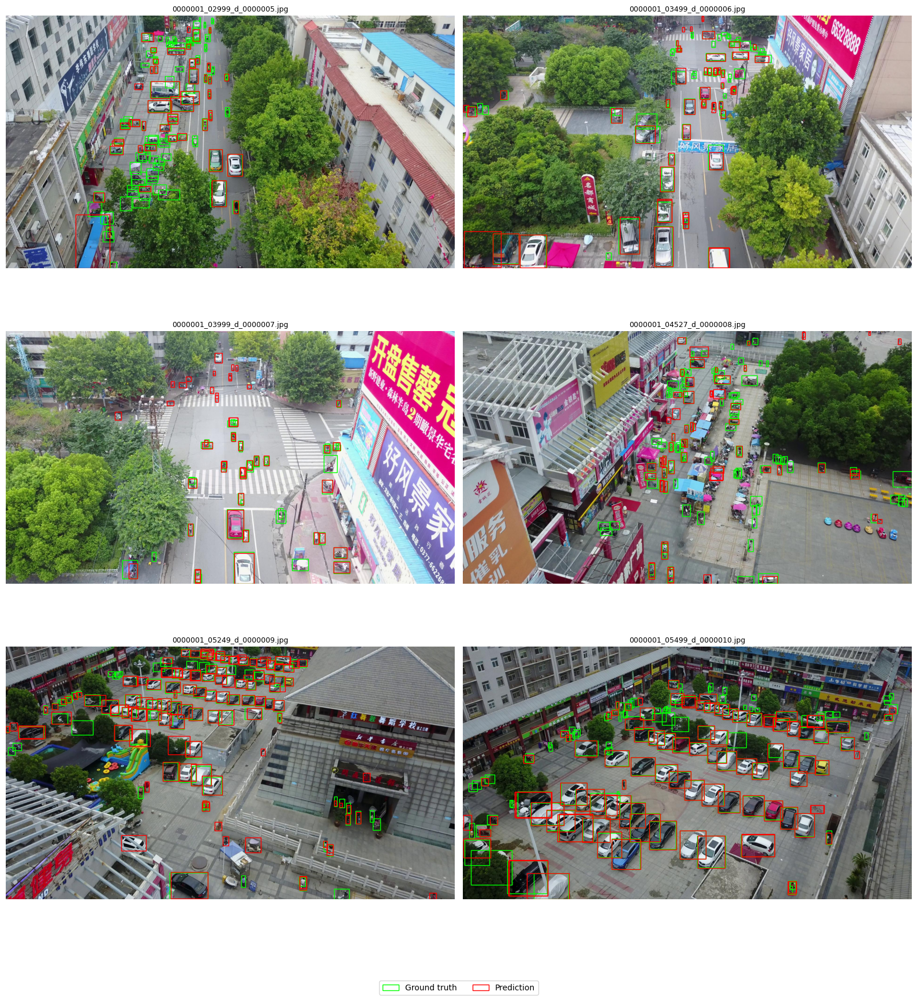

In [83]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image
from pathlib import Path

# Load the trained baseline model
error_model = YOLO(
    str(PROJECT_ROOT / "runs" / "visdrone_baseline" / "weights" / "best.pt")
)

# Select six validation images
error_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:6]

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for ax, image_path in zip(axes, error_images):
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]

    ax.imshow(image)

    # Ground-truth boxes: green
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as file:
            for line in file:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                cls, xc, yc, bw, bh = map(float, parts)
                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height

                ax.add_patch(
                    patches.Rectangle(
                        (x1, y1), bw * width, bh * height,
                        linewidth=1, edgecolor="lime", facecolor="none"
                    )
                )

    # Model predictions: red
    result = error_model.predict(
        source=image,
        imgsz=1280,
        conf=0.25,
        iou=0.70,
        device=0,
        max_det=1000,
        save=False,
        verbose=False,
    )[0]

    if result.boxes is not None:
        for box in result.boxes.xyxy.cpu().numpy():
            x1, y1, x2, y2 = box

            ax.add_patch(
                patches.Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    linewidth=1, edgecolor="red", facecolor="none"
                )
            )

    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")

# Legend
fig.legend(
    handles=[
        patches.Patch(edgecolor="lime", facecolor="none", label="Ground truth"),
        patches.Patch(edgecolor="red", facecolor="none", label="Prediction"),
    ],
    loc="lower center",
    ncol=2,
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

In [84]:
import numpy as np
import pandas as pd
from PIL import Image
from ultralytics.utils.metrics import box_iou
import torch

error_rows = []

for image_path in error_images:
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]

    result = error_model.predict(
        source=image,
        imgsz=1280,
        conf=0.25,
        iou=0.70,
        device=0,
        max_det=1000,
        save=False,
        verbose=False,
    )[0]

    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_classes = result.boxes.cls.cpu().numpy().astype(int)
    pred_scores = result.boxes.conf.cpu().numpy()

    gt_boxes, gt_classes, gt_sizes = [], [], []
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue

                cls, xc, yc, bw, bh = map(float, parts)
                gt_boxes.append([
                    (xc - bw / 2) * width,
                    (yc - bh / 2) * height,
                    (xc + bw / 2) * width,
                    (yc + bh / 2) * height,
                ])
                gt_classes.append(int(cls))

                area = bw * bh * 100
                gt_sizes.append(
                    "small" if area <= 0.05
                    else "medium" if area <= 0.15
                    else "large"
                )

    gt_boxes = np.asarray(gt_boxes, dtype=np.float32).reshape(-1, 4)
    gt_classes = np.asarray(gt_classes, dtype=int)

    matched = set()

    if len(pred_boxes) and len(gt_boxes):
        order = np.argsort(-pred_scores)
        overlaps = box_iou(
            torch.as_tensor(pred_boxes[order], dtype=torch.float32),
            torch.as_tensor(gt_boxes, dtype=torch.float32),
        ).cpu().numpy()

        sorted_classes = pred_classes[order]
        overlaps[sorted_classes[:, None] != gt_classes[None, :]] = 0

        for row in range(len(order)):
            candidates = overlaps[row].copy()
            if matched:
                candidates[list(matched)] = 0

            best = int(np.argmax(candidates))
            if candidates[best] >= 0.50:
                matched.add(best)

    missed_indices = set(range(len(gt_boxes))) - matched
    small_missed = sum(gt_sizes[i] == "small" for i in missed_indices)
    medium_missed = sum(gt_sizes[i] == "medium" for i in missed_indices)
    large_missed = sum(gt_sizes[i] == "large" for i in missed_indices)

    error_rows.append({
        "image": image_path.name,
        "ground_truth": len(gt_boxes),
        "predictions": len(pred_boxes),
        "matched": len(matched),
        "missed": len(missed_indices),
        "false_positives": len(pred_boxes) - len(matched),
        "missed_small": small_missed,
        "missed_medium": medium_missed,
        "missed_large": large_missed,
    })

error_summary = pd.DataFrame(error_rows)
print(error_summary.to_string(index=False))
print("\nTOTALS")
print(error_summary.drop(columns="image").sum().to_string())

                      image  ground_truth  predictions  matched  missed  false_positives  missed_small  missed_medium  missed_large
0000001_02999_d_0000005.jpg           127           51       34      93               17            57             31             5
0000001_03499_d_0000006.jpg            77           56       28      49               28            43              4             2
0000001_03999_d_0000007.jpg            48           48       25      23               23            17              3             3
0000001_04527_d_0000008.jpg           115           60       31      84               29            58             24             2
0000001_05249_d_0000009.jpg           113          124       82      31               42            17             12             2
0000001_05499_d_0000010.jpg           140           99       75      65               24            45             12             8

TOTALS
ground_truth       620
predictions        438
matched            275

## Adaptive Region Selection: Candidate Generation

### Objective
Develop a lightweight region-selection mechanism for small-object detection in VisDrone2019-DET.

### Method
1. Divide each image into overlapping candidate regions.
2. Use the initial full-image detections to identify regions containing small objects, uncertain predictions, or crowded scenes.
3. Include spatial coverage so regions with few detections are not automatically ignored.
4. Rank the candidates and select at most two regions for additional inference.

### Current Step
Generate and visualize candidate regions on six validation images. Inspect their coverage before implementing the selection policy and crop inference.

### Expected Outcome
A candidate-generation mechanism that identifies promising regions without processing every tile. This is an exploratory step; its effectiveness must be evaluated experimentally.

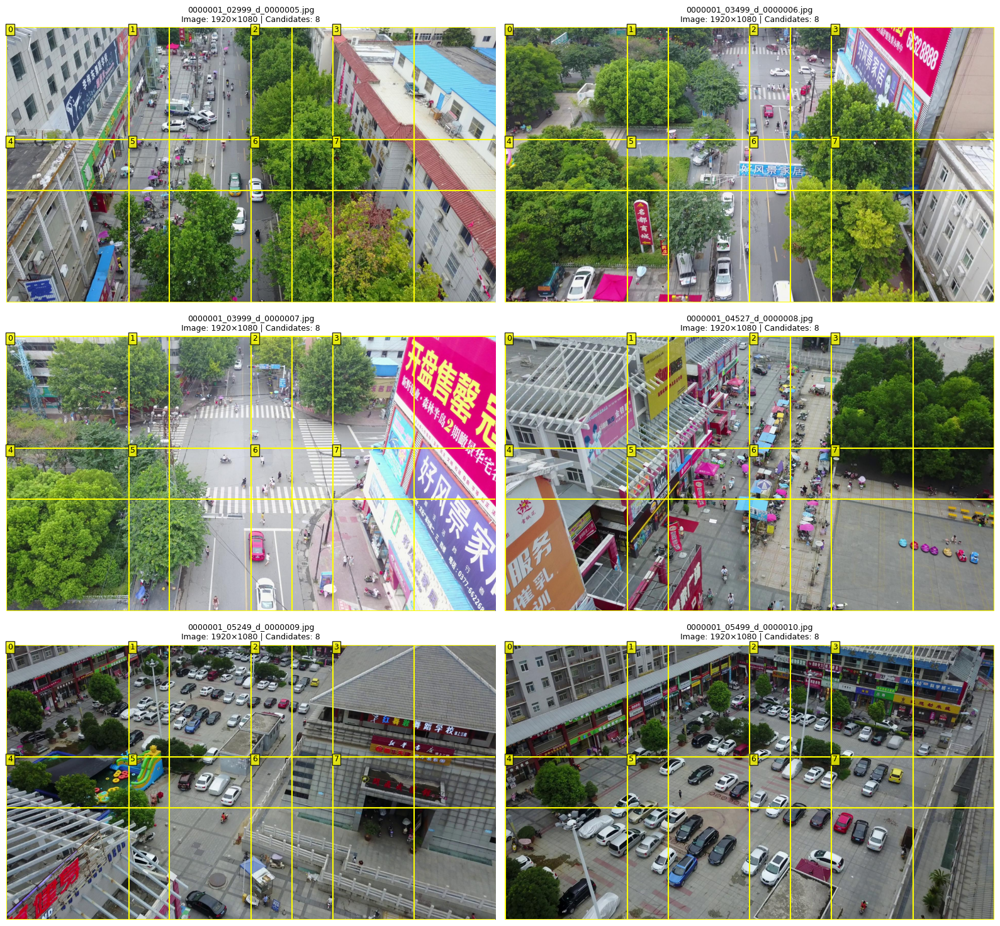

Candidate-region summary:
0000001_02999_d_0000005.jpg: 1920×1080, 8 candidate regions
0000001_03499_d_0000006.jpg: 1920×1080, 8 candidate regions
0000001_03999_d_0000007.jpg: 1920×1080, 8 candidate regions
0000001_04527_d_0000008.jpg: 1920×1080, 8 candidate regions
0000001_05249_d_0000009.jpg: 1920×1080, 8 candidate regions
0000001_05499_d_0000010.jpg: 1920×1080, 8 candidate regions


In [85]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image

# Candidate region settings
CANDIDATE_SIZE = 640
CANDIDATE_OVERLAP = 0.25
CANDIDATE_STRIDE = int(CANDIDATE_SIZE * (1 - CANDIDATE_OVERLAP))

def generate_candidate_regions(width, height, tile_size=640, stride=480):
    """Generate overlapping square regions covering the entire image."""
    def starts(length):
        if length <= tile_size:
            return [0]
        positions = list(range(0, length - tile_size + 1, stride))
        final_start = length - tile_size
        if positions[-1] != final_start:
            positions.append(final_start)
        return positions

    regions = []

    for y in starts(height):
        for x in starts(width):
            x2 = min(x + tile_size, width)
            y2 = min(y + tile_size, height)
            regions.append((x, y, x2, y2))

    return regions


# Display candidate coverage for six validation images
candidate_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:6]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for ax, image_path in zip(axes, candidate_images):
    image = np.array(Image.open(image_path).convert("RGB"))
    height, width = image.shape[:2]

    regions = generate_candidate_regions(
        width,
        height,
        tile_size=CANDIDATE_SIZE,
        stride=CANDIDATE_STRIDE,
    )

    ax.imshow(image)

    for index, (x1, y1, x2, y2) in enumerate(regions):
        ax.add_patch(
            patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=1.5,
                edgecolor="yellow",
                facecolor="none",
            )
        )
        ax.text(
            x1 + 5,
            y1 + 18,
            str(index),
            color="black",
            fontsize=9,
            bbox=dict(facecolor="yellow", alpha=0.8, pad=2),
        )

    ax.set_title(
        f"{image_path.name}\nImage: {width}×{height} | Candidates: {len(regions)}",
        fontsize=9,
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Candidate-region summary:")
for image_path in candidate_images:
    with Image.open(image_path) as image:
        regions = generate_candidate_regions(
            image.width,
            image.height,
            tile_size=CANDIDATE_SIZE,
            stride=CANDIDATE_STRIDE,
        )
        print(
            f"{image_path.name}: "
            f"{image.width}×{image.height}, {len(regions)} candidate regions"
        )

## Adaptive Region Selection: Ranking Candidate Regions

### Objective
Select at most two promising regions for additional object detection.

### Selection Strategy
Rank each candidate region using:
1. Small-object detections, which indicate areas where higher-resolution inference may help.
2. Low-confidence detections, which indicate potentially uncertain predictions.
3. Detection density, which helps identify crowded areas.
4. Spatial diversity, to avoid selecting nearly identical regions.

The selection policy uses model predictions only. Ground-truth annotations will be used afterward to evaluate the selected regions, not to choose them.

### Current Step
Generate baseline predictions for six validation images, score their candidate regions, and inspect the top two selections.

### Expected Outcome
A ranked list of candidate regions for each image, including their scores and coordinates. This is an initial heuristic, not a trained selection model.

In [86]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
from ultralytics import YOLO

# Load the existing baseline checkpoint
selection_model = YOLO(
    str(RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt")
)

SELECTION_IMAGE_SIZE = 1280
SELECTION_CONFIDENCE = 0.05
MAX_SELECTED_REGIONS = 2

# Use the six validation images from the previous step
selection_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))[:6]

selection_results = []

for image_path in selection_images:
    with Image.open(image_path) as image:
        width, height = image.size

    # Generate baseline predictions on the complete image
    prediction = selection_model.predict(
        source=str(image_path),
        imgsz=SELECTION_IMAGE_SIZE,
        conf=SELECTION_CONFIDENCE,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if prediction.boxes is None or len(prediction.boxes) == 0:
        boxes = np.empty((0, 4))
        scores = np.empty(0)
        classes = np.empty(0, dtype=int)
    else:
        boxes = prediction.boxes.xyxy.cpu().numpy()
        scores = prediction.boxes.conf.cpu().numpy()
        classes = prediction.boxes.cls.cpu().numpy().astype(int)

    regions = generate_candidate_regions(
        width,
        height,
        tile_size=CANDIDATE_SIZE,
        stride=CANDIDATE_STRIDE,
    )

    region_records = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        # Count predictions whose centers fall inside this region
        if len(boxes):
            centers_x = (boxes[:, 0] + boxes[:, 2]) / 2
            centers_y = (boxes[:, 1] + boxes[:, 3]) / 2

            inside = (
                (centers_x >= x1)
                & (centers_x < x2)
                & (centers_y >= y1)
                & (centers_y < y2)
            )

            region_boxes = boxes[inside]
            region_scores = scores[inside]
        else:
            region_boxes = np.empty((0, 4))
            region_scores = np.empty(0)

        # Small predicted boxes: normalized area <= 0.05% of image area
        if len(region_boxes):
            box_widths = np.maximum(
                region_boxes[:, 2] - region_boxes[:, 0], 0
            )
            box_heights = np.maximum(
                region_boxes[:, 3] - region_boxes[:, 1], 0
            )
            normalized_areas = (
                box_widths * box_heights / (width * height) * 100
            )
            small_count = int(np.sum(normalized_areas <= 0.05))
            uncertain_count = int(np.sum(region_scores < 0.25))
            detection_count = len(region_boxes)
        else:
            small_count = 0
            uncertain_count = 0
            detection_count = 0

        # Initial heuristic: emphasize small and uncertain detections.
        # The density term is deliberately modest.
        score = (
            2.0 * small_count
            + 1.5 * uncertain_count
            + 0.25 * detection_count
        )

        region_records.append({
            "image": image_path.name,
            "region": region_index,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "detections": detection_count,
            "small_detections": small_count,
            "uncertain_detections": uncertain_count,
            "score": score,
        })

    # Rank by score; break ties by region index for reproducibility.
    ranked_regions = sorted(
        region_records,
        key=lambda item: (-item["score"], item["region"]),
    )

    # Greedily select regions while limiting redundant overlap.
    selected = []

    for candidate in ranked_regions:
        candidate_box = (
            candidate["x1"], candidate["y1"],
            candidate["x2"], candidate["y2"]
        )

        redundant = False

        for chosen in selected:
            chosen_box = (
                chosen["x1"], chosen["y1"],
                chosen["x2"], chosen["y2"]
            )

            ix1 = max(candidate_box[0], chosen_box[0])
            iy1 = max(candidate_box[1], chosen_box[1])
            ix2 = min(candidate_box[2], chosen_box[2])
            iy2 = min(candidate_box[3], chosen_box[3])

            intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
            candidate_area = (
                (candidate_box[2] - candidate_box[0])
                * (candidate_box[3] - candidate_box[1])
            )
            chosen_area = (
                (chosen_box[2] - chosen_box[0])
                * (chosen_box[3] - chosen_box[1])
            )
            union = candidate_area + chosen_area - intersection
            overlap = intersection / union if union else 0

            if overlap > 0.50:
                redundant = True
                break

        if not redundant:
            selected.append(candidate)

        if len(selected) == MAX_SELECTED_REGIONS:
            break

    for rank, region in enumerate(selected, start=1):
        selection_results.append({
            "image": image_path.name,
            "selected_rank": rank,
            "region": region["region"],
            "coordinates": (
                region["x1"], region["y1"],
                region["x2"], region["y2"]
            ),
            "detections": region["detections"],
            "small_detections": region["small_detections"],
            "uncertain_detections": region["uncertain_detections"],
            "score": round(region["score"], 2),
        })

selection_table = pd.DataFrame(selection_results)

print("Selected candidate regions:")
print(selection_table.to_string(index=False))

Selected candidate regions:
                      image  selected_rank  region            coordinates  detections  small_detections  uncertain_detections  score
0000001_02999_d_0000005.jpg              1       1    (480, 0, 1120, 640)         231               163                   175 646.25
0000001_02999_d_0000005.jpg              2       5 (480, 440, 1120, 1080)         129                63                   106 317.25
0000001_03499_d_0000006.jpg              1       2    (960, 0, 1600, 640)         110                97                    86 350.50
0000001_03499_d_0000006.jpg              2       1    (480, 0, 1120, 640)         105                85                    79 314.75
0000001_03999_d_0000007.jpg              1       1    (480, 0, 1120, 640)         123               106                    91 379.25
0000001_03999_d_0000007.jpg              2       2    (960, 0, 1600, 640)          73                59                    52 214.25
0000001_04527_d_0000008.jpg              

## Visualize Selected Candidate Regions

Display the six validation images with the two selected regions outlined in different colors. Each region is labeled with its rank, region index, and selection score.

The visualization helps verify whether the selection policy focuses on useful image areas before implementing crop inference.

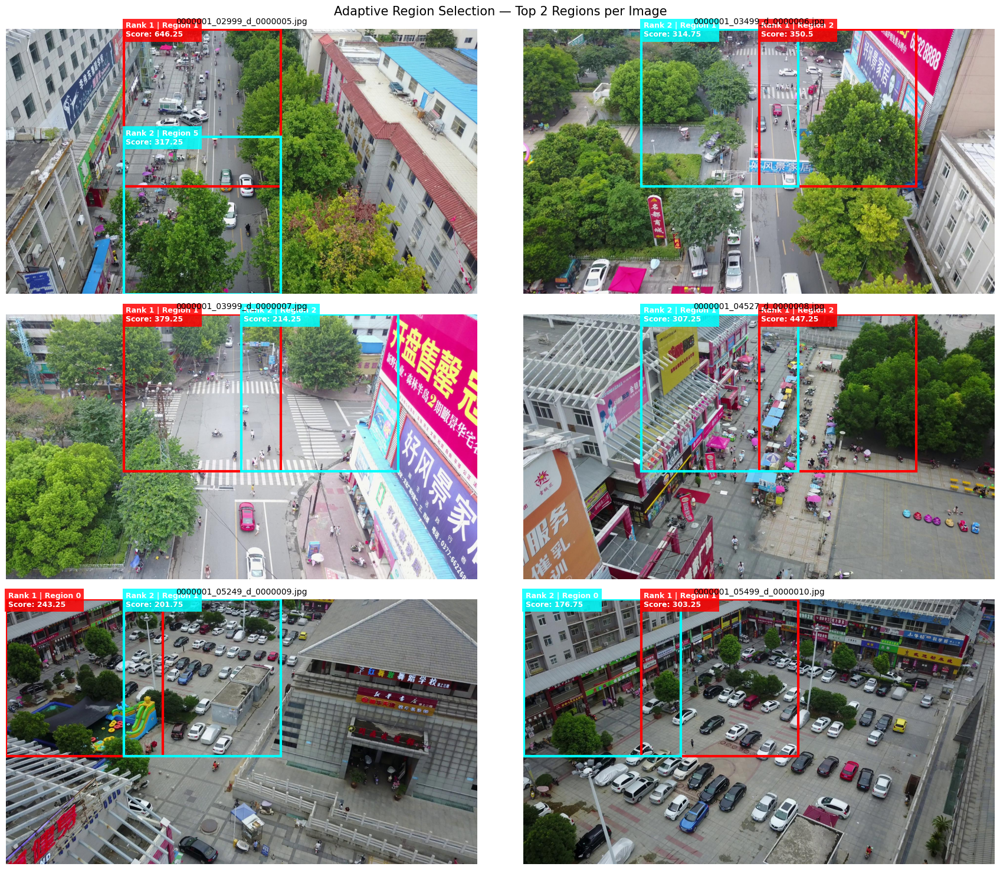

In [87]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
from PIL import Image

# Colors distinguish selection rank
RANK_COLORS = {1: "red", 2: "cyan"}

fig, axes = plt.subplots(3, 2, figsize=(18, 15))
axes = axes.flatten()

for ax, image_path in zip(axes, selection_images):
    image = Image.open(image_path).convert("RGB")
    ax.imshow(image)

    image_selections = selection_table[
        selection_table["image"] == image_path.name
    ]

    for _, row in image_selections.iterrows():
        x1, y1, x2, y2 = row["coordinates"]
        rank = int(row["selected_rank"])
        color = RANK_COLORS[rank]

        # Draw the selected region
        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=3,
            edgecolor=color,
            facecolor="none",
        )
        ax.add_patch(rectangle)

        # Label the region
        label = (
            f"Rank {rank} | Region {row['region']}\n"
            f"Score: {row['score']}"
        )

        ax.text(
            x1 + 8,
            y1 + 30,
            label,
            color="white",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                facecolor=color,
                alpha=0.85,
                edgecolor="none",
                pad=4,
            ),
        )

    ax.set_title(image_path.name, fontsize=10)
    ax.axis("off")

fig.suptitle(
    "Adaptive Region Selection — Top 2 Regions per Image",
    fontsize=15,
)
plt.tight_layout()
plt.show()

## Evaluate Selected Regions Against Ground Truth

### Objective
Measure how many ground-truth objects fall inside the two selected regions.

### Evaluation
- Count all ground-truth object centers inside the selected regions.
- Count small ground-truth objects using the existing threshold of 0.05% normalized image area.
- Measure coverage across the six validation images.
- Treat this as a diagnostic: region coverage does not guarantee that the detector will detect those objects.

The selection policy remains unchanged and uses only model predictions.

In [88]:
from pathlib import Path
import numpy as np
import pandas as pd

coverage_results = []

for image_path in selection_images:
    label_path = (
        VAL_LABEL_DIR / f"{image_path.stem}.txt"
    )

    with Image.open(image_path) as image:
        image_width, image_height = image.size

    # YOLO labels: class, x_center, y_center, width, height
    if label_path.exists() and label_path.stat().st_size > 0:
        labels = np.loadtxt(label_path, dtype=float, ndmin=2)
        gt_classes = labels[:, 0].astype(int)
        gt_boxes = labels[:, 1:5].copy()

        gt_boxes[:, [0, 2]] *= image_width
        gt_boxes[:, [1, 3]] *= image_height

        gt_boxes[:, 0] -= gt_boxes[:, 2] / 2
        gt_boxes[:, 1] -= gt_boxes[:, 3] / 2
        gt_boxes[:, 2] += gt_boxes[:, 0]
        gt_boxes[:, 3] += gt_boxes[:, 1]
    else:
        gt_classes = np.empty(0, dtype=int)
        gt_boxes = np.empty((0, 4))

    if len(gt_boxes):
        centers_x = (gt_boxes[:, 0] + gt_boxes[:, 2]) / 2
        centers_y = (gt_boxes[:, 1] + gt_boxes[:, 3]) / 2

        gt_areas_percent = (
            (gt_boxes[:, 2] - gt_boxes[:, 0])
            * (gt_boxes[:, 3] - gt_boxes[:, 1])
            / (image_width * image_height)
            * 100
        )
        gt_small = gt_areas_percent <= 0.05
    else:
        centers_x = np.empty(0)
        centers_y = np.empty(0)
        gt_small = np.empty(0, dtype=bool)

    selected_regions = selection_table[
        selection_table["image"] == image_path.name
    ]

    covered_by_any = np.zeros(len(gt_boxes), dtype=bool)
    covered_small_by_any = np.zeros(len(gt_boxes), dtype=bool)

    for _, row in selected_regions.iterrows():
        x1, y1, x2, y2 = row["coordinates"]

        inside = (
            (centers_x >= x1)
            & (centers_x < x2)
            & (centers_y >= y1)
            & (centers_y < y2)
        )

        covered_by_any |= inside
        covered_small_by_any |= inside & gt_small

    total_objects = len(gt_boxes)
    total_small = int(gt_small.sum())

    coverage_results.append({
        "image": image_path.name,
        "GT_objects": total_objects,
        "GT_objects_covered": int(covered_by_any.sum()),
        "GT_coverage_%": round(
            100 * covered_by_any.sum() / total_objects, 2
        ) if total_objects else np.nan,
        "GT_small_objects": total_small,
        "GT_small_covered": int(covered_small_by_any.sum()),
        "small_coverage_%": round(
            100 * covered_small_by_any.sum() / total_small, 2
        ) if total_small else np.nan,
    })

coverage_table = pd.DataFrame(coverage_results)

print(coverage_table.to_string(index=False))

total_gt = coverage_table["GT_objects"].sum()
covered_gt = coverage_table["GT_objects_covered"].sum()
total_small_gt = coverage_table["GT_small_objects"].sum()
covered_small_gt = coverage_table["GT_small_covered"].sum()

print("\nOverall coverage across six images:")
print(f"Ground-truth objects covered: {covered_gt}/{total_gt}")
print(
    f"Object coverage: "
    f"{100 * covered_gt / total_gt:.2f}%"
    if total_gt else "Object coverage: N/A"
)
print(
    f"Small objects covered: {covered_small_gt}/{total_small_gt}"
)
print(
    f"Small-object coverage: "
    f"{100 * covered_small_gt / total_small_gt:.2f}%"
    if total_small_gt else "Small-object coverage: N/A"
)

                      image  GT_objects  GT_objects_covered  GT_coverage_%  GT_small_objects  GT_small_covered  small_coverage_%
0000001_02999_d_0000005.jpg         127                 119          93.70                76                74             97.37
0000001_03499_d_0000006.jpg          77                  63          81.82                54                49             90.74
0000001_03999_d_0000007.jpg          48                  29          60.42                26                23             88.46
0000001_04527_d_0000008.jpg         115                  83          72.17                74                62             83.78
0000001_05249_d_0000009.jpg         113                  83          73.45                28                16             57.14
0000001_05499_d_0000010.jpg         140                  71          50.71                52                36             69.23

Overall coverage across six images:
Ground-truth objects covered: 448/620
Object coverage: 72.26

## Adaptive Crop Inference: First Pilot

### Objective
Run YOLOv8n on the two selected 640 × 640 regions per image and map crop predictions back to the original image coordinates.

### Comparison
- Baseline: full-image inference at 1280 pixels.
- Adaptive method: full-image inference followed by inference on two selected crops.
- Evaluate both methods against the same ground-truth annotations.

### Important
Crop predictions may overlap with baseline predictions. They must be merged and evaluated consistently. This first pilot uses six images and does not establish final performance.

In [89]:
import numpy as np
import pandas as pd
from PIL import Image

from torchvision.ops import nms

CROP_CONFIDENCE = 0.05
MATCH_IOU = 0.50
CROP_NMS_IOU = 0.50

def box_iou_one_to_many(box, boxes):
    """IoU between one xyxy box and an array of xyxy boxes."""
    if len(boxes) == 0:
        return np.empty(0)

    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, ix2 - ix1) * np.maximum(0, iy2 - iy1)

    area_a = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    area_b = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0])
        * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = area_a + area_b - intersection
    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=float),
        where=union > 0,
    )


def evaluate_class_aware(boxes, scores, classes, gt_boxes, gt_classes):
    """Greedy class-aware matching at the specified IoU threshold."""
    order = np.argsort(-scores)
    matched_gt = set()
    tp = 0
    fp = 0

    for pred_idx in order:
        eligible = np.where(gt_classes == classes[pred_idx])[0]
        eligible = np.array(
            [idx for idx in eligible if idx not in matched_gt],
            dtype=int,
        )

        if len(eligible) == 0:
            fp += 1
            continue

        ious = box_iou_one_to_many(boxes[pred_idx], gt_boxes[eligible])
        best_pos = int(np.argmax(ious))

        if ious[best_pos] >= MATCH_IOU:
            matched_gt.add(int(eligible[best_pos]))
            tp += 1
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched_gt)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / len(gt_boxes) if len(gt_boxes) else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    }


crop_pilot_rows = []

for image_path in selection_images:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Full-image predictions, matching the selector's baseline settings
    full_result = selection_model.predict(
        source=str(image_path),
        imgsz=SELECTION_IMAGE_SIZE,
        conf=CROP_CONFIDENCE,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if full_result.boxes is not None and len(full_result.boxes):
        full_boxes = full_result.boxes.xyxy.cpu().numpy()
        full_scores = full_result.boxes.conf.cpu().numpy()
        full_classes = full_result.boxes.cls.cpu().numpy().astype(int)
    else:
        full_boxes = np.empty((0, 4))
        full_scores = np.empty(0)
        full_classes = np.empty(0, dtype=int)

    # Load ground-truth labels
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists() and label_path.stat().st_size > 0:
        labels = np.loadtxt(label_path, dtype=float, ndmin=2)
        gt_classes = labels[:, 0].astype(int)
        gt_boxes = labels[:, 1:5].copy()

        gt_boxes[:, [0, 2]] *= width
        gt_boxes[:, [1, 3]] *= height
        gt_boxes[:, 0] -= gt_boxes[:, 2] / 2
        gt_boxes[:, 1] -= gt_boxes[:, 3] / 2
        gt_boxes[:, 2] += gt_boxes[:, 0]
        gt_boxes[:, 3] += gt_boxes[:, 1]
    else:
        gt_boxes = np.empty((0, 4))
        gt_classes = np.empty(0, dtype=int)

    # Run inference on the two selected crops
    crop_boxes_all = []
    crop_scores_all = []
    crop_classes_all = []

    selected_regions = selection_table[
        selection_table["image"] == image_path.name
    ]

    for _, selected_row in selected_regions.iterrows():
        x1, y1, x2, y2 = map(int, selected_row["coordinates"])
        crop = image.crop((x1, y1, x2, y2))

        crop_result = selection_model.predict(
            source=np.array(crop),
            imgsz=CANDIDATE_SIZE,
            conf=CROP_CONFIDENCE,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if crop_result.boxes is None or len(crop_result.boxes) == 0:
            continue

        crop_boxes = crop_result.boxes.xyxy.cpu().numpy().copy()
        crop_scores = crop_result.boxes.conf.cpu().numpy()
        crop_classes = crop_result.boxes.cls.cpu().numpy().astype(int)

        # Convert crop coordinates to original-image coordinates
        crop_boxes[:, [0, 2]] += x1
        crop_boxes[:, [1, 3]] += y1

        crop_boxes[:, [0, 2]] = np.clip(crop_boxes[:, [0, 2]], 0, width)
        crop_boxes[:, [1, 3]] = np.clip(crop_boxes[:, [1, 3]], 0, height)

        crop_boxes_all.append(crop_boxes)
        crop_scores_all.append(crop_scores)
        crop_classes_all.append(crop_classes)

    if crop_boxes_all:
        crop_boxes_all = np.concatenate(crop_boxes_all)
        crop_scores_all = np.concatenate(crop_scores_all)
        crop_classes_all = np.concatenate(crop_classes_all)
    else:
        crop_boxes_all = np.empty((0, 4))
        crop_scores_all = np.empty(0)
        crop_classes_all = np.empty(0, dtype=int)

    # Combine full-image and crop predictions
    combined_boxes = np.concatenate([full_boxes, crop_boxes_all])
    combined_scores = np.concatenate([full_scores, crop_scores_all])
    combined_classes = np.concatenate([full_classes, crop_classes_all])

    # Class-aware NMS across both prediction sources
    if len(combined_boxes):
        keep_parts = []

        for class_id in np.unique(combined_classes):
            class_indices = np.where(combined_classes == class_id)[0]
            keep_local = nms(
                torch.tensor(combined_boxes[class_indices], dtype=torch.float32),
                torch.tensor(combined_scores[class_indices], dtype=torch.float32),
                CROP_NMS_IOU,
            ).numpy()
            keep_parts.extend(class_indices[keep_local].tolist())

        keep_parts = np.array(keep_parts, dtype=int)
        combined_boxes = combined_boxes[keep_parts]
        combined_scores = combined_scores[keep_parts]
        combined_classes = combined_classes[keep_parts]

    baseline_metrics = evaluate_class_aware(
        full_boxes, full_scores, full_classes, gt_boxes, gt_classes
    )

    adaptive_metrics = evaluate_class_aware(
        combined_boxes, combined_scores, combined_classes, gt_boxes, gt_classes
    )

    crop_pilot_rows.append({
        "image": image_path.name,
        "GT": len(gt_boxes),
        "baseline_TP": baseline_metrics["TP"],
        "adaptive_TP": adaptive_metrics["TP"],
        "baseline_FP": baseline_metrics["FP"],
        "adaptive_FP": adaptive_metrics["FP"],
        "baseline_recall": round(baseline_metrics["recall"], 4),
        "adaptive_recall": round(adaptive_metrics["recall"], 4),
        "baseline_F1": round(baseline_metrics["F1"], 4),
        "adaptive_F1": round(adaptive_metrics["F1"], 4),
        "crop_predictions": len(crop_boxes_all),
    })

crop_pilot_table = pd.DataFrame(crop_pilot_rows)

print(crop_pilot_table.to_string(index=False))

print("\nAggregate results:")
for method in ["baseline", "adaptive"]:
    tp = crop_pilot_table[f"{method}_TP"].sum()
    fp = crop_pilot_table[f"{method}_FP"].sum()
    fn = crop_pilot_table["GT"].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / crop_pilot_table["GT"].sum()
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"{method:8s} | TP={tp} FP={fp} FN={fn} "
        f"Precision={precision:.4f} Recall={recall:.4f} F1={f1:.4f}"
    )

                      image  GT  baseline_TP  adaptive_TP  baseline_FP  adaptive_FP  baseline_recall  adaptive_recall  baseline_F1  adaptive_F1  crop_predictions
0000001_02999_d_0000005.jpg 127           74           85          226          248           0.5827           0.6693       0.3466       0.3696               355
0000001_03499_d_0000006.jpg  77           44           54          145          189           0.5714           0.7013       0.3308       0.3375               310
0000001_03999_d_0000007.jpg  48           35           36          161          155           0.7292           0.7500       0.2869       0.3013               199
0000001_04527_d_0000008.jpg 115           69           81          231          397           0.6000           0.7043       0.3325       0.2732               556
0000001_05249_d_0000009.jpg 113           98           99          202          254           0.8673           0.8761       0.4746       0.4249               305
0000001_05499_d_0000010.jpg 

## Adaptive Inference: Diagnose Duplicate Predictions

### Objective
Determine whether crop inference adds useful detections or mainly introduces duplicate and incorrect predictions.

### Analysis
Compare baseline and crop predictions using class-aware matching against ground truth. Identify:
- Correct detections added by crop inference.
- Additional false positives.
- Whether crop predictions duplicate existing baseline detections.

### Decision
Keep the six-image pilot fixed. Do not change the model or selection policy until the source of the precision loss is understood.

In [90]:
import numpy as np
import pandas as pd
from PIL import Image

duplicate_diagnostic_rows = []

for image_path in selection_images:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Baseline predictions
    result = selection_model.predict(
        source=str(image_path),
        imgsz=SELECTION_IMAGE_SIZE,
        conf=CROP_CONFIDENCE,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if result.boxes is not None and len(result.boxes):
        base_boxes = result.boxes.xyxy.cpu().numpy()
        base_scores = result.boxes.conf.cpu().numpy()
        base_classes = result.boxes.cls.cpu().numpy().astype(int)
    else:
        base_boxes = np.empty((0, 4))
        base_scores = np.empty(0)
        base_classes = np.empty(0, dtype=int)

    crop_boxes_list = []
    crop_scores_list = []
    crop_classes_list = []

    selected_regions = selection_table[
        selection_table["image"] == image_path.name
    ]

    for _, row in selected_regions.iterrows():
        x1, y1, x2, y2 = map(int, row["coordinates"])
        crop = np.array(image.crop((x1, y1, x2, y2)))

        result = selection_model.predict(
            source=crop,
            imgsz=CANDIDATE_SIZE,
            conf=CROP_CONFIDENCE,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy().copy()
        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1
        boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
        boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

        crop_boxes_list.append(boxes)
        crop_scores_list.append(result.boxes.conf.cpu().numpy())
        crop_classes_list.append(
            result.boxes.cls.cpu().numpy().astype(int)
        )

    if crop_boxes_list:
        crop_boxes = np.concatenate(crop_boxes_list)
        crop_scores = np.concatenate(crop_scores_list)
        crop_classes = np.concatenate(crop_classes_list)
    else:
        crop_boxes = np.empty((0, 4))
        crop_scores = np.empty(0)
        crop_classes = np.empty(0, dtype=int)

    duplicate_counts = {0.3: 0, 0.5: 0, 0.7: 0}

    for crop_idx, crop_box in enumerate(crop_boxes):
        same_class = np.where(base_classes == crop_classes[crop_idx])[0]

        if len(same_class) == 0:
            continue

        overlaps = box_iou_one_to_many(
            crop_box, base_boxes[same_class]
        )
        best_iou = overlaps.max() if len(overlaps) else 0

        for threshold in duplicate_counts:
            if best_iou >= threshold:
                duplicate_counts[threshold] += 1

    duplicate_diagnostic_rows.append({
        "image": image_path.name,
        "baseline_predictions": len(base_boxes),
        "crop_predictions": len(crop_boxes),
        "crop_overlap_IoU_ge_0.3": duplicate_counts[0.3],
        "crop_overlap_IoU_ge_0.5": duplicate_counts[0.5],
        "crop_overlap_IoU_ge_0.7": duplicate_counts[0.7],
    })

duplicate_diagnostic_table = pd.DataFrame(
    duplicate_diagnostic_rows
)

print(duplicate_diagnostic_table.to_string(index=False))

print("\nTotals:")
print(
    duplicate_diagnostic_table[
        [
            "baseline_predictions",
            "crop_predictions",
            "crop_overlap_IoU_ge_0.3",
            "crop_overlap_IoU_ge_0.5",
            "crop_overlap_IoU_ge_0.7",
        ]
    ].sum().to_string()
)

                      image  baseline_predictions  crop_predictions  crop_overlap_IoU_ge_0.3  crop_overlap_IoU_ge_0.5  crop_overlap_IoU_ge_0.7
0000001_02999_d_0000005.jpg                   300               355                      258                      213                      130
0000001_03499_d_0000006.jpg                   189               310                      197                      166                       94
0000001_03999_d_0000007.jpg                   196               199                      131                      121                       78
0000001_04527_d_0000008.jpg                   300               556                      251                      207                      111
0000001_05249_d_0000009.jpg                   300               305                      180                      156                      106
0000001_05499_d_0000010.jpg                   272               228                      152                      132                       75

## Adaptive Inference: Classify Crop Predictions

### Objective
Determine whether crop inference adds correct detections or mainly duplicates existing predictions.

### Method
Match baseline and crop predictions independently against ground-truth objects using the same class-aware IoU threshold of 0.50.

Classify crop predictions as:
- New true positives: correctly detect an object not matched by baseline.
- Duplicate true positives: detect an object already matched by baseline.
- False positives: do not match any ground-truth object.

This diagnostic uses ground truth only for offline evaluation, never for region selection.

In [91]:
import numpy as np
import pandas as pd
from PIL import Image

crop_classification_rows = []

for image_path in selection_images:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Full-image baseline predictions
    result = selection_model.predict(
        source=str(image_path),
        imgsz=SELECTION_IMAGE_SIZE,
        conf=CROP_CONFIDENCE,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if result.boxes is not None and len(result.boxes):
        base_boxes = result.boxes.xyxy.cpu().numpy()
        base_scores = result.boxes.conf.cpu().numpy()
        base_classes = result.boxes.cls.cpu().numpy().astype(int)
    else:
        base_boxes = np.empty((0, 4))
        base_scores = np.empty(0)
        base_classes = np.empty(0, dtype=int)

    # Ground truth
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists() and label_path.stat().st_size > 0:
        labels = np.loadtxt(label_path, dtype=float, ndmin=2)
        gt_classes = labels[:, 0].astype(int)
        gt_boxes = labels[:, 1:5].copy()

        gt_boxes[:, [0, 2]] *= width
        gt_boxes[:, [1, 3]] *= height
        gt_boxes[:, 0] -= gt_boxes[:, 2] / 2
        gt_boxes[:, 1] -= gt_boxes[:, 3] / 2
        gt_boxes[:, 2] += gt_boxes[:, 0]
        gt_boxes[:, 3] += gt_boxes[:, 1]
    else:
        gt_boxes = np.empty((0, 4))
        gt_classes = np.empty(0, dtype=int)

    # Match baseline predictions to ground truth first
    baseline_order = np.argsort(-base_scores)
    matched_gt = set()
    baseline_tp = 0

    for pred_idx in baseline_order:
        eligible = np.array([
            idx for idx in np.where(gt_classes == base_classes[pred_idx])[0]
            if idx not in matched_gt
        ], dtype=int)

        if len(eligible) == 0:
            continue

        ious = box_iou_one_to_many(base_boxes[pred_idx], gt_boxes[eligible])
        best_pos = int(np.argmax(ious))

        if ious[best_pos] >= MATCH_IOU:
            matched_gt.add(int(eligible[best_pos]))
            baseline_tp += 1

    baseline_matched_gt = set(matched_gt)

    # Run inference on selected crops
    crop_boxes_list = []
    crop_scores_list = []
    crop_classes_list = []

    selected_regions = selection_table[
        selection_table["image"] == image_path.name
    ]

    for _, row in selected_regions.iterrows():
        x1, y1, x2, y2 = map(int, row["coordinates"])
        crop = np.array(image.crop((x1, y1, x2, y2)))

        result = selection_model.predict(
            source=crop,
            imgsz=CANDIDATE_SIZE,
            conf=CROP_CONFIDENCE,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy().copy()
        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1
        boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
        boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

        crop_boxes_list.append(boxes)
        crop_scores_list.append(result.boxes.conf.cpu().numpy())
        crop_classes_list.append(
            result.boxes.cls.cpu().numpy().astype(int)
        )

    if crop_boxes_list:
        crop_boxes = np.concatenate(crop_boxes_list)
        crop_scores = np.concatenate(crop_scores_list)
        crop_classes = np.concatenate(crop_classes_list)
    else:
        crop_boxes = np.empty((0, 4))
        crop_scores = np.empty(0)
        crop_classes = np.empty(0, dtype=int)

    # Process crop predictions by descending confidence.
    # Ground truth is used only to classify outcomes offline.
    order = np.argsort(-crop_scores)
    crop_matched_gt = set(baseline_matched_gt)

    new_tp = 0
    duplicate_tp = 0
    crop_fp = 0

    for pred_idx in order:
        eligible = np.array([
            idx for idx in np.where(gt_classes == crop_classes[pred_idx])[0]
            if idx not in crop_matched_gt
        ], dtype=int)

        if len(eligible) == 0:
            # Check if this crop prediction overlaps any GT already
            # matched by the baseline; otherwise classify as FP.
            same_class_gt = np.where(
                gt_classes == crop_classes[pred_idx]
            )[0]

            if len(same_class_gt):
                overlaps = box_iou_one_to_many(
                    crop_boxes[pred_idx], gt_boxes[same_class_gt]
                )
                if overlaps.max() >= MATCH_IOU:
                    duplicate_tp += 1
                else:
                    crop_fp += 1
            else:
                crop_fp += 1
            continue

        ious = box_iou_one_to_many(
            crop_boxes[pred_idx], gt_boxes[eligible]
        )
        best_pos = int(np.argmax(ious))

        if ious[best_pos] >= MATCH_IOU:
            crop_matched_gt.add(int(eligible[best_pos]))
            new_tp += 1
        else:
            crop_fp += 1

    crop_classification_rows.append({
        "image": image_path.name,
        "baseline_TP": baseline_tp,
        "crop_predictions": len(crop_boxes),
        "new_TP_from_crops": new_tp,
        "duplicate_TP_from_crops": duplicate_tp,
        "crop_FP": crop_fp,
    })

crop_classification_table = pd.DataFrame(crop_classification_rows)

print(crop_classification_table.to_string(index=False))
print("\nTotals:")
print(
    crop_classification_table[
        [
            "baseline_TP",
            "crop_predictions",
            "new_TP_from_crops",
            "duplicate_TP_from_crops",
            "crop_FP",
        ]
    ].sum().to_string()
)

                      image  baseline_TP  crop_predictions  new_TP_from_crops  duplicate_TP_from_crops  crop_FP
0000001_02999_d_0000005.jpg           74               355                 14                        0      341
0000001_03499_d_0000006.jpg           44               310                 12                        1      297
0000001_03999_d_0000007.jpg           35               199                  3                        2      194
0000001_04527_d_0000008.jpg           69               556                 17                        3      536
0000001_05249_d_0000009.jpg           98               305                  4                        0      301
0000001_05499_d_0000010.jpg          101               228                  4                        0      224

Totals:
baseline_TP                 421
crop_predictions           1953
new_TP_from_crops            54
duplicate_TP_from_crops       6
crop_FP                    1893


## Conservative Fusion of Baseline and Crop Predictions

### Objective
Reduce redundant crop predictions while preserving potentially useful new detections.

### Fusion Policy
- Preserve baseline predictions.
- Reject crop predictions that overlap same-class baseline predictions at IoU ≥ 0.50.
- Apply class-aware NMS to the remaining crop predictions.
- Evaluate the merged predictions against ground truth.

### Evaluation
Compare precision, recall, and F1 against the existing full-image baseline on the same six validation images.

This is a pilot fusion experiment, not a final performance claim.

In [92]:
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision.ops import nms

FUSION_OVERLAP_THRESHOLD = 0.50
FUSION_NMS_IOU = 0.50

conservative_fusion_rows = []

for image_path in selection_images:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Baseline predictions
    result = selection_model.predict(
        source=str(image_path),
        imgsz=SELECTION_IMAGE_SIZE,
        conf=CROP_CONFIDENCE,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if result.boxes is not None and len(result.boxes):
        base_boxes = result.boxes.xyxy.cpu().numpy()
        base_scores = result.boxes.conf.cpu().numpy()
        base_classes = result.boxes.cls.cpu().numpy().astype(int)
    else:
        base_boxes = np.empty((0, 4))
        base_scores = np.empty(0)
        base_classes = np.empty(0, dtype=int)

    # Selected crop predictions mapped to original-image coordinates
    crop_boxes_list = []
    crop_scores_list = []
    crop_classes_list = []

    selected_regions = selection_table[
        selection_table["image"] == image_path.name
    ]

    for _, row in selected_regions.iterrows():
        x1, y1, x2, y2 = map(int, row["coordinates"])
        crop = np.array(image.crop((x1, y1, x2, y2)))

        result = selection_model.predict(
            source=crop,
            imgsz=CANDIDATE_SIZE,
            conf=CROP_CONFIDENCE,
            device=0,
            save=False,
            verbose=False,
        )[0]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy().copy()
        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1
        boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
        boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

        crop_boxes_list.append(boxes)
        crop_scores_list.append(result.boxes.conf.cpu().numpy())
        crop_classes_list.append(
            result.boxes.cls.cpu().numpy().astype(int)
        )

    if crop_boxes_list:
        crop_boxes = np.concatenate(crop_boxes_list)
        crop_scores = np.concatenate(crop_scores_list)
        crop_classes = np.concatenate(crop_classes_list)
    else:
        crop_boxes = np.empty((0, 4))
        crop_scores = np.empty(0)
        crop_classes = np.empty(0, dtype=int)

    # Reject crop predictions overlapping same-class baseline predictions
    keep_crop = []

    for idx, box in enumerate(crop_boxes):
        same_class = np.where(base_classes == crop_classes[idx])[0]

        if len(same_class):
            overlaps = box_iou_one_to_many(box, base_boxes[same_class])
            if overlaps.max() >= FUSION_OVERLAP_THRESHOLD:
                continue

        keep_crop.append(idx)

    keep_crop = np.array(keep_crop, dtype=int)
    filtered_boxes = crop_boxes[keep_crop]
    filtered_scores = crop_scores[keep_crop]
    filtered_classes = crop_classes[keep_crop]

    # Class-aware NMS among the remaining crop predictions
    nms_keep = []

    for class_id in np.unique(filtered_classes):
        class_indices = np.where(filtered_classes == class_id)[0]

        keep_local = nms(
            torch.tensor(
                filtered_boxes[class_indices], dtype=torch.float32
            ),
            torch.tensor(
                filtered_scores[class_indices], dtype=torch.float32
            ),
            FUSION_NMS_IOU,
        ).numpy()

        nms_keep.extend(class_indices[keep_local].tolist())

    nms_keep = np.array(nms_keep, dtype=int)
    filtered_boxes = filtered_boxes[nms_keep]
    filtered_scores = filtered_scores[nms_keep]
    filtered_classes = filtered_classes[nms_keep]

    # Merge with baseline predictions
    merged_boxes = np.concatenate([base_boxes, filtered_boxes])
    merged_scores = np.concatenate([base_scores, filtered_scores])
    merged_classes = np.concatenate([base_classes, filtered_classes])

    # Ground truth
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    if label_path.exists() and label_path.stat().st_size > 0:
        labels = np.loadtxt(label_path, dtype=float, ndmin=2)
        gt_classes = labels[:, 0].astype(int)
        gt_boxes = labels[:, 1:5].copy()

        gt_boxes[:, [0, 2]] *= width
        gt_boxes[:, [1, 3]] *= height
        gt_boxes[:, 0] -= gt_boxes[:, 2] / 2
        gt_boxes[:, 1] -= gt_boxes[:, 3] / 2
        gt_boxes[:, 2] += gt_boxes[:, 0]
        gt_boxes[:, 3] += gt_boxes[:, 1]
    else:
        gt_boxes = np.empty((0, 4))
        gt_classes = np.empty(0, dtype=int)

    baseline_metrics = evaluate_class_aware(
        base_boxes, base_scores, base_classes, gt_boxes, gt_classes
    )

    fusion_metrics = evaluate_class_aware(
        merged_boxes, merged_scores, merged_classes, gt_boxes, gt_classes
    )

    conservative_fusion_rows.append({
        "image": image_path.name,
        "crop_predictions_original": len(crop_boxes),
        "crop_predictions_kept": len(filtered_boxes),
        "baseline_precision": round(baseline_metrics["precision"], 4),
        "fusion_precision": round(fusion_metrics["precision"], 4),
        "baseline_recall": round(baseline_metrics["recall"], 4),
        "fusion_recall": round(fusion_metrics["recall"], 4),
        "baseline_F1": round(baseline_metrics["F1"], 4),
        "fusion_F1": round(fusion_metrics["F1"], 4),
    })

conservative_fusion_table = pd.DataFrame(conservative_fusion_rows)
print(conservative_fusion_table.to_string(index=False))

print("\nAggregate metrics:")
for method in ["baseline", "fusion"]:
    precision_col = f"{method}_precision"
    recall_col = f"{method}_recall"
    f1_col = f"{method}_F1"

    # Aggregate TP/FP/FN by rerunning the evaluator per image is preferable
    # to averaging per-image precision and recall. The next output uses
    # the mean per-image metrics as a compact diagnostic.
    print(
        f"{method:8s} | "
        f"mean precision={conservative_fusion_table[precision_col].mean():.4f}, "
        f"mean recall={conservative_fusion_table[recall_col].mean():.4f}, "
        f"mean F1={conservative_fusion_table[f1_col].mean():.4f}"
    )

                      image  crop_predictions_original  crop_predictions_kept  baseline_precision  fusion_precision  baseline_recall  fusion_recall  baseline_F1  fusion_F1
0000001_02999_d_0000005.jpg                        355                    115              0.2467            0.2048           0.5827         0.6693       0.3466     0.3137
0000001_03499_d_0000006.jpg                        310                     95              0.2328            0.1901           0.5714         0.7013       0.3308     0.2992
0000001_03999_d_0000007.jpg                        199                     51              0.1786            0.1498           0.7292         0.7708       0.2869     0.2508
0000001_04527_d_0000008.jpg                        556                    238              0.2300            0.1543           0.6000         0.7217       0.3325     0.2542
0000001_05249_d_0000009.jpg                        305                    119              0.3267            0.2411           0.8673        


## Class-Restricted Adaptive Crop Inference

### Objective
Test whether high-confidence crop detections improve small-object detection without adding excessive false positives.

### Experimental Setup
- Preserve all full-image baseline detections.
- Use the existing two selected crops per image.
- Accept crop predictions only for pedestrian, people, bicycle, tricycle, awning-tricycle, and motor.
- Use a crop confidence threshold of 0.25.
- Reject crop detections that overlap same-class baseline detections at IoU ≥ 0.50.
- Evaluate per-class precision, recall, F1, and overall performance on the same six images.

The confidence threshold applies only to crop predictions.


In [94]:

print("selection_table columns:")
print(selection_table.columns.tolist())

display(selection_table.head(4))


selection_table columns:
['image', 'selected_rank', 'region', 'coordinates', 'detections', 'small_detections', 'uncertain_detections', 'score']


,image,selected_rank,region,coordinates,detections,small_detections,uncertain_detections,score
0,0000001_02999_d_0000005.jpg,1,1,"(480, 0, 1120, 640)",231,163,175,646.25
1,0000001_02999_d_0000005.jpg,2,5,"(480, 440, 1120, 1080)",129,63,106,317.25
2,0000001_03499_d_0000006.jpg,1,2,"(960, 0, 1600, 640)",110,97,86,350.50
3,0000001_03499_d_0000006.jpg,2,1,"(480, 0, 1120, 640)",105,85,79,314.75


In [96]:

# Rebuild the duplicate filter using NumPy-compatible inputs.
duplicate_keep = []

baseline_boxes_np = baseline_boxes.cpu().numpy()
baseline_classes_np = baseline_classes.cpu().numpy()
crop_boxes_np = crop_boxes.cpu().numpy()
crop_classes_np = crop_classes.cpu().numpy()

for i in range(len(crop_boxes_np)):
    same_class_idx = np.where(
        baseline_classes_np == crop_classes_np[i]
    )[0]

    if len(same_class_idx) == 0:
        duplicate_keep.append(i)
        continue

    overlaps = box_iou_one_to_many(
        crop_boxes_np[i],
        baseline_boxes_np[same_class_idx],
    )

    if len(overlaps) == 0 or np.max(overlaps) < DUPLICATE_IOU_THRESHOLD:
        duplicate_keep.append(i)

duplicate_keep = torch.tensor(duplicate_keep, dtype=torch.long)

crop_boxes = crop_boxes[duplicate_keep]
crop_scores = crop_scores[duplicate_keep]
crop_classes = crop_classes[duplicate_keep]

crop_count_after_duplicate_filter = len(crop_boxes)

print("Crop predictions remaining after duplicate filtering:",
      crop_count_after_duplicate_filter)


Crop predictions remaining after duplicate filtering: 19


In [98]:

def evaluate_classes_for_experiment(
    pred_boxes, pred_scores, pred_classes,
    gt_boxes, gt_classes, iou_threshold=None
):
    if iou_threshold is None:
        iou_threshold = MATCH_IOU

    rows = []

    # Convert tensors to NumPy once.
    pb_all = pred_boxes.detach().cpu().numpy().reshape(-1, 4)
    ps_all = pred_scores.detach().cpu().numpy()
    pc_all = pred_classes.detach().cpu().numpy()
    gb_all = gt_boxes.detach().cpu().numpy().reshape(-1, 4)
    gc_all = gt_classes.detach().cpu().numpy()

    for cls_id, class_name in CLASS_NAMES.items():
        p_idx = np.where(pc_all == cls_id)[0]
        g_idx = np.where(gc_all == cls_id)[0]

        pb = pb_all[p_idx]
        ps = ps_all[p_idx]
        gb = gb_all[g_idx]

        order = np.argsort(-ps)
        matched_gt = set()
        tp, fp = 0, 0

        # Pairwise IoU matrix: predictions x ground-truth boxes.
        if len(pb) and len(gb):
            ix1 = np.maximum(pb[:, None, 0], gb[None, :, 0])
            iy1 = np.maximum(pb[:, None, 1], gb[None, :, 1])
            ix2 = np.minimum(pb[:, None, 2], gb[None, :, 2])
            iy2 = np.minimum(pb[:, None, 3], gb[None, :, 3])

            intersection = (
                np.maximum(0, ix2 - ix1) *
                np.maximum(0, iy2 - iy1)
            )

            area_p = (
                np.maximum(0, pb[:, 2] - pb[:, 0]) *
                np.maximum(0, pb[:, 3] - pb[:, 1])
            )
            area_g = (
                np.maximum(0, gb[:, 2] - gb[:, 0]) *
                np.maximum(0, gb[:, 3] - gb[:, 1])
            )

            union = area_p[:, None] + area_g[None, :] - intersection
            ious = np.divide(
                intersection, union,
                out=np.zeros_like(intersection, dtype=float),
                where=union > 0
            )
        else:
            ious = np.zeros((len(pb), len(gb)), dtype=float)

        for pred_i in order:
            if len(gb) == 0:
                fp += 1
                continue

            candidate_ious = ious[pred_i].copy()
            if matched_gt:
                candidate_ious[list(matched_gt)] = -1

            best_gt = int(np.argmax(candidate_ious))

            if candidate_ious[best_gt] >= iou_threshold:
                tp += 1
                matched_gt.add(best_gt)
            else:
                fp += 1

        fn = len(gb) - tp
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        rows.append({
            "class_id": cls_id,
            "class": class_name,
            "GT": len(gb),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "precision": precision,
            "recall": recall,
            "F1": f1,
        })

    return pd.DataFrame(rows)

print("Evaluation function replaced successfully.")


Evaluation function replaced successfully.



## Class-Restricted Adaptive Crop Inference

Compare the unchanged full-image baseline with adaptive crops on the same six validation images.

- Baseline confidence: 0.05
- Crop confidence: 0.25
- Target crop classes: pedestrian, people, bicycle, tricycle, awning-tricycle, motor
- Duplicate rejection: same class, IoU ≥ 0.50
- Crop NMS IoU: 0.50
- Evaluation IoU: existing MATCH_IOU

Report per-image and per-class precision, recall, F1, and false positives.


In [100]:

# Flatten per-class DataFrames into one table.
class_crop_per_class = pd.concat(
    class_results,
    ignore_index=True
)

print("Per-image results")
display(class_crop_results.round(4))

print("Mean per-image metrics")
display(
    class_crop_results[
        [
            "baseline_precision", "fusion_precision",
            "baseline_recall", "fusion_recall",
            "baseline_F1", "fusion_F1",
        ]
    ].mean().to_frame("mean").round(4)
)

# Aggregate per-class counts across the six images.
per_class_summary = (
    class_crop_per_class
    .groupby(["method", "class", "class_id"], as_index=False)
    .agg({"GT": "sum", "TP": "sum", "FP": "sum", "FN": "sum"})
)

per_class_summary["precision"] = (
    per_class_summary["TP"]
    / (per_class_summary["TP"] + per_class_summary["FP"]).replace(0, np.nan)
).fillna(0)

per_class_summary["recall"] = (
    per_class_summary["TP"]
    / (per_class_summary["TP"] + per_class_summary["FN"]).replace(0, np.nan)
).fillna(0)

per_class_summary["F1"] = (
    2 * per_class_summary["precision"] * per_class_summary["recall"]
    / (per_class_summary["precision"] + per_class_summary["recall"]).replace(0, np.nan)
).fillna(0)

print("Per-class aggregate results")
display(
    per_class_summary[
        ["method", "class", "GT", "TP", "FP", "FN",
         "precision", "recall", "F1"]
    ].round(4)
)


Per-image results


,image,crop_original,after_class_filter,after_duplicate_filter,after_crop_NMS,baseline_precision,fusion_precision,baseline_recall,fusion_recall,baseline_F1,fusion_F1
0,0000001_02999_d_0000005.jpg,98,77,19,15,0.2467,0.2381,0.5827,0.5906,0.3466,0.3394
1,0000001_03499_d_0000006.jpg,70,53,8,7,0.2328,0.2347,0.5714,0.5974,0.3308,0.3370
2,0000001_03999_d_0000007.jpg,61,57,7,5,0.1786,0.1791,0.7292,0.7500,0.2869,0.2892
3,0000001_04527_d_0000008.jpg,86,76,10,9,0.1548,0.1540,0.6783,0.6870,0.2520,0.2516
4,0000001_05249_d_0000009.jpg,109,9,2,2,0.2832,0.2816,0.8673,0.8673,0.4270,0.4252
5,0000001_05499_d_0000010.jpg,54,19,4,3,0.3713,0.3673,0.7214,0.7214,0.4903,0.4867


Mean per-image metrics


,mean
baseline_precision,0.2446
fusion_precision,0.2425
baseline_recall,0.6917
fusion_recall,0.7023
baseline_F1,0.3556
fusion_F1,0.3548


Per-class aggregate results


,method,class,GT,TP,FP,FN,precision,recall,F1
0,baseline,awning-tricycle,31,6,44,25,0.1200,0.1935,0.1481
1,baseline,bicycle,12,2,30,10,0.0625,0.1667,0.0909
2,baseline,bus,0,0,2,0,0.0000,0.0000,0.0000
3,baseline,car,182,171,155,11,0.5245,0.9396,0.6732
4,baseline,motor,199,144,610,55,0.1910,0.7236,0.3022
5,baseline,pedestrian,70,46,297,24,0.1341,0.6571,0.2228
6,baseline,people,108,53,134,55,0.2834,0.4907,0.3593
7,baseline,tricycle,8,2,66,6,0.0294,0.2500,0.0526
8,baseline,truck,1,0,12,1,0.0000,0.0000,0.0000
9,baseline,van,9,6,27,3,0.1818,0.6667,0.2857



## Confidence Filtering for Adaptive Crop Detection

Objective: reduce false positives from crop predictions while preserving the full-image baseline.

Compare crop confidence thresholds of 0.25, 0.35, and 0.50 on the same six validation images.

Keep the baseline predictions unchanged at confidence 0.05 and image size 1280. Use the existing selected crop regions and the same ground-truth matching IoU.

Report precision, recall, F1, and false positives for each threshold. These are pilot results; any improvement must later be confirmed on a larger validation subset.


In [101]:

import numpy as np
import pandas as pd
import torch
import cv2
from ultralytics import YOLO

CONFIDENCE_THRESHOLDS = [0.25, 0.35, 0.50]
DUPLICATE_IOU = 0.50

confidence_model = YOLO(
    str(RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt")
)

def calculate_iou_matrix(boxes_a, boxes_b):
    a = np.asarray(boxes_a, dtype=float).reshape(-1, 4)
    b = np.asarray(boxes_b, dtype=float).reshape(-1, 4)

    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=float)

    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])

    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    area_a = (
        np.maximum(0, a[:, 2] - a[:, 0]) *
        np.maximum(0, a[:, 3] - a[:, 1])
    )
    area_b = (
        np.maximum(0, b[:, 2] - b[:, 0]) *
        np.maximum(0, b[:, 3] - b[:, 1])
    )

    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(
        intersection, union,
        out=np.zeros_like(intersection),
        where=union > 0,
    )

def confidence_predictions(source, confidence, image_size):
    result = confidence_model.predict(
        source=source,
        imgsz=image_size,
        conf=confidence,
        iou=0.70,
        max_det=1000,
        device=0,
        save=False,
        verbose=False,
    )[0]

    if result.boxes is None or len(result.boxes) == 0:
        return (
            np.empty((0, 4), dtype=float),
            np.empty((0,), dtype=float),
            np.empty((0,), dtype=int),
        )

    return (
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
        result.boxes.cls.cpu().numpy().astype(int),
    )

def evaluate_predictions(pred_boxes, pred_scores, pred_classes,
                         gt_boxes, gt_classes, iou_threshold):
    tp = fp = fn = 0

    pred_boxes = np.asarray(pred_boxes).reshape(-1, 4)
    pred_scores = np.asarray(pred_scores)
    pred_classes = np.asarray(pred_classes, dtype=int)
    gt_boxes = np.asarray(gt_boxes).reshape(-1, 4)
    gt_classes = np.asarray(gt_classes, dtype=int)

    for cls_id in range(10):
        p_idx = np.where(pred_classes == cls_id)[0]
        g_idx = np.where(gt_classes == cls_id)[0]

        order = p_idx[np.argsort(-pred_scores[p_idx])]
        ious = calculate_iou_matrix(pred_boxes[order], gt_boxes[g_idx])
        matched_gt = set()

        for row_idx in range(len(order)):
            if len(g_idx) == 0:
                fp += 1
                continue

            overlaps = ious[row_idx].copy()
            if matched_gt:
                overlaps[list(matched_gt)] = -1

            best = int(np.argmax(overlaps))
            if overlaps[best] >= iou_threshold:
                tp += 1
                matched_gt.add(best)
            else:
                fp += 1

        fn += len(g_idx) - len(matched_gt)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": tp, "FP": fp, "FN": fn,
        "precision": precision, "recall": recall, "F1": f1,
    }

confidence_rows = []

for image_path in selection_images:
    image_name = image_path.name
    image = cv2.imread(str(image_path))

    if image is None:
        print("Skipping unreadable image:", image_name)
        continue

    height, width = image.shape[:2]

    # Baseline: unchanged full-image predictions.
    base_boxes, base_scores, base_classes = confidence_predictions(
        image, confidence=0.05, image_size=SELECTION_IMAGE_SIZE
    )

    # Load ground-truth labels.
    gt_boxes, gt_classes = load_gt(
        VAL_LABEL_DIR / f"{image_path.stem}.txt", width, height
    )

    # Get crop predictions at the lowest tested threshold once.
    regions = (
        selection_table[selection_table["image"] == image_name]
        .sort_values("selected_rank")
    )

    crop_boxes_all, crop_scores_all, crop_classes_all = [], [], []

    for _, region in regions.iterrows():
        x1, y1, x2, y2 = map(int, region["coordinates"])
        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        boxes, scores, classes = confidence_predictions(
            crop, confidence=min(CONFIDENCE_THRESHOLDS),
            image_size=CANDIDATE_SIZE
        )

        if len(boxes) == 0:
            continue

        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1
        boxes[:, [0, 2]] = np.clip(boxes[:, [0, 2]], 0, width)
        boxes[:, [1, 3]] = np.clip(boxes[:, [1, 3]], 0, height)

        crop_boxes_all.extend(boxes)
        crop_scores_all.extend(scores)
        crop_classes_all.extend(classes)

    crop_boxes_all = np.asarray(crop_boxes_all, dtype=float).reshape(-1, 4)
    crop_scores_all = np.asarray(crop_scores_all, dtype=float)
    crop_classes_all = np.asarray(crop_classes_all, dtype=int)

    # Only the selected target classes can be added by crops.
    target_mask = np.isin(crop_classes_all, list(TARGET_CLASSES))
    crop_boxes_all = crop_boxes_all[target_mask]
    crop_scores_all = crop_scores_all[target_mask]
    crop_classes_all = crop_classes_all[target_mask]

    baseline_metrics = evaluate_predictions(
        base_boxes, base_scores, base_classes,
        gt_boxes.numpy(), gt_classes.numpy(), MATCH_IOU
    )

    for threshold in CONFIDENCE_THRESHOLDS:
        mask = crop_scores_all >= threshold
        boxes = crop_boxes_all[mask]
        scores = crop_scores_all[mask]
        classes = crop_classes_all[mask]

        # Reject crop boxes that duplicate a same-class baseline box.
        keep = []
        ious = calculate_iou_matrix(boxes, base_boxes)

        for i in range(len(boxes)):
            same_class = np.where(base_classes == classes[i])[0]

            if len(same_class) == 0:
                keep.append(i)
            elif ious[i, same_class].max() < DUPLICATE_IOU:
                keep.append(i)

        boxes = boxes[keep]
        scores = scores[keep]
        classes = classes[keep]

        # Combine with baseline and evaluate.
        fused_boxes = np.concatenate([base_boxes, boxes], axis=0)
        fused_scores = np.concatenate([base_scores, scores], axis=0)
        fused_classes = np.concatenate([base_classes, classes], axis=0)

        metrics = evaluate_predictions(
            fused_boxes, fused_scores, fused_classes,
            gt_boxes.numpy(), gt_classes.numpy(), MATCH_IOU
        )

        confidence_rows.append({
            "image": image_name,
            "crop_confidence": threshold,
            "baseline_TP": baseline_metrics["TP"],
            "baseline_FP": baseline_metrics["FP"],
            "baseline_FN": baseline_metrics["FN"],
            "baseline_precision": baseline_metrics["precision"],
            "baseline_recall": baseline_metrics["recall"],
            "baseline_F1": baseline_metrics["F1"],
            "crop_boxes_added": len(boxes),
            "fusion_TP": metrics["TP"],
            "fusion_FP": metrics["FP"],
            "fusion_FN": metrics["FN"],
            "fusion_precision": metrics["precision"],
            "fusion_recall": metrics["recall"],
            "fusion_F1": metrics["F1"],
        })

confidence_results = pd.DataFrame(confidence_rows)

print("Per-image results")
display(confidence_results.round(4))

print("Mean metrics by crop confidence")
display(
    confidence_results.groupby("crop_confidence")[
        [
            "baseline_precision", "fusion_precision",
            "baseline_recall", "fusion_recall",
            "baseline_F1", "fusion_F1",
            "baseline_FP", "fusion_FP", "crop_boxes_added",
        ]
    ].mean().round(4)
)


Per-image results


,image,crop_confidence,baseline_TP,baseline_FP,baseline_FN,baseline_precision,baseline_recall,baseline_F1,crop_boxes_added,fusion_TP,fusion_FP,fusion_FN,fusion_precision,fusion_recall,fusion_F1
0,0000001_02999_d_0000005.jpg,0.25,74,226,53,0.2467,0.5827,0.3466,19,75,244,52,0.2351,0.5906,0.3363
1,0000001_02999_d_0000005.jpg,0.35,74,226,53,0.2467,0.5827,0.3466,8,74,234,53,0.2403,0.5827,0.3402
2,0000001_02999_d_0000005.jpg,0.50,74,226,53,0.2467,0.5827,0.3466,1,74,227,53,0.2458,0.5827,0.3458
3,0000001_03499_d_0000006.jpg,0.25,44,145,33,0.2328,0.5714,0.3308,8,46,151,31,0.2335,0.5974,0.3358
4,0000001_03499_d_0000006.jpg,0.35,44,145,33,0.2328,0.5714,0.3308,2,44,147,33,0.2304,0.5714,0.3284
5,0000001_03499_d_0000006.jpg,0.50,44,145,33,0.2328,0.5714,0.3308,0,44,145,33,0.2328,0.5714,0.3308
6,0000001_03999_d_0000007.jpg,0.25,35,161,13,0.1786,0.7292,0.2869,7,37,166,11,0.1823,0.7708,0.2948
7,0000001_03999_d_0000007.jpg,0.35,35,161,13,0.1786,0.7292,0.2869,2,37,161,11,0.1869,0.7708,0.3008
8,0000001_03999_d_0000007.jpg,0.50,35,161,13,0.1786,0.7292,0.2869,2,37,161,11,0.1869,0.7708,0.3008
9,0000001_04527_d_0000008.jpg,0.25,78,426,37,0.1548,0.6783,0.2520,10,79,435,36,0.1537,0.6870,0.2512


Mean metrics by crop confidence


,baseline_precision,fusion_precision,baseline_recall,fusion_recall,baseline_F1,fusion_F1,baseline_FP,fusion_FP,crop_boxes_added
crop_confidence,,,,,,,,,
0.25,0.2446,0.2420,0.6917,0.7057,0.3556,0.3548,229.5,236.8333,8.3333
0.35,0.2446,0.2441,0.6917,0.6986,0.3556,0.3561,229.5,231.8333,2.6667
0.50,0.2446,0.2458,0.6917,0.6986,0.3556,0.3577,229.5,229.8333,0.6667


### Higher Crop Confidence Thresholds

Evaluate crop confidence thresholds of 0.60, 0.70, and 0.80 using the existing predictions. Keep baseline predictions unchanged and compare precision, recall, F1-score, and newly recovered true positives. This experiment uses custom metrics at IoU 0.50, not mAP.

In [103]:
# Inspect existing experiment variables without rerunning inference

print("confidence_predictions type:", type(confidence_predictions))
print("confidence_results columns:", confidence_results.columns.tolist())

display(
    confidence_results
    .groupby("crop_confidence")
    .agg(
        mean_baseline_F1=("baseline_F1", "mean"),
        mean_fusion_F1=("fusion_F1", "mean"),
        mean_baseline_precision=("baseline_precision", "mean"),
        mean_fusion_precision=("fusion_precision", "mean"),
        mean_baseline_recall=("baseline_recall", "mean"),
        mean_fusion_recall=("fusion_recall", "mean"),
        total_new_crop_boxes=("crop_boxes_added", "sum"),
    )
    .round(4)
)

confidence_predictions type: <class 'function'>
confidence_results columns: ['image', 'crop_confidence', 'baseline_TP', 'baseline_FP', 'baseline_FN', 'baseline_precision', 'baseline_recall', 'baseline_F1', 'crop_boxes_added', 'fusion_TP', 'fusion_FP', 'fusion_FN', 'fusion_precision', 'fusion_recall', 'fusion_F1']


,mean_baseline_F1,mean_fusion_F1,mean_baseline_precision,mean_fusion_precision,mean_baseline_recall,mean_fusion_recall,total_new_crop_boxes
crop_confidence,,,,,,,
0.25,0.3556,0.3548,0.2446,0.2420,0.6917,0.7057,50
0.35,0.3556,0.3561,0.2446,0.2441,0.6917,0.6986,16
0.50,0.3556,0.3577,0.2446,0.2458,0.6917,0.6986,4


### Adaptive Crop Size and Confidence Threshold Experiment

Evaluate YOLOv8n using 640×640, 480×480, and 320×320 crops, selecting two regions per image. Compare confidence thresholds of 0.25, 0.35, and 0.50 on the same six validation images. Keep the trained checkpoint fixed, use ground-truth annotations only for evaluation, and report precision, recall, F1-score, small-object recall, and inference time. These are pilot results; conclusions require evaluation on a larger validation subset.

In [111]:
# Adaptive crop-size and confidence-threshold experiment
# Uses the existing YOLOv8n checkpoint and six validation images.
# Does not retrain the model.

import time
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# ---------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------
CHECKPOINT = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

CROP_SIZES = [640, 480, 320]
CONF_THRESHOLDS = [0.25, 0.35, 0.50]
REGIONS_PER_IMAGE = 2

BASELINE_IMGSZ = 1280
BASELINE_CONF = 0.05
CROP_INFERENCE_CONF = 0.001
MATCH_IOU_THRESHOLD = 0.50

# Custom definition: small objects have <= 0.05% image area.
SMALL_AREA_PERCENT = 0.05

TARGET_CLASSES = {0, 1, 2, 6, 7, 9}

# Use the same six images as the previous experiments.
experiment_images = list(candidate_images)

assert len(experiment_images) == 6, (
    f"Expected 6 images, found {len(experiment_images)}"
)
assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

experiment_model = YOLO(str(CHECKPOINT))

# ---------------------------------------------------------
# 2. Helpers
# ---------------------------------------------------------
def box_iou_one_to_many(box, boxes):
    """IoU between one xyxy box and an array of xyxy boxes."""
    boxes = np.asarray(boxes, dtype=float)
    if boxes.size == 0:
        return np.zeros(0, dtype=float)

    boxes = boxes.reshape(-1, 4)
    box = np.asarray(box, dtype=float)

    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, ix2 - ix1) * np.maximum(0, iy2 - iy1)
    area_a = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    area_b = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0])
        * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )
    union = area_a + area_b - intersection
    return intersection / np.maximum(union, 1e-9)


def generate_regions(width, height, size):
    """Generate overlapping square regions with complete image coverage."""
    stride = max(1, int(size * 0.75))

    def positions(length):
        if length <= size:
            return [0]
        vals = list(range(0, length - size + 1, stride))
        if vals[-1] != length - size:
            vals.append(length - size)
        return vals

    regions = []
    for y in positions(height):
        for x in positions(width):
            x2 = min(x + size, width)
            y2 = min(y + size, height)
            regions.append((x, y, x2, y2))
    return regions


def boxes_from_result(result, offset_x=0, offset_y=0):
    """Convert an Ultralytics result to xyxy, confidence, class arrays."""
    if result.boxes is None or len(result.boxes) == 0:
        return (
            np.empty((0, 4), dtype=float),
            np.empty(0, dtype=float),
            np.empty(0, dtype=int),
        )

    boxes = result.boxes.xyxy.cpu().numpy().astype(float)
    boxes[:, [0, 2]] += offset_x
    boxes[:, [1, 3]] += offset_y
    scores = result.boxes.conf.cpu().numpy().astype(float)
    classes = result.boxes.cls.cpu().numpy().astype(int)
    return boxes, scores, classes


def class_aware_nms(boxes, scores, classes, iou_threshold=0.50):
    """Greedy class-aware NMS."""
    if len(boxes) == 0:
        return np.empty(0, dtype=int)

    keep = []
    order = np.argsort(scores)[::-1]

    while len(order):
        current = order[0]
        keep.append(current)
        remaining = order[1:]

        if len(remaining) == 0:
            break

        same_class = classes[remaining] == classes[current]
        overlaps = box_iou_one_to_many(boxes[current], boxes[remaining])
        suppress = same_class & (overlaps > iou_threshold)
        order = remaining[~suppress]

    return np.asarray(keep, dtype=int)


def evaluate_predictions(gt_boxes, gt_classes, pred_boxes, pred_scores, pred_classes):
    """Confidence-ordered class-aware matching at IoU 0.50."""
    matched_gt = set()
    tp = 0
    fp = 0

    order = np.argsort(pred_scores)[::-1]

    for pred_idx in order:
        eligible = [
            i for i in range(len(gt_boxes))
            if i not in matched_gt and gt_classes[i] == pred_classes[pred_idx]
        ]

        if not eligible:
            fp += 1
            continue

        overlaps = box_iou_one_to_many(
            pred_boxes[pred_idx], gt_boxes[eligible]
        )
        best_local = int(np.argmax(overlaps))

        if overlaps[best_local] >= MATCH_IOU_THRESHOLD:
            matched_gt.add(eligible[best_local])
            tp += 1
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched_gt)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    return tp, fp, fn, precision, recall, f1, matched_gt


def load_ground_truth_for_image(image_path, width, height):
    """Read YOLO-format normalized labels for one image."""
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"

    boxes = []
    classes = []
    small_flags = []

    if not label_path.exists():
        return (
            np.empty((0, 4), dtype=float),
            np.empty(0, dtype=int),
            np.empty(0, dtype=bool),
        )

    for line in label_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        cls = int(float(parts[0]))
        xc, yc, bw, bh = map(float, parts[1:5])

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        boxes.append([x1, y1, x2, y2])
        classes.append(cls)
        small_flags.append((bw * bh * 100) <= SMALL_AREA_PERCENT)

    return (
        np.asarray(boxes, dtype=float).reshape(-1, 4),
        np.asarray(classes, dtype=int),
        np.asarray(small_flags, dtype=bool),
    )


# ---------------------------------------------------------
# 3. Run experiment
# ---------------------------------------------------------
experiment_rows = []

for image_path in experiment_images:
    image_path = Path(image_path)
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    height, width = image.shape[:2]
    gt_boxes, gt_classes, gt_small_flags = load_ground_truth_for_image(
        image_path, width, height
    )

    # Fixed baseline predictions, computed once per image.
    baseline_start = time.perf_counter()
    baseline_result = experiment_model.predict(
        source=image,
        imgsz=BASELINE_IMGSZ,
        conf=BASELINE_CONF,
        iou=0.70,
        max_det=1000,
        device=0,
        verbose=False,
        save=False,
    )[0]
    baseline_time = time.perf_counter() - baseline_start

    base_boxes, base_scores, base_classes = boxes_from_result(baseline_result)

    # Evaluate baseline.
    base_eval = evaluate_predictions(
        gt_boxes, gt_classes, base_boxes, base_scores, base_classes
    )
    base_tp, base_fp, base_fn, base_p, base_r, base_f1, base_matches = base_eval

    # Number of small GT objects matched by the baseline.
    small_gt_indices = set(np.where(gt_small_flags)[0])
    baseline_small_recall = (
        len(small_gt_indices & base_matches) / max(len(small_gt_indices), 1)
    )

    # Save baseline row once per image.
    experiment_rows.append({
        "image": image_path.name,
        "crop_size": "baseline_1280",
        "crop_confidence": BASELINE_CONF,
        "regions_selected": 0,
        "TP": base_tp,
        "FP": base_fp,
        "FN": base_fn,
        "precision": base_p,
        "recall": base_r,
        "F1": base_f1,
        "small_object_recall": baseline_small_recall,
        "inference_seconds": baseline_time,
    })

    # Generate candidates and score them independently at each crop size.
    for crop_size in CROP_SIZES:
        regions = generate_regions(width, height, crop_size)
        region_scores = []

        # Use the fixed full-image detections to rank regions.
        for region_idx, (x1, y1, x2, y2) in enumerate(regions):
            center_x = (base_boxes[:, 0] + base_boxes[:, 2]) / 2
            center_y = (base_boxes[:, 1] + base_boxes[:, 3]) / 2

            inside = (
                (center_x >= x1) & (center_x <= x2)
                & (center_y >= y1) & (center_y <= y2)
            )

            region_boxes = base_boxes[inside]
            region_scores_arr = base_scores[inside]
            region_classes = base_classes[inside]

            if len(region_boxes):
                areas = (
                    np.maximum(0, region_boxes[:, 2] - region_boxes[:, 0])
                    * np.maximum(0, region_boxes[:, 3] - region_boxes[:, 1])
                )
                small_pred = (areas / (width * height) * 100) <= SMALL_AREA_PERCENT
                uncertain_pred = region_scores_arr < 0.25

                score = (
                    2.0 * int(small_pred.sum())
                    + 1.5 * int(uncertain_pred.sum())
                    + 0.25 * len(region_boxes)
                )
            else:
                score = 0.0

            region_scores.append((score, region_idx, (x1, y1, x2, y2)))

        # Choose exactly two distinct regions with highest scores.
        region_scores.sort(key=lambda x: x[0], reverse=True)
        selected_regions = [
            item[2] for item in region_scores[:REGIONS_PER_IMAGE]
        ]

        # Run crop inference once at a low confidence threshold.
        crop_boxes_all = []
        crop_scores_all = []
        crop_classes_all = []
        crop_time = 0.0

        for x1, y1, x2, y2 in selected_regions:
            crop = image[y1:y2, x1:x2]

            if crop.size == 0:
                continue

            crop_start = time.perf_counter()
            crop_result = experiment_model.predict(
                source=crop,
                imgsz=640,
                conf=CROP_INFERENCE_CONF,
                iou=0.70,
                max_det=1000,
                device=0,
                verbose=False,
                save=False,
            )[0]
            crop_time += time.perf_counter() - crop_start

            c_boxes, c_scores, c_classes = boxes_from_result(
                crop_result, offset_x=x1, offset_y=y1
            )

            if len(c_boxes):
                c_boxes[:, [0, 2]] = np.clip(c_boxes[:, [0, 2]], 0, width)
                c_boxes[:, [1, 3]] = np.clip(c_boxes[:, [1, 3]], 0, height)

                crop_boxes_all.append(c_boxes)
                crop_scores_all.append(c_scores)
                crop_classes_all.append(c_classes)

        if crop_boxes_all:
            crop_boxes_all = np.concatenate(crop_boxes_all)
            crop_scores_all = np.concatenate(crop_scores_all)
            crop_classes_all = np.concatenate(crop_classes_all)
        else:
            crop_boxes_all = np.empty((0, 4), dtype=float)
            crop_scores_all = np.empty(0, dtype=float)
            crop_classes_all = np.empty(0, dtype=int)

        # Compare thresholds on the same cached crop predictions.
        for threshold in CONF_THRESHOLDS:
            eligible = (
                (crop_scores_all >= threshold)
                & np.isin(crop_classes_all, list(TARGET_CLASSES))
            )

            crop_boxes = crop_boxes_all[eligible]
            crop_scores = crop_scores_all[eligible]
            crop_classes = crop_classes_all[eligible]

            # Reject same-class crop predictions that duplicate baseline boxes.
            kept_indices = []

            for idx in range(len(crop_boxes)):
                same_class_base = base_boxes[base_classes == crop_classes[idx]]

                if len(same_class_base):
                    max_overlap = box_iou_one_to_many(
                        crop_boxes[idx], same_class_base
                    ).max()
                else:
                    max_overlap = 0.0

                if max_overlap < 0.50:
                    kept_indices.append(idx)

            kept_indices = np.asarray(kept_indices, dtype=int)
            crop_boxes = crop_boxes[kept_indices]
            crop_scores = crop_scores[kept_indices]
            crop_classes = crop_classes[kept_indices]

            # Fuse with baseline and apply class-aware NMS.
            fused_boxes = np.concatenate([base_boxes, crop_boxes], axis=0)
            fused_scores = np.concatenate([base_scores, crop_scores])
            fused_classes = np.concatenate([base_classes, crop_classes])

            keep = class_aware_nms(
                fused_boxes, fused_scores, fused_classes, iou_threshold=0.50
            )

            fused_boxes = fused_boxes[keep]
            fused_scores = fused_scores[keep]
            fused_classes = fused_classes[keep]

            eval_result = evaluate_predictions(
                gt_boxes, gt_classes,
                fused_boxes, fused_scores, fused_classes
            )
            tp, fp, fn, precision, recall, f1, matched_gt = eval_result

            small_recall = (
                len(small_gt_indices & matched_gt)
                / max(len(small_gt_indices), 1)
            )

            experiment_rows.append({
                "image": image_path.name,
                "crop_size": crop_size,
                "crop_confidence": threshold,
                "regions_selected": len(selected_regions),
                "TP": tp,
                "FP": fp,
                "FN": fn,
                "precision": precision,
                "recall": recall,
                "F1": f1,
                "small_object_recall": small_recall,
                "inference_seconds": baseline_time + crop_time,
            })

# ---------------------------------------------------------
# 4. Results
# ---------------------------------------------------------
experiment_results = pd.DataFrame(experiment_rows)

summary = (
    experiment_results[experiment_results["crop_size"] != "baseline_1280"]
    .groupby(["crop_size", "crop_confidence"])
    .agg(
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_F1=("F1", "mean"),
        mean_small_object_recall=("small_object_recall", "mean"),
        mean_inference_seconds=("inference_seconds", "mean"),
        total_TP=("TP", "sum"),
        total_FP=("FP", "sum"),
        total_FN=("FN", "sum"),
    )
    .reset_index()
    .sort_values("mean_F1", ascending=False)
)

print("Results for each image and configuration:")
display(experiment_results.round(4))

print("Aggregate comparison across the six images:")
display(summary.round(4))

print("Baseline average:")
display(
    experiment_results[
        experiment_results["crop_size"] == "baseline_1280"
    ][["precision", "recall", "F1", "small_object_recall", "inference_seconds"]]
    .mean()
    .to_frame("baseline_mean")
    .round(4)
)

Results for each image and configuration:


,image,crop_size,crop_confidence,regions_selected,TP,FP,FN,precision,recall,F1,small_object_recall,inference_seconds
0,0000001_02999_d_0000005.jpg,baseline_1280,0.05,0,74,226,53,0.2467,0.5827,0.3466,0.5658,0.5668
1,0000001_02999_d_0000005.jpg,640,0.25,2,72,151,55,0.3229,0.5669,0.4114,0.5658,0.5930
2,0000001_02999_d_0000005.jpg,640,0.35,2,71,142,56,0.3333,0.5591,0.4176,0.5526,0.5930
3,0000001_02999_d_0000005.jpg,640,0.50,2,71,138,56,0.3397,0.5591,0.4226,0.5526,0.5930
4,0000001_02999_d_0000005.jpg,480,0.25,2,75,140,52,0.3488,0.5906,0.4386,0.6053,0.6024
5,0000001_02999_d_0000005.jpg,480,0.35,2,74,138,53,0.3491,0.5827,0.4366,0.5921,0.6024
6,0000001_02999_d_0000005.jpg,480,0.50,2,72,137,55,0.3445,0.5669,0.4286,0.5658,0.6024
7,0000001_02999_d_0000005.jpg,320,0.25,2,75,145,52,0.3409,0.5906,0.4323,0.6053,0.5917
8,0000001_02999_d_0000005.jpg,320,0.35,2,71,139,56,0.3381,0.5591,0.4214,0.5526,0.5917
9,0000001_02999_d_0000005.jpg,320,0.50,2,71,137,56,0.3413,0.5591,0.4239,0.5526,0.5917


Aggregate comparison across the six images:


,crop_size,crop_confidence,mean_precision,mean_recall,mean_F1,mean_small_object_recall,mean_inference_seconds,total_TP,total_FP,total_FN
4,480,0.35,0.3282,0.6817,0.4356,0.5614,0.2745,421,894,199
5,480,0.50,0.3290,0.6776,0.4354,0.5548,0.2745,418,884,202
3,480,0.25,0.3262,0.6880,0.4349,0.5712,0.2745,425,910,195
8,640,0.50,0.3269,0.6729,0.4324,0.5463,0.2742,415,886,205
2,320,0.50,0.3260,0.6695,0.4310,0.5399,0.2736,414,885,206
7,640,0.35,0.3245,0.6729,0.4305,0.5463,0.2742,415,895,205
1,320,0.35,0.3240,0.6716,0.4298,0.5430,0.2736,415,896,205
6,640,0.25,0.3208,0.6800,0.4287,0.5538,0.2742,419,920,201
0,320,0.25,0.3199,0.6781,0.4278,0.5549,0.2736,420,921,200


Baseline average:


,baseline_mean
precision,0.2446
recall,0.6917
F1,0.3556
small_object_recall,0.5753
inference_seconds,0.2502


In [112]:
# Aggregate existing results; no inference is performed

crop_results = experiment_results[
    experiment_results["crop_size"] != "baseline_1280"
].copy()

summary = (
    crop_results
    .groupby(["crop_size", "crop_confidence"])
    .agg(
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_F1=("F1", "mean"),
        mean_small_recall=("small_object_recall", "mean"),
        mean_inference_seconds=("inference_seconds", "mean"),
        total_TP=("TP", "sum"),
        total_FP=("FP", "sum"),
        total_FN=("FN", "sum"),
    )
    .reset_index()
    .sort_values("mean_F1", ascending=False)
)

baseline_summary = (
    experiment_results[
        experiment_results["crop_size"] == "baseline_1280"
    ][["precision", "recall", "F1", "small_object_recall",
       "inference_seconds"]]
    .mean()
)

print("Baseline averages:")
display(baseline_summary.round(4).to_frame("baseline_mean"))

print("Crop configuration ranking:")
display(summary.round(4))

Baseline averages:


,baseline_mean
precision,0.2446
recall,0.6917
F1,0.3556
small_object_recall,0.5753
inference_seconds,0.2502


Crop configuration ranking:


,crop_size,crop_confidence,mean_precision,mean_recall,mean_F1,mean_small_recall,mean_inference_seconds,total_TP,total_FP,total_FN
4,480,0.35,0.3282,0.6817,0.4356,0.5614,0.2745,421,894,199
5,480,0.50,0.3290,0.6776,0.4354,0.5548,0.2745,418,884,202
3,480,0.25,0.3262,0.6880,0.4349,0.5712,0.2745,425,910,195
8,640,0.50,0.3269,0.6729,0.4324,0.5463,0.2742,415,886,205
2,320,0.50,0.3260,0.6695,0.4310,0.5399,0.2736,414,885,206
7,640,0.35,0.3245,0.6729,0.4305,0.5463,0.2742,415,895,205
1,320,0.35,0.3240,0.6716,0.4298,0.5430,0.2736,415,896,205
6,640,0.25,0.3208,0.6800,0.4287,0.5538,0.2742,419,920,201
0,320,0.25,0.3199,0.6781,0.4278,0.5549,0.2736,420,921,200


## Adaptive Crop Evaluation: Baseline vs. 480×480 Crops

Evaluate the trained YOLOv8n model on up to 100 validation images.
Compare full-image inference against adaptive crops using:
- Crop size: 480 × 480
- Crop confidence threshold: 0.35
- Baseline confidence threshold: 0.05
- Maximum selected regions: 2 per image
- IoU threshold for matching and duplicate filtering: 0.50

The baseline predictions are preserved. Ground-truth labels are used only for evaluation, not for selecting crop regions.

In [113]:
from pathlib import Path
import time
import random
import numpy as np
import pandas as pd
import cv2
from ultralytics import YOLO

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

CHECKPOINT = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"

IMAGE_SIZE = 1280
BASELINE_CONF = 0.05
CROP_CONF = 0.35

CROP_SIZE = 480
CROP_STRIDE = 360
REGIONS_PER_IMAGE = 2

DUPLICATE_IOU = 0.50
EVALUATION_IOU = 0.50
SMALL_AREA_PERCENT = 0.05

TARGET_CLASSES = {0, 1, 2, 6, 7, 9}
NUM_IMAGES = 100
RANDOM_SEED = 42

# Reuse existing project paths and dataset configuration.
VAL_IMAGE_DIR = Path(VAL_IMAGE_DIR)
VAL_LABEL_DIR = Path(VAL_LABEL_DIR)
CHECKPOINT = Path(CHECKPOINT)

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"
assert VAL_IMAGE_DIR.exists(), f"Validation image directory not found: {VAL_IMAGE_DIR}"
assert VAL_LABEL_DIR.exists(), f"Validation label directory not found: {VAL_LABEL_DIR}"

# Deterministic sample, so the experiment is reproducible.
all_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))

if len(all_images) < NUM_IMAGES:
    raise ValueError(
        f"Expected at least {NUM_IMAGES} validation images, found {len(all_images)}."
    )

rng = random.Random(RANDOM_SEED)
experiment_images = sorted(rng.sample(all_images, NUM_IMAGES))

print(f"Images selected: {len(experiment_images)}")
print(f"Checkpoint: {CHECKPOINT}")
print(f"Crop size: {CROP_SIZE} | Crop confidence: {CROP_CONF}")


# --------------------------------------------------
# 2. Load the existing model
# --------------------------------------------------

evaluation_model = YOLO(str(CHECKPOINT))


# --------------------------------------------------
# 3. Helper functions
# --------------------------------------------------

def box_iou_one_to_many(box, boxes):
    """IoU between one xyxy box and an array of xyxy boxes."""
    boxes = np.asarray(boxes, dtype=float)

    if boxes.size == 0:
        return np.zeros(0, dtype=float)

    boxes = boxes.reshape(-1, 4)
    box = np.asarray(box, dtype=float)

    ix1 = np.maximum(box[0], boxes[:, 0])
    iy1 = np.maximum(box[1], boxes[:, 1])
    ix2 = np.minimum(box[2], boxes[:, 2])
    iy2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, ix2 - ix1) * np.maximum(0, iy2 - iy1)

    area_a = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    area_b = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0])
        * np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = area_a + area_b - intersection
    return np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection, dtype=float),
        where=union > 0
    )


def class_aware_nms(predictions, iou_threshold=0.50):
    """Keep high-confidence predictions while suppressing same-class duplicates."""
    if not predictions:
        return []

    ordered = sorted(
        predictions,
        key=lambda p: p["conf"],
        reverse=True
    )

    kept = []

    for pred in ordered:
        suppress = False

        for existing in kept:
            if pred["cls"] != existing["cls"]:
                continue

            iou = box_iou_one_to_many(
                pred["box"],
                [existing["box"]]
            )[0]

            if iou >= iou_threshold:
                suppress = True
                break

        if not suppress:
            kept.append(pred)

    return kept


def generate_regions(width, height, crop_size=480, stride=360):
    """Generate candidate crops while including image boundaries."""
    if width < crop_size or height < crop_size:
        raise ValueError(
            f"Image dimensions {width}x{height} are smaller than crop size {crop_size}."
        )

    def positions(length):
        values = list(range(0, max(1, length - crop_size + 1), stride))
        final_position = length - crop_size

        if not values or values[-1] != final_position:
            values.append(final_position)

        return sorted(set(values))

    xs = positions(width)
    ys = positions(height)

    return [
        (x, y, x + crop_size, y + crop_size)
        for y in ys
        for x in xs
    ]


def load_ground_truth(image_path, width, height):
    """Read YOLO-format labels and convert normalized xywh to pixel xyxy."""
    label_path = VAL_LABEL_DIR / f"{image_path.stem}.txt"
    ground_truth = []

    if not label_path.exists():
        return ground_truth

    with open(label_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            ground_truth.append({
                "cls": int(cls),
                "box": np.array([x1, y1, x2, y2], dtype=float),
                "small": (bw * bh * 100) <= SMALL_AREA_PERCENT
            })

    return ground_truth


def predictions_from_result(result, offset_x=0, offset_y=0):
    """Convert an Ultralytics result to dictionaries in original-image coordinates."""
    predictions = []

    if result.boxes is None:
        return predictions

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, conf in zip(boxes, classes, confidences):
        shifted_box = np.array(box, dtype=float)
        shifted_box[[0, 2]] += offset_x
        shifted_box[[1, 3]] += offset_y

        predictions.append({
            "box": shifted_box,
            "cls": int(cls),
            "conf": float(conf)
        })

    return predictions


def match_predictions(predictions, ground_truth, image_width, image_height):
    """Confidence-sorted, class-aware greedy matching at the specified IoU."""
    ordered = sorted(predictions, key=lambda p: p["conf"], reverse=True)
    matched_gt = set()
    matched_pairs = []
    tp = 0

    for pred in ordered:
        candidates = [
            (idx, gt)
            for idx, gt in enumerate(ground_truth)
            if idx not in matched_gt and gt["cls"] == pred["cls"]
        ]

        if not candidates:
            continue

        candidate_boxes = [gt["box"] for _, gt in candidates]
        ious = box_iou_one_to_many(pred["box"], candidate_boxes)
        best_position = int(np.argmax(ious))

        if ious[best_position] >= EVALUATION_IOU:
            gt_index, gt = candidates[best_position]
            matched_gt.add(gt_index)
            matched_pairs.append((pred, gt_index))
            tp += 1

    fp = len(ordered) - tp
    fn = len(ground_truth) - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    small_gt_indices = {
        idx for idx, gt in enumerate(ground_truth) if gt["small"]
    }
    small_matched = sum(
        1 for _, gt_index in matched_pairs
        if gt_index in small_gt_indices
    )
    small_recall = (
        small_matched / len(small_gt_indices)
        if small_gt_indices else np.nan
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "small_recall": small_recall,
        "matched_gt_indices": matched_gt,
        "matched_pairs": matched_pairs
    }


def select_top_regions(regions, baseline_predictions, width, height):
    """Rank regions using baseline predictions only."""
    scored_regions = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        detections = []

        for pred in baseline_predictions:
            box = pred["box"]
            center_x = (box[0] + box[2]) / 2
            center_y = (box[1] + box[3]) / 2

            if x1 <= center_x < x2 and y1 <= center_y < y2:
                detections.append(pred)

        small_count = 0
        uncertain_count = 0

        for pred in detections:
            box = pred["box"]
            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (width * height)
                * 100
            )

            if area_percent <= SMALL_AREA_PERCENT:
                small_count += 1

            if pred["conf"] < 0.25:
                uncertain_count += 1

        score = (
            2.0 * small_count
            + 1.5 * uncertain_count
            + 0.25 * len(detections)
        )

        scored_regions.append({
            "region": region_index,
            "coords": (x1, y1, x2, y2),
            "score": score
        })

    # Prefer high-scoring regions and avoid selecting nearly identical regions.
    scored_regions.sort(key=lambda item: item["score"], reverse=True)
    selected = []

    for candidate in scored_regions:
        if len(selected) >= REGIONS_PER_IMAGE:
            break

        overlaps_too_much = False

        for chosen in selected:
            iou = box_iou_one_to_many(
                candidate["coords"],
                [chosen["coords"]]
            )[0]

            if iou > 0.50:
                overlaps_too_much = True
                break

        if not overlaps_too_much:
            selected.append(candidate)

    return selected


# --------------------------------------------------
# 4. Run the 100-image experiment
# --------------------------------------------------

experiment_rows = []
prediction_cache = {}

for image_number, image_path in enumerate(experiment_images, start=1):
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Skipping unreadable image: {image_path.name}")
        continue

    height, width = image.shape[:2]
    ground_truth = load_ground_truth(image_path, width, height)

    # Baseline inference.
    start_time = time.perf_counter()

    baseline_result = evaluation_model.predict(
        source=image,
        imgsz=IMAGE_SIZE,
        conf=BASELINE_CONF,
        device=0,
        verbose=False,
        save=False
    )[0]

    baseline_time = time.perf_counter() - start_time
    baseline_predictions = predictions_from_result(baseline_result)

    baseline_metrics = match_predictions(
        baseline_predictions, ground_truth, width, height
    )

    # Select exactly two regions from baseline predictions.
    regions = generate_regions(
        width, height, crop_size=CROP_SIZE, stride=CROP_STRIDE
    )
    selected_regions = select_top_regions(
        regions, baseline_predictions, width, height
    )

    if len(selected_regions) != REGIONS_PER_IMAGE:
        raise RuntimeError(
            f"{image_path.name}: expected {REGIONS_PER_IMAGE} regions, "
            f"selected {len(selected_regions)}."
        )

    # Crop inference.
    crop_predictions = []
    crop_time = 0.0

    for selected in selected_regions:
        x1, y1, x2, y2 = selected["coords"]
        crop = image[y1:y2, x1:x2]

        start_time = time.perf_counter()

        crop_result = evaluation_model.predict(
            source=crop,
            imgsz=CROP_SIZE,
            conf=0.001,
            device=0,
            verbose=False,
            save=False
        )[0]

        crop_time += time.perf_counter() - start_time

        for pred in predictions_from_result(crop_result, x1, y1):
            if pred["cls"] not in TARGET_CLASSES:
                continue

            if pred["conf"] < CROP_CONF:
                continue

            # Clip predictions to the original image boundaries.
            pred["box"][[0, 2]] = np.clip(
                pred["box"][[0, 2]], 0, width
            )
            pred["box"][[1, 3]] = np.clip(
                pred["box"][[1, 3]], 0, height
            )

            if pred["box"][2] <= pred["box"][0]:
                continue
            if pred["box"][3] <= pred["box"][1]:
                continue

            crop_predictions.append(pred)

    # Reject crop detections that duplicate same-class baseline detections.
    kept_crop_predictions = []

    for crop_pred in crop_predictions:
        same_class_baseline = [
            pred for pred in baseline_predictions
            if pred["cls"] == crop_pred["cls"]
        ]

        if same_class_baseline:
            overlaps = box_iou_one_to_many(
                crop_pred["box"],
                [pred["box"] for pred in same_class_baseline]
            )

            if np.any(overlaps >= DUPLICATE_IOU):
                continue

        kept_crop_predictions.append(crop_pred)

    # Final fusion and NMS.
    combined_predictions = class_aware_nms(
        baseline_predictions + kept_crop_predictions,
        iou_threshold=DUPLICATE_IOU
    )

    adaptive_metrics = match_predictions(
        combined_predictions, ground_truth, width, height
    )

    # Diagnose baseline detections that disappear during fusion/NMS.
    removed_baseline = 0

    for baseline_pred in baseline_predictions:
        survives = any(
            pred["cls"] == baseline_pred["cls"]
            and box_iou_one_to_many(
                baseline_pred["box"], [pred["box"]]
            )[0] >= 0.999
            for pred in combined_predictions
        )

        if not survives:
            removed_baseline += 1

    # Count new true positives recovered by crop predictions:
    # a crop prediction must match a GT object not matched by baseline.
    baseline_matched_gt = baseline_metrics["matched_gt_indices"]
    recovered_gt = set()

    for crop_pred in kept_crop_predictions:
        candidates = [
            (idx, gt)
            for idx, gt in enumerate(ground_truth)
            if idx not in baseline_matched_gt
            and idx not in recovered_gt
            and gt["cls"] == crop_pred["cls"]
        ]

        if not candidates:
            continue

        ious = box_iou_one_to_many(
            crop_pred["box"],
            [gt["box"] for _, gt in candidates]
        )

        best_position = int(np.argmax(ious))

        if ious[best_position] >= EVALUATION_IOU:
            recovered_gt.add(candidates[best_position][0])

    experiment_rows.append({
        "image": image_path.name,
        "GT": len(ground_truth),
        "baseline_TP": baseline_metrics["TP"],
        "baseline_FP": baseline_metrics["FP"],
        "baseline_FN": baseline_metrics["FN"],
        "baseline_precision": baseline_metrics["precision"],
        "baseline_recall": baseline_metrics["recall"],
        "baseline_F1": baseline_metrics["F1"],
        "baseline_small_recall": baseline_metrics["small_recall"],
        "adaptive_TP": adaptive_metrics["TP"],
        "adaptive_FP": adaptive_metrics["FP"],
        "adaptive_FN": adaptive_metrics["FN"],
        "adaptive_precision": adaptive_metrics["precision"],
        "adaptive_recall": adaptive_metrics["recall"],
        "adaptive_F1": adaptive_metrics["F1"],
        "adaptive_small_recall": adaptive_metrics["small_recall"],
        "new_TP_from_crops": len(recovered_gt),
        "baseline_detections_removed": removed_baseline,
        "crop_predictions": len(crop_predictions),
        "crop_predictions_kept": len(kept_crop_predictions),
        "baseline_seconds": baseline_time,
        "crop_seconds": crop_time,
        "total_seconds": baseline_time + crop_time
    })

    # Keep predictions for later diagnostics without rerunning these images.
    prediction_cache[image_path.name] = {
        "ground_truth": ground_truth,
        "baseline_predictions": baseline_predictions,
        "crop_predictions": crop_predictions,
        "kept_crop_predictions": kept_crop_predictions,
        "combined_predictions": combined_predictions
    }

    if image_number % 10 == 0:
        print(f"Processed {image_number}/{NUM_IMAGES} images")


# --------------------------------------------------
# 5. Results
# --------------------------------------------------

experiment_results_100 = pd.DataFrame(experiment_rows)

metric_columns = [
    "baseline_precision", "adaptive_precision",
    "baseline_recall", "adaptive_recall",
    "baseline_F1", "adaptive_F1",
    "baseline_small_recall", "adaptive_small_recall",
    "baseline_seconds", "crop_seconds", "total_seconds"
]

print("\nMean per-image metrics:")
display(experiment_results_100[metric_columns].mean().to_frame("mean").round(4))

print("\nAggregate detection counts:")
aggregate_counts = pd.DataFrame({
    "Baseline": {
        "TP": experiment_results_100["baseline_TP"].sum(),
        "FP": experiment_results_100["baseline_FP"].sum(),
        "FN": experiment_results_100["baseline_FN"].sum()
    },
    "Adaptive": {
        "TP": experiment_results_100["adaptive_TP"].sum(),
        "FP": experiment_results_100["adaptive_FP"].sum(),
        "FN": experiment_results_100["adaptive_FN"].sum()
    }
})
display(aggregate_counts)

print("\nCrop diagnostics:")
display(
    experiment_results_100[
        [
            "new_TP_from_crops",
            "baseline_detections_removed",
            "crop_predictions",
            "crop_predictions_kept",
            "baseline_seconds",
            "crop_seconds",
            "total_seconds"
        ]
    ].sum().to_frame("total").round(3)
)

print("\nPer-image results:")
display(experiment_results_100.round(4))

# Save only the experiment metrics, not the model or dataset.
RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_path = RESULTS_DIR / "adaptive_crop_evaluation_100_images.csv"
experiment_results_100.to_csv(output_path, index=False)

print(f"\nSaved metrics to: {output_path}")

Images selected: 100
Checkpoint: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Crop size: 480 | Crop confidence: 0.35
Processed 10/100 images
Processed 20/100 images
Processed 30/100 images
Processed 40/100 images
Processed 50/100 images
Processed 60/100 images
Processed 70/100 images
Processed 80/100 images
Processed 90/100 images
Processed 100/100 images

Mean per-image metrics:


,mean
baseline_precision,0.2948
adaptive_precision,0.3730
baseline_recall,0.7017
adaptive_recall,0.6812
baseline_F1,0.4071
adaptive_F1,0.4737
baseline_small_recall,0.5719
adaptive_small_recall,0.5561
baseline_seconds,0.1826
crop_seconds,0.0204



Aggregate detection counts:


,Baseline,Adaptive
TP,4557,4408
FP,12551,8271
FN,2309,2458



Crop diagnostics:


,total
new_TP_from_crops,6.000
baseline_detections_removed,4474.000
crop_predictions,1127.000
crop_predictions_kept,49.000
baseline_seconds,18.260
crop_seconds,2.042
total_seconds,20.302



Per-image results:


,image,GT,baseline_TP,baseline_FP,baseline_FN,baseline_precision,baseline_recall,baseline_F1,baseline_small_recall,adaptive_TP,...,adaptive_recall,adaptive_F1,adaptive_small_recall,new_TP_from_crops,baseline_detections_removed,crop_predictions,crop_predictions_kept,baseline_seconds,crop_seconds,total_seconds
0,0000001_05999_d_0000011.jpg,115,76,224,39,0.2533,0.6609,0.3663,0.5152,73,...,0.6348,0.4220,0.4697,0,71,17,2,0.5374,0.1125,0.6499
1,0000024_01543_d_0000015.jpg,8,5,8,3,0.3846,0.6250,0.4762,NaN,5,...,0.6250,0.5556,NaN,0,3,5,0,0.1823,0.0191,0.2014
2,0000026_00500_d_0000025.jpg,15,15,19,0,0.4412,1.0000,0.6122,NaN,13,...,0.8667,0.6500,NaN,0,9,4,0,0.1807,0.0196,0.2003
3,0000026_01500_d_0000027.jpg,10,9,8,1,0.5294,0.9000,0.6667,NaN,9,...,0.9000,0.6923,NaN,0,1,0,0,0.1801,0.0221,0.2022
4,0000026_03000_d_0000030.jpg,13,12,11,1,0.5217,0.9231,0.6667,NaN,12,...,0.9231,0.7742,NaN,0,5,1,0,0.1811,0.0167,0.1978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0000359_02549_d_0000709.jpg,21,19,28,2,0.4043,0.9048,0.5588,0.5000,19,...,0.9048,0.6441,0.5000,0,9,11,0,0.1769,0.0170,0.1939
96,0000360_02745_d_0000727.jpg,81,56,136,25,0.2917,0.6914,0.4103,0.6429,52,...,0.6420,0.4727,0.6429,0,54,5,1,0.1777,0.0177,0.1954
97,0000360_06861_d_0000748.jpg,25,24,39,1,0.3810,0.9600,0.5455,1.0000,22,...,0.8800,0.6027,1.0000,0,15,1,0,0.1776,0.0159,0.1935
98,0000360_07253_d_0000750.jpg,28,21,54,7,0.2800,0.7500,0.4078,NaN,21,...,0.7500,0.4941,NaN,0,18,1,0,0.1774,0.0186,0.1960



Saved metrics to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_pilot\adaptive_crop_evaluation_100_images.csv


## Diagnostic Analysis: Why Does Adaptive Cropping Improve F1?

Analyze the existing 100-image evaluation to determine whether the improvement comes from fewer false positives, newly recovered true positives, or baseline detections removed during fusion.

No model inference or retraining is performed in this step.

In [114]:
# Aggregate detection counts
count_summary = pd.DataFrame({
    "Baseline": {
        "TP": experiment_results_100["baseline_TP"].sum(),
        "FP": experiment_results_100["baseline_FP"].sum(),
        "FN": experiment_results_100["baseline_FN"].sum(),
    },
    "Adaptive": {
        "TP": experiment_results_100["adaptive_TP"].sum(),
        "FP": experiment_results_100["adaptive_FP"].sum(),
        "FN": experiment_results_100["adaptive_FN"].sum(),
    },
})

print("Aggregate detection counts:")
display(count_summary)

print("\nChanges from baseline to adaptive:")
print("Change in TP:", int(
    experiment_results_100["adaptive_TP"].sum()
    - experiment_results_100["baseline_TP"].sum()
))
print("Change in FP:", int(
    experiment_results_100["adaptive_FP"].sum()
    - experiment_results_100["baseline_FP"].sum()
))
print("Change in FN:", int(
    experiment_results_100["adaptive_FN"].sum()
    - experiment_results_100["baseline_FN"].sum()
))

print("\nCrop diagnostics:")
diagnostics = pd.Series({
    "New GT matches attributed to crops":
        experiment_results_100["new_TP_from_crops"].sum(),
    "Baseline detections removed during fusion":
        experiment_results_100["baseline_detections_removed"].sum(),
    "Crop predictions before duplicate filtering":
        experiment_results_100["crop_predictions"].sum(),
    "Crop predictions retained":
        experiment_results_100["crop_predictions_kept"].sum(),
    "Mean baseline seconds/image":
        experiment_results_100["baseline_seconds"].mean(),
    "Mean crop seconds/image":
        experiment_results_100["crop_seconds"].mean(),
    "Mean total adaptive seconds/image":
        experiment_results_100["total_seconds"].mean(),
})

display(diagnostics.to_frame("value").round(4))

print("\nImages where adaptive F1 decreased:")
display(
    experiment_results_100.loc[
        experiment_results_100["adaptive_F1"]
        < experiment_results_100["baseline_F1"],
        [
            "image",
            "baseline_F1",
            "adaptive_F1",
            "baseline_TP",
            "adaptive_TP",
            "baseline_FP",
            "adaptive_FP",
            "baseline_FN",
            "adaptive_FN",
        ],
    ].sort_values("adaptive_F1")
)

print("\nImages where adaptive F1 improved:")
display(
    experiment_results_100.loc[
        experiment_results_100["adaptive_F1"]
        > experiment_results_100["baseline_F1"],
        [
            "image",
            "baseline_F1",
            "adaptive_F1",
            "baseline_TP",
            "adaptive_TP",
            "baseline_FP",
            "adaptive_FP",
            "baseline_FN",
            "adaptive_FN",
        ],
    ].sort_values("adaptive_F1", ascending=False).head(15)
)

Aggregate detection counts:


,Baseline,Adaptive
TP,4557,4408
FP,12551,8271
FN,2309,2458



Changes from baseline to adaptive:
Change in TP: -149
Change in FP: -4280
Change in FN: 149

Crop diagnostics:


,value
New GT matches attributed to crops,6.0000
Baseline detections removed during fusion,4474.0000
Crop predictions before duplicate filtering,1127.0000
Crop predictions retained,49.0000
Mean baseline seconds/image,0.1826
Mean crop seconds/image,0.0204
Mean total adaptive seconds/image,0.2030



Images where adaptive F1 decreased:


,image,baseline_F1,adaptive_F1,baseline_TP,adaptive_TP,baseline_FP,adaptive_FP,baseline_FN,adaptive_FN



Images where adaptive F1 improved:


,image,baseline_F1,adaptive_F1,baseline_TP,adaptive_TP,baseline_FP,adaptive_FP,baseline_FN,adaptive_FN
55,0000283_01001_d_0000679.jpg,0.727273,0.800000,4,4,3,2,0,0
4,0000026_03000_d_0000030.jpg,0.666667,0.774194,12,12,11,6,1,1
87,0000335_03725_d_0000062.jpg,0.631579,0.716418,24,24,25,16,3,3
88,0000335_04117_d_0000064.jpg,0.650602,0.702703,27,26,28,20,1,2
3,0000026_01500_d_0000027.jpg,0.666667,0.692308,9,9,8,7,1,1
36,0000263_02401_d_0000179.jpg,0.619048,0.666667,13,13,12,9,4,4
37,0000269_00601_d_0000351.jpg,0.578571,0.661017,81,78,106,65,12,15
57,0000287_02001_d_0000769.jpg,0.560000,0.654206,35,35,46,28,9,9
2,0000026_00500_d_0000025.jpg,0.612245,0.650000,15,13,19,12,0,2
90,0000335_06861_d_0000078.jpg,0.588235,0.645161,20,20,24,18,4,4


## Corrected Fusion: Preserve Baseline Predictions

**Objective:** Evaluate whether adaptive crops add useful detections without removing existing baseline predictions.

- Reuse the cached predictions from the 100-image experiment.
- Preserve all baseline predictions unchanged.
- Accept crop predictions only when they do not overlap a same-class baseline prediction at IoU ≥ 0.50.
- Apply NMS only among the accepted crop predictions.
- Append the accepted crop predictions to the baseline predictions without applying NMS to the combined set.
- Compare precision, recall, F1, and small-object recall.

Ground-truth annotations are used only for evaluation.

This experiment isolates the contribution of additional crop predictions under a baseline-preserving fusion strategy.


In [115]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify cached predictions
# --------------------------------------------------

assert "prediction_cache" in globals(), (
    "prediction_cache is missing. The earlier 100-image experiment "
    "must have completed in this notebook kernel."
)

assert len(prediction_cache) > 0, "prediction_cache is empty."

assert "experiment_results_100" in globals(), (
    "experiment_results_100 is missing."
)

# --------------------------------------------------
# 2. Corrected fusion and evaluation
# --------------------------------------------------

corrected_rows = []
corrected_prediction_cache = {}

for image_name, cached in prediction_cache.items():

    ground_truth = cached["ground_truth"]
    baseline_predictions = cached["baseline_predictions"]
    crop_predictions = cached["crop_predictions"]

    # Evaluate baseline without modifying its predictions.
    baseline_metrics = match_predictions(
        baseline_predictions,
        ground_truth,
        image_width=None,
        image_height=None
    )

    # Keep crop predictions only if they do not duplicate
    # a same-class baseline prediction.
    additional_crop_predictions = []

    for crop_pred in crop_predictions:

        same_class_baseline = [
            pred for pred in baseline_predictions
            if pred["cls"] == crop_pred["cls"]
        ]

        if same_class_baseline:
            overlaps = box_iou_one_to_many(
                crop_pred["box"],
                [pred["box"] for pred in same_class_baseline]
            )

            if np.any(overlaps >= DUPLICATE_IOU):
                continue

        additional_crop_predictions.append(crop_pred)

    # Apply NMS ONLY to the additional crop predictions.
    # Baseline predictions are never passed through this NMS.
    additional_crop_predictions = class_aware_nms(
        additional_crop_predictions,
        iou_threshold=DUPLICATE_IOU
    )

    # Preserve every baseline prediction and append new crops.
    corrected_predictions = (
        list(baseline_predictions) + additional_crop_predictions
    )

    corrected_metrics = match_predictions(
        corrected_predictions,
        ground_truth,
        image_width=None,
        image_height=None
    )

    corrected_rows.append({
        "image": image_name,

        "baseline_TP": baseline_metrics["TP"],
        "baseline_FP": baseline_metrics["FP"],
        "baseline_FN": baseline_metrics["FN"],
        "baseline_precision": baseline_metrics["precision"],
        "baseline_recall": baseline_metrics["recall"],
        "baseline_F1": baseline_metrics["F1"],
        "baseline_small_recall": baseline_metrics["small_recall"],

        "corrected_TP": corrected_metrics["TP"],
        "corrected_FP": corrected_metrics["FP"],
        "corrected_FN": corrected_metrics["FN"],
        "corrected_precision": corrected_metrics["precision"],
        "corrected_recall": corrected_metrics["recall"],
        "corrected_F1": corrected_metrics["F1"],
        "corrected_small_recall": corrected_metrics["small_recall"],

        "baseline_prediction_count": len(baseline_predictions),
        "crop_predictions_original": len(crop_predictions),
        "crop_predictions_added": len(additional_crop_predictions),
    })

    corrected_prediction_cache[image_name] = {
        "ground_truth": ground_truth,
        "baseline_predictions": baseline_predictions,
        "additional_crop_predictions": additional_crop_predictions,
        "corrected_predictions": corrected_predictions,
    }

# --------------------------------------------------
# 3. Display mean per-image metrics
# --------------------------------------------------

corrected_results = pd.DataFrame(corrected_rows)

mean_metrics = pd.DataFrame({
    "Baseline": {
        "Precision": corrected_results["baseline_precision"].mean(),
        "Recall": corrected_results["baseline_recall"].mean(),
        "F1": corrected_results["baseline_F1"].mean(),
        "Small-object recall":
            corrected_results["baseline_small_recall"].mean(),
    },
    "Corrected fusion": {
        "Precision": corrected_results["corrected_precision"].mean(),
        "Recall": corrected_results["corrected_recall"].mean(),
        "F1": corrected_results["corrected_F1"].mean(),
        "Small-object recall":
            corrected_results["corrected_small_recall"].mean(),
    }
})

print("Mean per-image metrics:")
display((mean_metrics * 100).round(2).astype(str) + "%")

# --------------------------------------------------
# 4. Aggregate detection counts
# --------------------------------------------------

aggregate_counts = pd.DataFrame({
    "Baseline": {
        "TP": corrected_results["baseline_TP"].sum(),
        "FP": corrected_results["baseline_FP"].sum(),
        "FN": corrected_results["baseline_FN"].sum(),
    },
    "Corrected fusion": {
        "TP": corrected_results["corrected_TP"].sum(),
        "FP": corrected_results["corrected_FP"].sum(),
        "FN": corrected_results["corrected_FN"].sum(),
    }
})

print("\nAggregate detection counts:")
display(aggregate_counts)

# --------------------------------------------------
# 5. Crop contribution diagnostics
# --------------------------------------------------

print("\nCrop contribution:")
display(
    corrected_results[
        [
            "baseline_prediction_count",
            "crop_predictions_original",
            "crop_predictions_added",
        ]
    ].sum().to_frame("total")
)

print("\nPer-image comparison:")
display(
    corrected_results[
        [
            "image",
            "baseline_F1",
            "corrected_F1",
            "baseline_recall",
            "corrected_recall",
            "baseline_small_recall",
            "corrected_small_recall",
            "crop_predictions_added",
        ]
    ].round(4)
)

# --------------------------------------------------
# 6. Save metrics
# --------------------------------------------------

output_path = RESULTS_DIR / "corrected_fusion_100_images.csv"
corrected_results.to_csv(output_path, index=False)

print(f"\nSaved results to: {output_path}")


Mean per-image metrics:


,Baseline,Corrected fusion
Precision,29.48%,29.42%
Recall,70.17%,70.22%
F1,40.71%,40.65%
Small-object recall,57.19%,57.29%



Aggregate detection counts:


,Baseline,Corrected fusion
TP,4557,4563
FP,12551,12590
FN,2309,2303



Crop contribution:


,total
baseline_prediction_count,17108
crop_predictions_original,1127
crop_predictions_added,45



Per-image comparison:


,image,baseline_F1,corrected_F1,baseline_recall,corrected_recall,baseline_small_recall,corrected_small_recall,crop_predictions_added
0,0000001_05999_d_0000011.jpg,0.3663,0.3645,0.6609,0.6609,0.5152,0.5152,2
1,0000024_01543_d_0000015.jpg,0.4762,0.4762,0.6250,0.6250,NaN,NaN,0
2,0000026_00500_d_0000025.jpg,0.6122,0.6122,1.0000,1.0000,NaN,NaN,0
3,0000026_01500_d_0000027.jpg,0.6667,0.6667,0.9000,0.9000,NaN,NaN,0
4,0000026_03000_d_0000030.jpg,0.6667,0.6667,0.9231,0.9231,NaN,NaN,0
...,...,...,...,...,...,...,...,...
95,0000359_02549_d_0000709.jpg,0.5588,0.5588,0.9048,0.9048,0.5000,0.5000,0
96,0000360_02745_d_0000727.jpg,0.4103,0.4088,0.6914,0.6914,0.6429,0.6429,1
97,0000360_06861_d_0000748.jpg,0.5455,0.5455,0.9600,0.9600,1.0000,1.0000,0
98,0000360_07253_d_0000750.jpg,0.4078,0.4078,0.7500,0.7500,NaN,NaN,0



Saved results to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_pilot\corrected_fusion_100_images.csv


## Adaptive High-Resolution Region Refinement

**Objective:** Determine whether increasing the inference resolution of selected regions improves detection performance.

### Fixed settings
- Model: existing YOLOv8n baseline checkpoint
- Evaluation set: same 100 validation images
- Global predictions: cached predictions at image size 1280
- Selected regions: the same two 480×480 regions per image
- Crop confidence threshold: 0.35
- Duplicate IoU threshold: 0.50
- Evaluation IoU threshold: 0.50
- Crop classes: pedestrian, people, bicycle, tricycle, awning-tricycle, and motor
- Fusion: previous fusion strategy, including class-aware NMS on combined predictions

### Experimental variable
- Experiment A: crop inference at 640×640
- Experiment B: crop inference at 960×960

Only regional inference resolution changes. The crop coordinates and checkpoint remain fixed.

Ground-truth labels are used only for evaluation, not region selection.

**Primary metrics:** mean per-image precision, recall, F1, and small-object recall.


In [116]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# --------------------------------------------------
# 1. Verify existing experiment data
# --------------------------------------------------

assert "prediction_cache" in globals(), (
    "prediction_cache is missing. Run the earlier 100-image experiment first."
)

assert "experiment_results_100" in globals(), (
    "experiment_results_100 is missing."
)

assert len(prediction_cache) == 100, (
    f"Expected 100 cached images, found {len(prediction_cache)}."
)

CHECKPOINT = RUNS_DIR / "visdrone_baseline" / "weights" / "best.pt"
assert Path(CHECKPOINT).exists(), f"Checkpoint not found: {CHECKPOINT}"

CROP_RESOLUTIONS = [640, 960]
CROP_CONFIDENCE = 0.35
DUPLICATE_IOU = 0.50
TARGET_CLASSES = {0, 1, 2, 6, 7, 9}

# Reuse the exact same selected regions from the previous experiment.
# Recover coordinates from the original image and its cached baseline.
# The region-selection rule is deterministic, so reproduce it without inference.

highres_model = YOLO(str(CHECKPOINT))

# Map image names to their existing paths.
image_paths = {p.name: p for p in sorted(VAL_IMAGE_DIR.glob("*.jpg"))}

assert all(name in image_paths for name in prediction_cache), (
    "Some cached images cannot be matched to validation image paths."
)

highres_rows = []
highres_prediction_cache = {}

# --------------------------------------------------
# 2. Evaluate both crop inference resolutions
# --------------------------------------------------

for image_name, cached in prediction_cache.items():

    image_path = image_paths[image_name]
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(f"Cannot read image: {image_path}")

    height, width = image.shape[:2]

    ground_truth = cached["ground_truth"]
    baseline_predictions = cached["baseline_predictions"]

    # Recreate the same region selection using baseline predictions only.
    candidate_regions = generate_regions(
        width, height, crop_size=480, stride=360
    )

    selected_regions = select_top_regions(
        candidate_regions,
        baseline_predictions,
        width,
        height
    )

    if len(selected_regions) != 2:
        raise RuntimeError(
            f"{image_name}: expected two regions, got {len(selected_regions)}."
        )

    # Save identical region coordinates for both resolution conditions.
    selected_coords = [item["coords"] for item in selected_regions]

    for crop_resolution in CROP_RESOLUTIONS:

        crop_predictions = []
        crop_seconds = 0.0

        for x1, y1, x2, y2 in selected_coords:
            crop = image[y1:y2, x1:x2]

            start = time.perf_counter()

            result = highres_model.predict(
                source=crop,
                imgsz=crop_resolution,
                conf=0.001,
                device=0,
                verbose=False,
                save=False
            )[0]

            crop_seconds += time.perf_counter() - start

            for pred in predictions_from_result(result, x1, y1):

                if pred["cls"] not in TARGET_CLASSES:
                    continue

                if pred["conf"] < CROP_CONFIDENCE:
                    continue

                pred["box"][[0, 2]] = np.clip(
                    pred["box"][[0, 2]], 0, width
                )
                pred["box"][[1, 3]] = np.clip(
                    pred["box"][[1, 3]], 0, height
                )

                if (
                    pred["box"][2] <= pred["box"][0]
                    or pred["box"][3] <= pred["box"][1]
                ):
                    continue

                crop_predictions.append(pred)

        # Previous fusion: remove same-class crop duplicates of baseline.
        kept_crop_predictions = []

        for crop_pred in crop_predictions:

            same_class_baseline = [
                pred for pred in baseline_predictions
                if pred["cls"] == crop_pred["cls"]
            ]

            if same_class_baseline:
                overlaps = box_iou_one_to_many(
                    crop_pred["box"],
                    [pred["box"] for pred in same_class_baseline]
                )

                if np.any(overlaps >= DUPLICATE_IOU):
                    continue

            kept_crop_predictions.append(crop_pred)

        # Previous fusion: NMS on combined baseline and crop predictions.
        combined_predictions = class_aware_nms(
            list(baseline_predictions) + kept_crop_predictions,
            iou_threshold=DUPLICATE_IOU
        )

        metrics = match_predictions(
            combined_predictions,
            ground_truth,
            width,
            height
        )

        highres_rows.append({
            "image": image_name,
            "crop_resolution": crop_resolution,
            "TP": metrics["TP"],
            "FP": metrics["FP"],
            "FN": metrics["FN"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "F1": metrics["F1"],
            "small_recall": metrics["small_recall"],
            "crop_predictions": len(crop_predictions),
            "crop_predictions_kept": len(kept_crop_predictions),
            "crop_seconds": crop_seconds,
        })

        highres_prediction_cache[(image_name, crop_resolution)] = {
            "ground_truth": ground_truth,
            "baseline_predictions": baseline_predictions,
            "crop_predictions": crop_predictions,
            "kept_crop_predictions": kept_crop_predictions,
            "combined_predictions": combined_predictions,
            "selected_coords": selected_coords,
        }

    if len(highres_rows) % 20 == 0:
        print(f"Completed both resolutions for {len(highres_rows) // 2}/100 images")

# --------------------------------------------------
# 3. Results: mean per-image metrics
# --------------------------------------------------

highres_results = pd.DataFrame(highres_rows)

summary_highres = (
    highres_results
    .groupby("crop_resolution")
    .agg(
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_F1=("F1", "mean"),
        mean_small_recall=("small_recall", "mean"),
        mean_crop_seconds=("crop_seconds", "mean"),
        total_TP=("TP", "sum"),
        total_FP=("FP", "sum"),
        total_FN=("FN", "sum"),
        total_crop_predictions=("crop_predictions", "sum"),
        total_crop_predictions_kept=("crop_predictions_kept", "sum"),
    )
    .reset_index()
)

print("Comparison of regional inference resolutions:")
display(summary_highres.round(4))

# --------------------------------------------------
# 4. Direct paired comparison
# --------------------------------------------------

wide = highres_results.pivot(
    index="image",
    columns="crop_resolution",
    values=["precision", "recall", "F1", "small_recall"]
)

paired_changes = pd.DataFrame({
    "metric": ["precision", "recall", "F1", "small_recall"],
    "mean_change_960_minus_640": [
        (wide["precision"][960] - wide["precision"][640]).mean(),
        (wide["recall"][960] - wide["recall"][640]).mean(),
        (wide["F1"][960] - wide["F1"][640]).mean(),
        (wide["small_recall"][960] - wide["small_recall"][640]).mean(),
    ]
})

print("\nPaired mean changes (960 minus 640):")
display(paired_changes.round(4))

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

highres_results.to_csv(
    RESULTS_DIR / "adaptive_high_resolution_per_image.csv",
    index=False
)

summary_highres.to_csv(
    RESULTS_DIR / "adaptive_high_resolution_summary.csv",
    index=False
)

print("\nSaved per-image and summary results in:", RESULTS_DIR)


Completed both resolutions for 10/100 images
Completed both resolutions for 20/100 images
Completed both resolutions for 30/100 images
Completed both resolutions for 40/100 images
Completed both resolutions for 50/100 images
Completed both resolutions for 60/100 images
Completed both resolutions for 70/100 images
Completed both resolutions for 80/100 images
Completed both resolutions for 90/100 images
Completed both resolutions for 100/100 images
Comparison of regional inference resolutions:


,crop_resolution,mean_precision,mean_recall,mean_F1,mean_small_recall,mean_crop_seconds,total_TP,total_FP,total_FN,total_crop_predictions,total_crop_predictions_kept
0,640,0.3732,0.6827,0.4743,0.5585,0.0269,4420,8296,2446,1271,93
1,960,0.3708,0.6843,0.4727,0.5612,0.3616,4435,8397,2431,1252,230



Paired mean changes (960 minus 640):


,metric,mean_change_960_minus_640
0,precision,-0.0024
1,recall,0.0016
2,F1,-0.0016
3,small_recall,0.0026



Saved per-image and summary results in: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_pilot


In [117]:

# Oracle-Crop Diagnostic: Inspect Existing Experiment Data

print("Cached images:", len(prediction_cache))

sample_name = next(iter(prediction_cache))
sample = prediction_cache[sample_name]

print("\nSample image:", sample_name)
print("Available fields:", list(sample.keys()))

for key, value in sample.items():
    print(f"\n{key}: type={type(value).__name__}")

    if isinstance(value, list):
        print("Number of items:", len(value))
        if value:
            print("First item:", value[0])
    elif isinstance(value, dict):
        print("Keys:", list(value.keys())[:10])

print("\nAvailable helper functions:")
for name in [
    "load_ground_truth",
    "predictions_from_result",
    "match_predictions",
    "box_iou_one_to_many",
    "class_aware_nms",
]:
    print(f"{name}: {name in globals()}")

print("\nAvailable models:")
for name in ["evaluation_model", "highres_model", "selection_model"]:
    model = globals().get(name)
    print(f"{name}: {'available' if model is not None else 'not available'}")


Cached images: 100

Sample image: 0000001_05999_d_0000011.jpg
Available fields: ['ground_truth', 'baseline_predictions', 'crop_predictions', 'kept_crop_predictions', 'combined_predictions']

ground_truth: type=list
Number of items: 115
First item: {'cls': 0, 'box': array([        517,          64,         530,      86.999]), 'small': True}

baseline_predictions: type=list
Number of items: 300
First item: {'box': array([     1264.9,      840.68,      1403.8,      950.35]), 'cls': 3, 'conf': 0.9163036942481995}

crop_predictions: type=list
Number of items: 17
First item: {'box': array([     965.89,       68.97,      973.76,      93.122]), 'cls': 0, 'conf': 0.5975755453109741}

kept_crop_predictions: type=list
Number of items: 2
First item: {'box': array([     800.98,      176.12,      822.39,       202.6]), 'cls': 2, 'conf': 0.42514461278915405}

combined_predictions: type=list
Number of items: 231
First item: {'box': array([     1264.9,      840.68,      1403.8,      950.35]), 'cls': 3,


## Oracle-Crop Diagnostic: Recovering Missed Objects

**Objective:** Determine whether the existing YOLOv8n model can detect objects missed during full-image inference when those objects are placed inside a 480×480 crop.

**Method:**
1. Match baseline predictions against ground-truth boxes using class-aware IoU ≥ 0.50.
2. Identify unmatched ground-truth objects.
3. Center a 480×480 crop on each missed object.
4. Run the existing model on each crop at `imgsz=640` and confidence `0.05`.
5. Measure recovery rates overall and for small objects.

**Interpretation:** A high recovery rate suggests that better region selection may help. A low recovery rate suggests that crop-specific training or a different detection strategy may be necessary.

**Limitation:** Ground-truth locations are used to position crops, so this is an oracle diagnostic, not a deployable inference pipeline. The initial recovery metric tests each crop against its target object and does not fully evaluate other objects within that crop.


In [118]:

# Oracle-Crop Diagnostic

import os
import cv2
import numpy as np
import pandas as pd

CROP_SIZE = 480
IMGSZ = 640
CONF = 0.05
NMS_IOU = 0.7
MATCH_IOU = 0.50
BATCH_SIZE = 4

model = evaluation_model

def calculate_iou(a, b):
    x1 = max(float(a[0]), float(b[0]))
    y1 = max(float(a[1]), float(b[1]))
    x2 = min(float(a[2]), float(b[2]))
    y2 = min(float(a[3]), float(b[3]))

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


def find_unmatched_gt(predictions, ground_truth):
    """Greedy class-aware matching, highest-confidence predictions first."""
    predictions = sorted(
        predictions, key=lambda p: p.get("conf", 0), reverse=True
    )
    matched = set()

    for pred in predictions:
        best_idx, best_iou = None, MATCH_IOU

        for idx, gt in enumerate(ground_truth):
            if idx in matched or pred["cls"] != gt["cls"]:
                continue

            iou = calculate_iou(pred["box"], gt["box"])
            if iou >= best_iou:
                best_idx, best_iou = idx, iou

        if best_idx is not None:
            matched.add(best_idx)

    return [i for i in range(len(ground_truth)) if i not in matched]


def extract_centered_crop(image, box):
    """Extract a fixed-size crop, shifting it inward at image borders."""
    h, w = image.shape[:2]
    if w < CROP_SIZE or h < CROP_SIZE:
        raise ValueError(f"Image is smaller than {CROP_SIZE} pixels.")

    cx = (float(box[0]) + float(box[2])) / 2
    cy = (float(box[1]) + float(box[3])) / 2

    x1 = int(round(cx - CROP_SIZE / 2))
    y1 = int(round(cy - CROP_SIZE / 2))
    x1 = max(0, min(x1, w - CROP_SIZE))
    y1 = max(0, min(y1, h - CROP_SIZE))

    crop = image[y1:y1 + CROP_SIZE, x1:x1 + CROP_SIZE]
    local_box = np.array([
        box[0] - x1, box[1] - y1,
        box[2] - x1, box[3] - y1
    ], dtype=float)

    return crop, local_box


# Build diagnostic crops from cached baseline misses.
crop_images = []
crop_targets = []
crop_metadata = []

for image_name, cached in prediction_cache.items():
    image_path = os.path.join(VAL_IMAGE_DIR, image_name)
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(image_path)

    missed_indices = find_unmatched_gt(
        cached["baseline_predictions"],
        cached["ground_truth"]
    )

    for gt_idx in missed_indices:
        gt = cached["ground_truth"][gt_idx]
        crop, local_box = extract_centered_crop(image, gt["box"])

        crop_images.append(crop)
        crop_targets.append(local_box)
        crop_metadata.append({
            "image": image_name,
            "gt_idx": gt_idx,
            "cls": int(gt["cls"]),
            "small": bool(gt.get("small", False))
        })

print("Baseline misses selected:", len(crop_images))

# Run inference in batches.
recovered = np.zeros(len(crop_images), dtype=bool)

for start in range(0, len(crop_images), BATCH_SIZE):
    end = min(start + BATCH_SIZE, len(crop_images))

    results = model.predict(
        source=crop_images[start:end],
        imgsz=IMGSZ,
        conf=CONF,
        iou=NMS_IOU,
        max_det=1000,
        batch=BATCH_SIZE,
        verbose=False
    )

    for j, result in enumerate(results):
        idx = start + j
        target = crop_targets[idx]
        target_cls = crop_metadata[idx]["cls"]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)

        recovered[idx] = any(
            cls == target_cls and calculate_iou(box, target) >= MATCH_IOU
            for box, cls in zip(boxes, classes)
        )

    if end % 100 == 0 or end == len(crop_images):
        print(f"Processed {end}/{len(crop_images)} crops")

# Summarize results.
small_mask = np.array([m["small"] for m in crop_metadata], dtype=bool)
total = len(recovered)
small_total = int(small_mask.sum())
total_recovered = int(recovered.sum())
small_recovered = int(recovered[small_mask].sum())

print("\n===== ORACLE-CROP RESULTS =====")
print(f"Baseline misses tested: {total}")
print(f"Recovered objects: {total_recovered}")
print(
    f"Overall recovery rate: {100 * total_recovered / total:.2f}%"
    if total else "No baseline misses found."
)
print(f"Small-object misses: {small_total}")
print(f"Small objects recovered: {small_recovered}")
print(
    f"Small-object recovery rate: {100 * small_recovered / small_total:.2f}%"
    if small_total else "No small-object misses found."
)

oracle_diagnostic_df = pd.DataFrame([
    {
        **crop_metadata[i],
        "recovered": bool(recovered[i])
    }
    for i in range(total)
])

display(oracle_diagnostic_df.head(20))


Baseline misses selected: 2309
Processed 100/2309 crops
Processed 200/2309 crops
Processed 300/2309 crops
Processed 400/2309 crops
Processed 500/2309 crops
Processed 600/2309 crops
Processed 700/2309 crops
Processed 800/2309 crops
Processed 900/2309 crops
Processed 1000/2309 crops
Processed 1100/2309 crops
Processed 1200/2309 crops
Processed 1300/2309 crops
Processed 1400/2309 crops
Processed 1500/2309 crops
Processed 1600/2309 crops
Processed 1700/2309 crops
Processed 1800/2309 crops
Processed 1900/2309 crops
Processed 2000/2309 crops
Processed 2100/2309 crops
Processed 2200/2309 crops
Processed 2300/2309 crops
Processed 2309/2309 crops

===== ORACLE-CROP RESULTS =====
Baseline misses tested: 2309
Recovered objects: 589
Overall recovery rate: 25.51%
Small-object misses: 1398
Small objects recovered: 389
Small-object recovery rate: 27.83%


,image,gt_idx,cls,small,recovered
0,0000001_05999_d_0000011.jpg,2,0,True,False
1,0000001_05999_d_0000011.jpg,3,0,True,True
2,0000001_05999_d_0000011.jpg,5,7,True,False
3,0000001_05999_d_0000011.jpg,9,0,True,True
4,0000001_05999_d_0000011.jpg,11,9,False,False
5,0000001_05999_d_0000011.jpg,12,9,False,False
6,0000001_05999_d_0000011.jpg,13,1,False,False
7,0000001_05999_d_0000011.jpg,14,1,True,False
8,0000001_05999_d_0000011.jpg,15,1,True,False
9,0000001_05999_d_0000011.jpg,16,1,True,True


## Adaptive vs. Random Region Selection

**Objective:** Determine whether our existing region-selection algorithm identifies regions containing more useful objects than randomly selected regions.

**Method:**
1. Use the same 100 validation images from the existing prediction cache.
2. Select two 480×480 regions per image using the existing `select_top_regions()` function.
3. Select two random 480×480 regions per image using a fixed random seed.
4. Compare both strategies against ground-truth annotations.

**Metrics:**
- Total ground-truth objects covered.
- Small ground-truth objects covered.
- Small-object density within selected regions.
- Baseline-missed objects covered by selected regions.
- Average results per image.

Ground truth is used only for evaluation, never for selecting regions. Both strategies use the same crop size and number of regions.

**Expected outcome:** Determine whether adaptive selection outperforms random selection before investing in a regional specialist model.

In [122]:

# Adaptive vs. Random Region Selection
# Reuses prediction_cache; no model inference or training.

import os
import cv2
import numpy as np
import pandas as pd

CROP_SIZE = 480
NUM_REGIONS = 2
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)


def normalize_region(region, width, height):
    """Convert a region dictionary or coordinate sequence to xyxy."""
    if isinstance(region, dict):
        if "coords" in region:
            region = region["coords"]
        elif "box" in region:
            region = region["box"]
        elif "bbox" in region:
            region = region["bbox"]
        elif "xyxy" in region:
            region = region["xyxy"]
        elif all(k in region for k in ("x1", "y1", "x2", "y2")):
            region = (
                region["x1"], region["y1"],
                region["x2"], region["y2"]
            )
        else:
            raise ValueError(f"Unknown region format: {region}")

    values = list(region)
    if len(values) != 4:
        raise ValueError(f"Expected four coordinates, received: {region}")

    x1, y1, x2, y2 = map(int, values)

    # Preserve the requested region dimensions when possible.
    crop_w = min(max(x2 - x1, 1), width)
    crop_h = min(max(y2 - y1, 1), height)

    x1 = int(np.clip(x1, 0, width - crop_w))
    y1 = int(np.clip(y1, 0, height - crop_h))

    return (x1, y1, x1 + crop_w, y1 + crop_h)


def random_regions(width, height, count=NUM_REGIONS):
    """Generate uniformly random 480x480 regions."""
    regions = []

    for _ in range(count):
        x1 = int(rng.integers(0, width - CROP_SIZE + 1))
        y1 = int(rng.integers(0, height - CROP_SIZE + 1))
        regions.append(
            (x1, y1, x1 + CROP_SIZE, y1 + CROP_SIZE)
        )

    return regions


def region_covers_box(region, box):
    """Count an object as covered when its center lies inside a region."""
    x1, y1, x2, y2 = region
    cx = (float(box[0]) + float(box[2])) / 2
    cy = (float(box[1]) + float(box[3])) / 2

    return x1 <= cx < x2 and y1 <= cy < y2


def evaluate_regions(regions, ground_truth, missed_indices):
    """Evaluate GT coverage; overlapping regions do not double-count objects."""
    covered = set()
    small_covered = set()
    missed_covered = set()

    for idx, gt in enumerate(ground_truth):
        if any(region_covers_box(r, gt["box"]) for r in regions):
            covered.add(idx)

            if gt.get("small", False):
                small_covered.add(idx)

            if idx in missed_indices:
                missed_covered.add(idx)

    small_indices = {
        i for i, gt in enumerate(ground_truth)
        if gt.get("small", False)
    }

    return {
        "region_count": len(regions),
        "gt_total": len(ground_truth),
        "gt_covered": len(covered),
        "gt_coverage": len(covered) / len(ground_truth)
            if ground_truth else np.nan,
        "small_total": len(small_indices),
        "small_covered": len(small_covered),
        "small_coverage": len(small_covered) / len(small_indices)
            if small_indices else np.nan,
        "missed_total": len(missed_indices),
        "missed_covered": len(missed_covered),
        "missed_coverage": len(missed_covered) / len(missed_indices)
            if missed_indices else np.nan,
        "small_objects_per_region": len(small_covered) / len(regions)
            if regions else np.nan,
    }


records = []

for image_name, cached in prediction_cache.items():
    image_path = os.path.join(VAL_IMAGE_DIR, image_name)
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    height, width = image.shape[:2]

    if width < CROP_SIZE or height < CROP_SIZE:
        print(f"Skipping image smaller than crop size: {image_name}")
        continue

    ground_truth = cached["ground_truth"]

    # Use the existing matching function to identify baseline misses.
    missed_indices = set(
        find_unmatched_gt(
            cached["baseline_predictions"],
            ground_truth
        )
    )

    # Apply the existing adaptive region-selection algorithm.
    candidates = generate_regions(
        width, height, crop_size=CROP_SIZE, stride=360
    )

    raw_selected = select_top_regions(
        candidates,
        cached["baseline_predictions"],
        width,
        height
    )

    # Convert selector dictionaries using their actual "coords" field.
    selected_regions = [
        normalize_region(region, width, height)
        for region in list(raw_selected)[:NUM_REGIONS]
    ]

    if len(selected_regions) < NUM_REGIONS:
        raise ValueError(
            f"{image_name}: selector returned only "
            f"{len(selected_regions)} regions; expected {NUM_REGIONS}. "
            "Inspect select_top_regions() rather than silently filling "
            "adaptive slots with random regions."
        )

    random_selected = random_regions(width, height)

    for strategy, regions in (
        ("adaptive", selected_regions),
        ("random", random_selected),
    ):
        metrics = evaluate_regions(
            regions, ground_truth, missed_indices
        )

        records.append({
            "image": image_name,
            "strategy": strategy,
            **metrics
        })


region_comparison_df = pd.DataFrame(records)

if region_comparison_df.empty:
    raise ValueError("No images were evaluated.")

# Equal-weight mean across images.
metric_columns = [
    "gt_coverage",
    "small_coverage",
    "missed_coverage",
    "small_objects_per_region",
    "gt_covered",
    "small_covered",
    "missed_covered",
]

summary = (
    region_comparison_df
    .groupby("strategy")[metric_columns]
    .mean()
    .reindex(["adaptive", "random"])
)

print("===== MEAN PER-IMAGE RESULTS =====")
display(summary.round(4))

print("\n===== ADAPTIVE MINUS RANDOM =====")
display(
    (summary.loc["adaptive"] - summary.loc["random"])
    .to_frame("adaptive_minus_random")
    .round(4)
)

print("\nImages evaluated:", region_comparison_df["image"].nunique())

print("\n===== FIRST 20 PER-IMAGE RESULTS =====")
display(region_comparison_df.head(20))


===== MEAN PER-IMAGE RESULTS =====


,gt_coverage,small_coverage,missed_coverage,small_objects_per_region,gt_covered,small_covered,missed_covered
strategy,,,,,,,
adaptive,0.7218,0.8729,0.7882,13.27,50.81,26.54,17.92
random,0.5336,0.5248,0.4869,8.95,37.55,17.90,12.06



===== ADAPTIVE MINUS RANDOM =====


,adaptive_minus_random
gt_coverage,0.1882
small_coverage,0.3481
missed_coverage,0.3013
small_objects_per_region,4.3200
gt_covered,13.2600
small_covered,8.6400
missed_covered,5.8600



Images evaluated: 100

===== FIRST 20 PER-IMAGE RESULTS =====


,image,strategy,region_count,gt_total,gt_covered,gt_coverage,small_total,small_covered,small_coverage,missed_total,missed_covered,missed_coverage,small_objects_per_region
0,0000001_05999_d_0000011.jpg,adaptive,2,115,74,0.643478,66,51,0.772727,39,29,0.743590,25.5
1,0000001_05999_d_0000011.jpg,random,2,115,11,0.095652,66,2,0.030303,39,1,0.025641,1.0
2,0000024_01543_d_0000015.jpg,adaptive,2,8,8,1.000000,0,0,NaN,3,3,1.000000,0.0
3,0000024_01543_d_0000015.jpg,random,2,8,8,1.000000,0,0,NaN,3,3,1.000000,0.0
4,0000026_00500_d_0000025.jpg,adaptive,2,15,11,0.733333,0,0,NaN,0,0,NaN,0.0
5,0000026_00500_d_0000025.jpg,random,2,15,4,0.266667,0,0,NaN,0,0,NaN,0.0
6,0000026_01500_d_0000027.jpg,adaptive,2,10,2,0.200000,0,0,NaN,1,1,1.000000,0.0
7,0000026_01500_d_0000027.jpg,random,2,10,2,0.200000,0,0,NaN,1,0,0.000000,0.0
8,0000026_03000_d_0000030.jpg,adaptive,2,13,2,0.153846,0,0,NaN,1,1,1.000000,0.0
9,0000026_03000_d_0000030.jpg,random,2,13,9,0.692308,0,0,NaN,1,0,0.000000,0.0


## Regional Specialist — Training Data Preparation

Prepare 480 × 480 regional crops from the VisDrone training split. Use the existing adaptive region selector, transform the ground-truth bounding boxes into crop coordinates, and validate the generated YOLO annotations before training.

## Regional Specialist — Generate Training Crops

Generate 480 × 480 crops from the training images using the existing adaptive region selector. Transform and clip ground-truth bounding boxes into each crop's coordinate system. Save the crops and YOLO labels separately from the original dataset.

In [124]:
from pathlib import Path
import cv2

PROJECT_DIR = (
    Path.home() / "Desktop" / "ML" / "ML" / "YOLOv8-VisDrone"
)

dataset_root = PROJECT_DIR / "datasets" / "VisDrone"

train_images = dataset_root / "images" / "train"
train_labels = dataset_root / "labels" / "train"

GLOBAL_CHECKPOINT = (
    PROJECT_DIR / "runs" / "visdrone_baseline" / "weights" / "best.pt"
)

crop_root = dataset_root / "regional_crops"
crop_images = crop_root / "images" / "train"
crop_labels = crop_root / "labels" / "train"

CROP_SIZE = 480

assert train_images.is_dir(), f"Missing: {train_images}"
assert train_labels.is_dir(), f"Missing: {train_labels}"
assert GLOBAL_CHECKPOINT.is_file(), f"Missing: {GLOBAL_CHECKPOINT}"

crop_images.mkdir(parents=True, exist_ok=True)
crop_labels.mkdir(parents=True, exist_ok=True)

image_files = sorted(
    p for p in train_images.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

print("Training images:", len(image_files))
print("Training labels:", len(list(train_labels.glob("*.txt"))))
print("Crop size:", CROP_SIZE)
print("Checkpoint exists:", GLOBAL_CHECKPOINT.is_file())
print("Output images:", crop_images)
print("Output labels:", crop_labels)
print("Selector available:", "select_top_regions" in globals())

Training images: 6471
Training labels: 6471
Crop size: 480
Checkpoint exists: True
Output images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\regional_crops\images\train
Output labels: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\regional_crops\labels\train
Selector available: True


## Regional Specialist — 10-Image Crop Pilot

Select adaptive regions from ten training images, crop them to 480 × 480 pixels, and transform the original YOLO bounding boxes into crop coordinates. Save the pilot to a temporary directory so it does not mix with the final training dataset.

In [125]:
from pathlib import Path
import cv2
import numpy as np

PILOT_DIR = dataset_root / "regional_crops_pilot"
PILOT_IMAGES = PILOT_DIR / "images"
PILOT_LABELS = PILOT_DIR / "labels"

PILOT_IMAGES.mkdir(parents=True, exist_ok=True)
PILOT_LABELS.mkdir(parents=True, exist_ok=True)

def transform_yolo_labels(label_path, image_width, image_height, x1, y1, x2, y2):
    """Clip original YOLO boxes to a crop and return normalized crop labels."""
    crop_width = x2 - x1
    crop_height = y2 - y1
    transformed = []

    if not label_path.exists():
        return transformed

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) != 5:
                continue

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            # Original normalized YOLO box -> pixel coordinates
            bx1 = (xc - bw / 2) * image_width
            by1 = (yc - bh / 2) * image_height
            bx2 = (xc + bw / 2) * image_width
            by2 = (yc + bh / 2) * image_height

            # Intersect with the crop
            ix1 = max(bx1, x1)
            iy1 = max(by1, y1)
            ix2 = min(bx2, x2)
            iy2 = min(by2, y2)

            if ix2 <= ix1 or iy2 <= iy1:
                continue

            # Convert intersection to crop-normalized coordinates
            cx = ((ix1 + ix2) / 2 - x1) / crop_width
            cy = ((iy1 + iy2) / 2 - y1) / crop_height
            nw = (ix2 - ix1) / crop_width
            nh = (iy2 - iy1) / crop_height

            transformed.append(
                f"{cls} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}"
            )

    return transformed


pilot_images = image_files[:10]
pilot_crop_count = 0
pilot_box_count = 0

for image_path in pilot_images:
    image = cv2.imread(str(image_path))
    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    height, width = image.shape[:2]

    # Use the existing selector's established candidate regions.
    regions = generate_regions(width, height, crop_size=480, stride=360)
    predictions = predictions_from_result(
        selection_model.predict(
            image, imgsz=1280, conf=0.05, verbose=False
        )[0]
    )
    selected = select_top_regions(regions, predictions, width, height)

    for region_index, region in enumerate(selected):
        x1, y1, x2, y2 = map(int, region["coords"])

        # Enforce a valid 480x480 crop within image bounds.
        x1 = max(0, min(x1, width - 480))
        y1 = max(0, min(y1, height - 480))
        x2, y2 = x1 + 480, y1 + 480

        crop = image[y1:y2, x1:x2]
        if crop.shape[:2] != (480, 480):
            raise ValueError(f"Unexpected crop size for {image_path.name}")

        stem = f"{image_path.stem}_r{region_index}"
        output_image = PILOT_IMAGES / f"{stem}.jpg"
        output_label = PILOT_LABELS / f"{stem}.txt"

        original_label = train_labels / f"{image_path.stem}.txt"
        labels = transform_yolo_labels(
            original_label, width, height, x1, y1, x2, y2
        )

        if not cv2.imwrite(str(output_image), crop):
            raise RuntimeError(f"Could not save crop: {output_image}")

        output_label.write_text(
            "\n".join(labels) + ("\n" if labels else ""),
            encoding="utf-8"
        )

        pilot_crop_count += 1
        pilot_box_count += len(labels)

print("Pilot source images:", len(pilot_images))
print("Crops saved:", pilot_crop_count)
print("Transformed boxes:", pilot_box_count)
print("Pilot directory:", PILOT_DIR)

Pilot source images: 10
Crops saved: 20
Transformed boxes: 477
Pilot directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\regional_crops_pilot


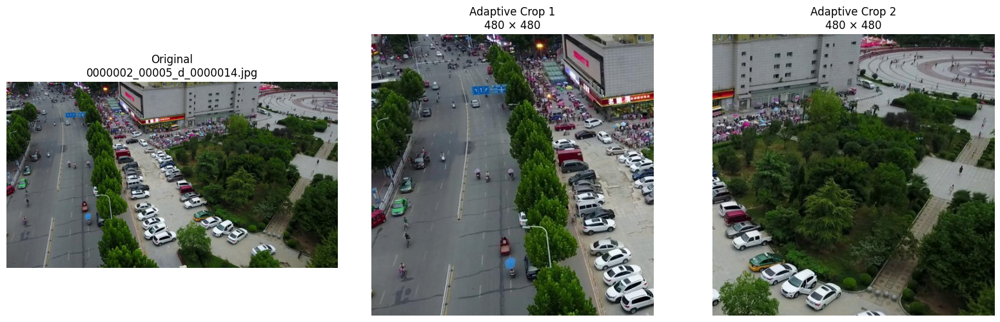

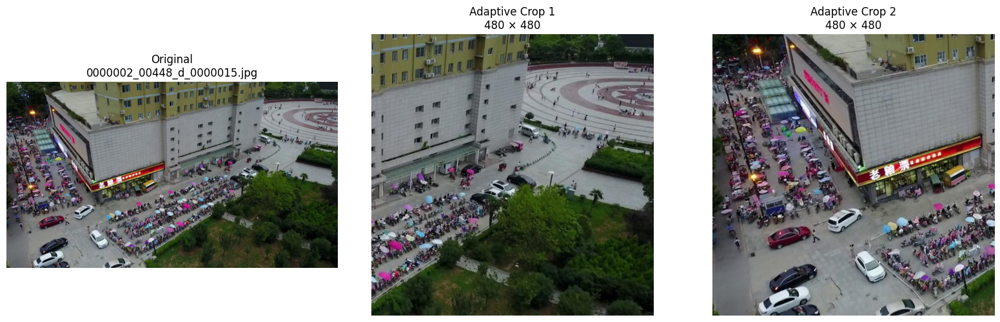

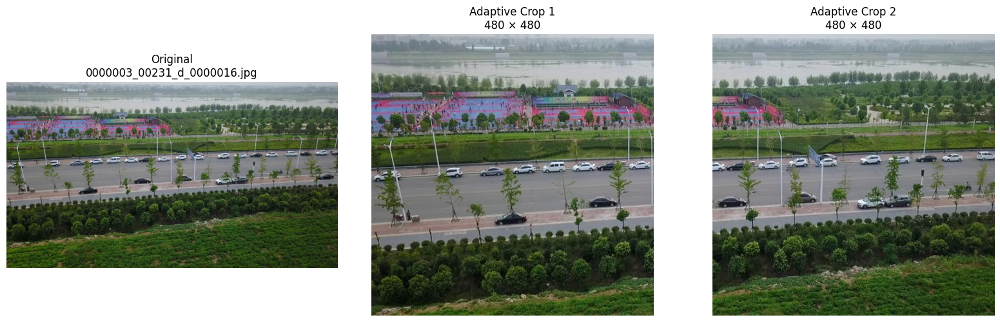

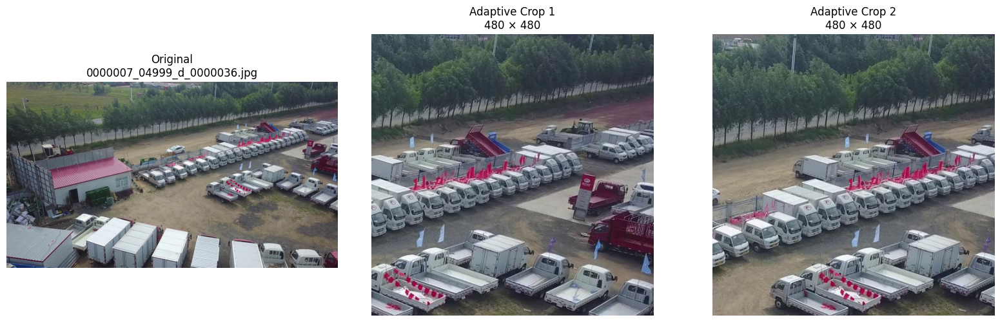

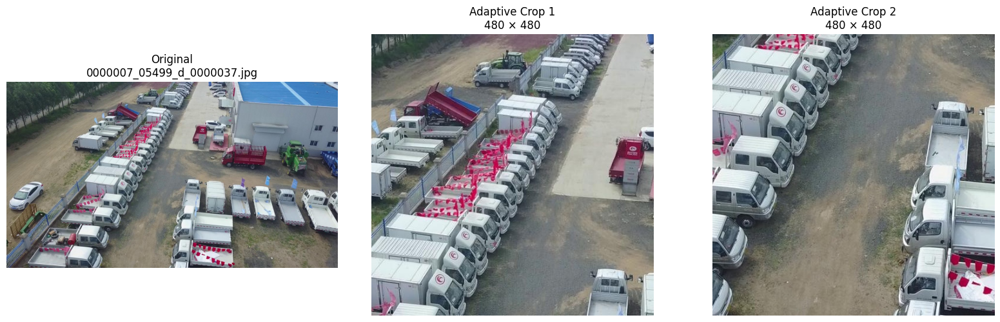

In [126]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Display the first 5 source images and their two crops
for image_path in pilot_images[:5]:
    crop_paths = sorted(PILOT_IMAGES.glob(f"{image_path.stem}_r*.jpg"))

    original = Image.open(image_path).convert("RGB")

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(original)
    axes[0].set_title(f"Original\n{image_path.name}")

    for i, ax in enumerate(axes[1:]):
        if i < len(crop_paths):
            crop = Image.open(crop_paths[i]).convert("RGB")
            ax.imshow(crop)
            ax.set_title(f"Adaptive Crop {i + 1}\n480 × 480")
        else:
            ax.set_visible(False)

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Regional Specialist — Generate Two Adaptive Crops per Training Image

Generate up to two 480 × 480 crops per training image using the existing adaptive selector. Transform the ground-truth boxes into crop coordinates and validate the generated dataset before training.

In [127]:
from pathlib import Path
from collections import Counter
import cv2
import yaml

# --------------------------------------------------
# Configuration
# --------------------------------------------------
PROJECT_DIR = Path.home() / "Desktop" / "ML" / "ML" / "YOLOv8-VisDrone"
DATASET_ROOT = PROJECT_DIR / "datasets" / "VisDrone"

SOURCE_IMAGES = DATASET_ROOT / "images" / "train"
SOURCE_LABELS = DATASET_ROOT / "labels" / "train"

OUTPUT_ROOT = DATASET_ROOT / "regional_crops"
OUTPUT_IMAGES = OUTPUT_ROOT / "images" / "train"
OUTPUT_LABELS = OUTPUT_ROOT / "labels" / "train"
OUTPUT_YAML = OUTPUT_ROOT / "regional_specialist.yaml"

CROP_SIZE = 480
STRIDE = 360
NUM_CLASSES = 10

assert "selection_model" in globals()
assert "generate_regions" in globals()
assert "predictions_from_result" in globals()
assert "select_top_regions" in globals()

assert SOURCE_IMAGES.is_dir()
assert SOURCE_LABELS.is_dir()
assert (
    PROJECT_DIR / "runs" / "visdrone_baseline" / "weights" / "best.pt"
).is_file()

# Prevent accidental mixing with an existing dataset.
if OUTPUT_IMAGES.exists() and any(OUTPUT_IMAGES.iterdir()):
    raise RuntimeError(
        f"Output directory is not empty: {OUTPUT_IMAGES}\n"
        "Rename or clear the existing generated dataset intentionally first."
    )

OUTPUT_IMAGES.mkdir(parents=True, exist_ok=True)
OUTPUT_LABELS.mkdir(parents=True, exist_ok=True)

image_files = sorted(
    p for p in SOURCE_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

# --------------------------------------------------
# Transform original YOLO labels into crop coordinates
# --------------------------------------------------
def transform_yolo_labels(label_path, image_width, image_height, x1, y1, x2, y2):
    crop_width = x2 - x1
    crop_height = y2 - y1
    transformed = []

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            if len(parts) != 5:
                raise ValueError(f"Malformed label: {label_path}")

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            if not 0 <= cls < NUM_CLASSES:
                raise ValueError(f"Invalid class ID {cls}: {label_path}")

            bx1 = (xc - bw / 2) * image_width
            by1 = (yc - bh / 2) * image_height
            bx2 = (xc + bw / 2) * image_width
            by2 = (yc + bh / 2) * image_height

            ix1 = max(bx1, x1)
            iy1 = max(by1, y1)
            ix2 = min(bx2, x2)
            iy2 = min(by2, y2)

            if ix2 <= ix1 or iy2 <= iy1:
                continue

            nx = ((ix1 + ix2) / 2 - x1) / crop_width
            ny = ((iy1 + iy2) / 2 - y1) / crop_height
            nw = (ix2 - ix1) / crop_width
            nh = (iy2 - iy1) / crop_height

            transformed.append(
                f"{cls} {nx:.6f} {ny:.6f} {nw:.6f} {nh:.6f}"
            )

    return transformed


# --------------------------------------------------
# Generate two adaptive crops per image
# --------------------------------------------------
stats = Counter()
processing_errors = []

for index, image_path in enumerate(image_files, start=1):
    image = cv2.imread(str(image_path))
    if image is None:
        processing_errors.append(f"Unreadable image: {image_path.name}")
        continue

    height, width = image.shape[:2]
    label_path = SOURCE_LABELS / f"{image_path.stem}.txt"

    if not label_path.is_file():
        processing_errors.append(f"Missing label: {label_path.name}")
        continue

    if width < CROP_SIZE or height < CROP_SIZE:
        processing_errors.append(f"Image too small: {image_path.name}")
        continue

    regions = generate_regions(
        width, height, crop_size=CROP_SIZE, stride=STRIDE
    )

    result = selection_model.predict(
        image, imgsz=1280, conf=0.05, verbose=False
    )[0]

    predictions = predictions_from_result(result)
    selected_regions = select_top_regions(
        regions, predictions, width, height
    )

    saved_coords = set()
    saved_for_image = 0

    for region in selected_regions:
        if saved_for_image >= 2:
            break

        x1, y1, x2, y2 = map(int, region["coords"])

        # Keep crop fully inside the image.
        x1 = max(0, min(x1, width - CROP_SIZE))
        y1 = max(0, min(y1, height - CROP_SIZE))
        x2, y2 = x1 + CROP_SIZE, y1 + CROP_SIZE

        coords = (x1, y1, x2, y2)
        if coords in saved_coords:
            continue

        crop = image[y1:y2, x1:x2]
        if crop.shape[:2] != (CROP_SIZE, CROP_SIZE):
            raise ValueError(f"Incorrect crop dimensions: {image_path.name}")

        crop_id = f"{image_path.stem}_adaptive{saved_for_image}"
        image_out = OUTPUT_IMAGES / f"{crop_id}.jpg"
        label_out = OUTPUT_LABELS / f"{crop_id}.txt"

        transformed = transform_yolo_labels(
            label_path, width, height, x1, y1, x2, y2
        )

        if not cv2.imwrite(str(image_out), crop):
            raise RuntimeError(f"Could not save crop: {image_out}")

        label_out.write_text(
            "\n".join(transformed) + ("\n" if transformed else ""),
            encoding="utf-8"
        )

        stats["crops"] += 1
        stats["boxes"] += len(transformed)
        saved_for_image += 1
        saved_coords.add(coords)

    if saved_for_image < 2:
        stats["images_with_fewer_than_two_crops"] += 1

    if index % 100 == 0 or index == len(image_files):
        print(f"Processed {index}/{len(image_files)} training images")

# --------------------------------------------------
# Validate generated files
# --------------------------------------------------
generated_images = sorted(OUTPUT_IMAGES.glob("*.jpg"))
generated_labels = sorted(OUTPUT_LABELS.glob("*.txt"))

image_stems = {p.stem for p in generated_images}
label_stems = {p.stem for p in generated_labels}

missing_labels = image_stems - label_stems
orphan_labels = label_stems - image_stems
invalid_rows = []
empty_labels = 0

for label_path in generated_labels:
    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        empty_labels += 1
        continue

    for line_number, line in enumerate(text.splitlines(), start=1):
        parts = line.split()
        try:
            if len(parts) != 5:
                raise ValueError("Expected 5 values")

            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            if not 0 <= cls < NUM_CLASSES:
                raise ValueError("Invalid class ID")
            if not (
                0 <= x <= 1 and 0 <= y <= 1
                and 0 < w <= 1 and 0 < h <= 1
            ):
                raise ValueError("Invalid normalized box")
            if x - w / 2 < -1e-5 or x + w / 2 > 1 + 1e-5:
                raise ValueError("Box outside crop width")
            if y - h / 2 < -1e-5 or y + h / 2 > 1 + 1e-5:
                raise ValueError("Box outside crop height")

        except Exception as error:
            invalid_rows.append(
                (label_path.name, line_number, str(error))
            )

with open(DATASET_ROOT / "VisDrone.yaml", "r", encoding="utf-8") as f:
    original_yaml = yaml.safe_load(f)

specialist_yaml = {
    "path": str(OUTPUT_ROOT.resolve()),
    "train": "images/train",
    "val": str((DATASET_ROOT / "images" / "val").resolve()),
    "test": str((DATASET_ROOT / "images" / "test").resolve()),
    "names": original_yaml["names"],
    "nc": NUM_CLASSES,
}

with open(OUTPUT_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(specialist_yaml, f, sort_keys=False)

print("\n--- CROP DATASET SUMMARY ---")
print("Source training images:", len(image_files))
print("Generated crops:", len(generated_images))
print("Transformed boxes:", stats["boxes"])
print("Empty label files:", empty_labels)
print("Images missing labels:", len(missing_labels))
print("Orphan label files:", len(orphan_labels))
print("Invalid label rows:", len(invalid_rows))
print("Processing errors:", len(processing_errors))
print("Images with fewer than 2 crops:", stats["images_with_fewer_than_two_crops"])
print("Dataset YAML:", OUTPUT_YAML)

if invalid_rows:
    print("First invalid labels:", invalid_rows[:5])
if processing_errors:
    print("First processing errors:", processing_errors[:5])

assert not missing_labels, "Generated images are missing label files."
assert not orphan_labels, "Orphan label files found."
assert not invalid_rows, "Generated labels failed validation."
assert not processing_errors, "Some source images failed processing."

print("Dataset generation and label validation completed.")

Processed 100/6471 training images
Processed 200/6471 training images
Processed 300/6471 training images
Processed 400/6471 training images
Processed 500/6471 training images
Processed 600/6471 training images
Processed 700/6471 training images
Processed 800/6471 training images
Processed 900/6471 training images
Processed 1000/6471 training images
Processed 1100/6471 training images
Processed 1200/6471 training images
Processed 1300/6471 training images
Processed 1400/6471 training images
Processed 1500/6471 training images
Processed 1600/6471 training images
Processed 1700/6471 training images
Processed 1800/6471 training images
Processed 1900/6471 training images
Processed 2000/6471 training images
Processed 2100/6471 training images
Processed 2200/6471 training images
Processed 2300/6471 training images
Processed 2400/6471 training images
Processed 2500/6471 training images
Processed 2600/6471 training images
Processed 2700/6471 training images
Processed 2800/6471 training images
P

AssertionError: Generated labels failed validation.

In [129]:
from pathlib import Path

invalid_files = sorted({
    OUTPUT_LABELS / row[0]
    for row in invalid_rows
})

repaired_boxes = 0
unrepairable = []

for label_path in invalid_files:
    if not label_path.exists():
        unrepairable.append((str(label_path), "Label file not found"))
        continue

    lines = label_path.read_text(encoding="utf-8").splitlines()
    changed = False

    for line_idx, line in enumerate(lines):
        parts = line.split()

        if len(parts) != 5:
            continue

        try:
            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            continue

        left, top = x - w / 2, y - h / 2
        right, bottom = x + w / 2, y + h / 2
        tol = 1e-4

        # Repair only tiny boundary overshoots.
        if (
            -tol <= left <= 1 + tol
            and -tol <= top <= 1 + tol
            and -tol <= right <= 1 + tol
            and -tol <= bottom <= 1 + tol
            and w > 0 and h > 0
        ):
            left = max(0.0, min(1.0, left))
            top = max(0.0, min(1.0, top))
            right = max(0.0, min(1.0, right))
            bottom = max(0.0, min(1.0, bottom))

            new_w = right - left
            new_h = bottom - top

            if new_w > 0 and new_h > 0:
                new_x = (left + right) / 2
                new_y = (top + bottom) / 2

                lines[line_idx] = (
                    f"{cls} {new_x:.8f} {new_y:.8f} "
                    f"{new_w:.8f} {new_h:.8f}"
                )
                repaired_boxes += 1
                changed = True
        else:
            unrepairable.append(
                (label_path.name, line_idx + 1, line)
            )

    if changed:
        label_path.write_text(
            "\n".join(lines) + "\n",
            encoding="utf-8"
        )

print("Label files examined:", len(invalid_files))
print("Boxes repaired:", repaired_boxes)
print("Unrepairable rows:", len(unrepairable))
print("Examples:", unrepairable[:10])

Label files examined: 143
Boxes repaired: 5873
Unrepairable rows: 147
Examples: [('0000013_00465_d_0000067_adaptive0.txt', 51, '1 0.802084 1.000000 0.129166 0.000000'), ('0000068_00571_d_0000003_adaptive0.txt', 5, '0 0.000000 0.041667 0.000000 0.037499'), ('0000068_00571_d_0000003_adaptive0.txt', 30, '0 0.000000 0.531249 0.000000 0.075000'), ('0000068_01001_d_0000004_adaptive0.txt', 24, '0 1.000000 0.508333 0.000000 0.079166'), ('0000070_06990_d_0000007_adaptive0.txt', 36, '0 0.000000 0.043750 0.000000 0.070833'), ('0000084_00281_d_0000002_adaptive1.txt', 11, '0 0.459376 0.000000 0.018750 0.000000'), ('0000133_00846_d_0000143_adaptive1.txt', 12, '3 1.000000 0.530208 0.000000 0.127082'), ('0000136_00456_d_0000155_adaptive0.txt', 33, '3 0.193752 0.000000 0.033332 0.000000'), ('0000150_01030_d_0000072_adaptive0.txt', 43, '3 1.000000 0.540626 0.000000 0.056250'), ('0000195_00000_d_0000126_adaptive0.txt', 70, '9 0.394792 0.000000 0.006252 0.000000')]


In [130]:
from pathlib import Path

removed_boxes = 0
remaining_invalid = []
empty_labels = 0

for label_path in OUTPUT_LABELS.glob("*.txt"):
    lines = label_path.read_text(encoding="utf-8").splitlines()
    valid_lines = []

    for line_num, line in enumerate(lines, start=1):
        parts = line.split()

        try:
            if len(parts) != 5:
                raise ValueError("Expected 5 fields")

            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            valid = (
                0 <= cls < 10
                and all(map(lambda v: 0 <= v <= 1, [x, y, w, h]))
                and w > 0
                and h > 0
                and x - w / 2 >= -1e-6
                and y - h / 2 >= -1e-6
                and x + w / 2 <= 1 + 1e-6
                and y + h / 2 <= 1 + 1e-6
            )

            if valid:
                valid_lines.append(line)
            else:
                removed_boxes += 1
                if w > 0 and h > 0:
                    remaining_invalid.append(
                        (label_path.name, line_num, line)
                    )

        except (ValueError, IndexError):
            removed_boxes += 1
            remaining_invalid.append(
                (label_path.name, line_num, line)
            )

    if not valid_lines:
        empty_labels += 1

    label_path.write_text(
        "\n".join(valid_lines) + ("\n" if valid_lines else ""),
        encoding="utf-8"
    )

print("Invalid boxes removed:", removed_boxes)
print("Labels with no remaining objects:", empty_labels)
print("Remaining invalid boxes:", len(remaining_invalid))
print("Examples:", remaining_invalid[:10])

Invalid boxes removed: 147
Labels with no remaining objects: 328
Remaining invalid boxes: 0
Examples: []


In [131]:
from pathlib import Path
from PIL import Image
import yaml

# 1. Check image-label pairing
images = sorted(
    p for p in OUTPUT_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)
image_stems = {p.stem for p in images}
label_stems = {p.stem for p in OUTPUT_LABELS.glob("*.txt")}

missing_labels = sorted(image_stems - label_stems)
orphan_labels = sorted(label_stems - image_stems)

# 2. Check image dimensions
small_images = []
for p in images:
    try:
        with Image.open(p) as im:
            if im.width != 480 or im.height != 480:
                small_images.append((p.name, im.size))
    except Exception as e:
        small_images.append((p.name, str(e)))

# 3. Count valid boxes and empty labels
box_count = 0
empty_label_count = 0
invalid_rows_check = []

for p in OUTPUT_LABELS.glob("*.txt"):
    lines = [line.strip() for line in p.read_text().splitlines() if line.strip()]
    if not lines:
        empty_label_count += 1

    for line_num, line in enumerate(lines, 1):
        parts = line.split()
        try:
            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])
            if (
                len(parts) != 5 or not 0 <= cls < 10
                or not all(0 <= v <= 1 for v in (x, y, w, h))
                or w <= 0 or h <= 0
                or x - w / 2 < -1e-6 or y - h / 2 < -1e-6
                or x + w / 2 > 1 + 1e-6
                or y + h / 2 > 1 + 1e-6
            ):
                invalid_rows_check.append((p.name, line_num, line))
            else:
                box_count += 1
        except Exception:
            invalid_rows_check.append((p.name, line_num, line))

print("Crop images:", len(images))
print("Crop label files:", len(label_stems))
print("Missing labels:", len(missing_labels), missing_labels[:5])
print("Orphan labels:", len(orphan_labels), orphan_labels[:5])
print("Non-480x480 images:", len(small_images), small_images[:5])
print("Valid boxes:", box_count)
print("Empty labels:", empty_label_count)
print("Invalid rows:", len(invalid_rows_check), invalid_rows_check[:5])
print("Original training images:", len(list(SOURCE_IMAGES.glob("*"))))
print("Specialist YAML exists:", OUTPUT_YAML.exists())

Crop images: 12940
Crop label files: 12940
Missing labels: 0 []
Orphan labels: 0 []
Non-480x480 images: 0 []
Valid boxes: 295518
Empty labels: 328
Invalid rows: 0 []
Original training images: 6471
Specialist YAML exists: True


In [132]:
from pathlib import Path
import yaml
from ultralytics import YOLO

# Paths
BASELINE_WEIGHTS = PROJECT_DIR / "runs" / "visdrone_baseline" / "weights" / "best.pt"
SPECIALIST_RUN = PROJECT_DIR / "runs" / "regional_specialist"

# Verify configuration and checkpoint
assert OUTPUT_YAML.exists(), f"Missing YAML: {OUTPUT_YAML}"
assert BASELINE_WEIGHTS.exists(), f"Missing baseline: {BASELINE_WEIGHTS}"

with open(OUTPUT_YAML, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

print("Dataset YAML:", OUTPUT_YAML)
print("Training path:", cfg["train"])
print("Validation path:", cfg["val"])
print("Classes:", cfg["nc"])
print("Baseline checkpoint:", BASELINE_WEIGHTS)

# Confirm that validation uses original images, not generated crops
assert Path(cfg["val"]).resolve() == (
    DATASET_ROOT / "images" / "val"
).resolve(), "Validation must use the original full images."

assert cfg["nc"] == 10, "Unexpected class count."

print("\nPreflight passed. Ready to train.")

Dataset YAML: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\regional_crops\regional_specialist.yaml
Training path: images/train
Validation path: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Classes: 10
Baseline checkpoint: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt

Preflight passed. Ready to train.


## Stage 2 — Full-Image Fine-Tuning and Regional Specialist Training

### Objective
Train two additional models while preserving the original 20-epoch YOLOv8n VisDrone baseline for controlled comparison.

### Model A — Original Baseline
- **Checkpoint:** `runs/visdrone_baseline/weights/best.pt`
- **Training:** Already completed for 20 epochs.
- **Purpose:** Serves as the reference model.
- **Preservation:** The original checkpoint is not modified or deleted.

### Model B — Full-Image Fine-Tuning
- **Initialization:** The existing Model A checkpoint.
- **Dataset:** Original VisDrone training images.
- **Epoch limit:** 10 additional epochs.
- **Image size:** 640 × 640.
- **Batch size:** 2.
- **Purpose:** Investigate whether additional training at higher resolution improves object detection.
- **Output:** `runs/visdrone_finetuned/weights/best.pt`
- **Backup copy:** `checkpoints/visdrone_finetuned/best.pt`

### Model C — Regional Specialist
- **Initialization:** A copy of Model B's best checkpoint.
- **Dataset:** 12,940 generated 480 × 480 regional crops.
- **Epoch limit:** 15 additional epochs.
- **Image size:** 480 × 480.
- **Batch size:** 4.
- **Purpose:** Adapt the detector to selected image regions to investigate potential improvements in small-object detection.
- **Output:** `runs/regional_specialist/weights/best.pt`
- **Backup copy:** `checkpoints/regional_specialist/best.pt`

### Experimental Comparison

| Comparison | Research question |
|---|---|
| Model A vs. Model B | Does additional full-image fine-tuning improve detection? |
| Model B vs. Model C | Does regional-crop fine-tuning provide additional benefits? |
| Model A vs. Model C | Does the complete training approach outperform the original baseline? |

All models will be evaluated on the same untouched VisDrone validation set using mAP50, mAP50–95, precision, recall, and small-object recall.

**Important:** The epoch counts are maximums because early stopping is enabled. Model C's final performance must also be evaluated using the complete regional inference pipeline, including region selection and prediction fusion.

In [135]:
from pathlib import Path
import shutil
import yaml
import torch
from ultralytics import YOLO

# ============================================================
# 1. PATHS
# ============================================================
BASELINE = PROJECT_DIR / "runs" / "visdrone_baseline" / "weights" / "best.pt"

FULL_YAML = DATASET_ROOT / "VisDrone.yaml"
REGIONAL_YAML = OUTPUT_YAML

RUNS_DIR = PROJECT_DIR / "runs"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"

# Use NEW names so the interrupted 960px run remains preserved.
FULL_RUN_NAME = "visdrone_finetuned_640"
REGIONAL_RUN_NAME = "regional_specialist_640"

FULL_RUN = RUNS_DIR / FULL_RUN_NAME
REGIONAL_RUN = RUNS_DIR / REGIONAL_RUN_NAME

FULL_COPY_DIR = CHECKPOINTS_DIR / FULL_RUN_NAME
REGIONAL_COPY_DIR = CHECKPOINTS_DIR / REGIONAL_RUN_NAME

FULL_COPY = FULL_COPY_DIR / "best.pt"
REGIONAL_COPY = REGIONAL_COPY_DIR / "best.pt"

# ============================================================
# 2. SAFETY CHECKS
# ============================================================
assert BASELINE.exists(), f"Baseline checkpoint missing: {BASELINE}"
assert FULL_YAML.exists(), f"Full-image YAML missing: {FULL_YAML}"
assert REGIONAL_YAML.exists(), f"Regional YAML missing: {REGIONAL_YAML}"

for path in [FULL_RUN, REGIONAL_RUN, FULL_COPY, REGIONAL_COPY]:
    assert not path.exists(), (
        f"Output already exists: {path}\n"
        "Choose a new name to avoid overwriting previous work."
    )

with open(FULL_YAML, "r", encoding="utf-8") as f:
    full_cfg = yaml.safe_load(f)

with open(REGIONAL_YAML, "r", encoding="utf-8") as f:
    regional_cfg = yaml.safe_load(f)

def class_count(cfg):
    if "names" in cfg:
        return len(cfg["names"])
    return cfg.get("nc")

assert class_count(full_cfg) == 10, "Full dataset must have 10 classes."
assert class_count(regional_cfg) == 10, "Regional dataset must have 10 classes."

device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", torch.cuda.get_device_name(0) if device == 0 else "CPU")
print("Original baseline:", BASELINE)
print("Model B resolution: 640, batch: 4, maximum epochs: 10")
print("Model C resolution: 480, batch: 4, maximum epochs: 15")

# ============================================================
# 3. MODEL B — FULL-IMAGE FINE-TUNING
# ============================================================
print("\nMODEL B: FULL-IMAGE FINE-TUNING")

model_b = YOLO(str(BASELINE))

model_b.train(
    data=str(FULL_YAML),
    epochs=10,
    imgsz=640,
    batch=4,
    device=device,
    workers=2,
    project=str(RUNS_DIR),
    name=FULL_RUN_NAME,
    exist_ok=False,
    patience=5,
    amp=True,
    plots=True,
    save=True,
    seed=42,
)

model_b_best = FULL_RUN / "weights" / "best.pt"
assert model_b_best.exists(), f"Model B checkpoint missing: {model_b_best}"

FULL_COPY_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(model_b_best, FULL_COPY)

print("Model B best checkpoint:", model_b_best)
print("Model B independent copy:", FULL_COPY)

# ============================================================
# 4. MODEL C — REGIONAL SPECIALIST
# ============================================================
print("\nMODEL C: REGIONAL SPECIALIST")

model_c = YOLO(str(FULL_COPY))

model_c.train(
    data=str(REGIONAL_YAML),
    epochs=15,
    imgsz=480,
    batch=4,
    device=device,
    workers=2,
    project=str(RUNS_DIR),
    name=REGIONAL_RUN_NAME,
    exist_ok=False,
    patience=5,
    amp=True,
    plots=True,
    save=True,
    seed=42,
)

model_c_best = REGIONAL_RUN / "weights" / "best.pt"
assert model_c_best.exists(), f"Model C checkpoint missing: {model_c_best}"

REGIONAL_COPY_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(model_c_best, REGIONAL_COPY)

# ============================================================
# 5. SUMMARY
# ============================================================
print("\nTRAINING COMPLETE")
print("Model A — Original 20-epoch baseline:", BASELINE)
print("Model B — Full-image fine-tuned:", model_b_best)
print("Model B copy:", FULL_COPY)
print("Model C — Regional specialist:", model_c_best)
print("Model C copy:", REGIONAL_COPY)

Device: NVIDIA GeForce RTX 3050 Laptop GPU
Original baseline: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Model B resolution: 640, batch: 4, maximum epochs: 10
Model C resolution: 480, batch: 4, maximum epochs: 15

MODEL B: FULL-IMAGE FINE-TUNING
New https://pypi.org/project/ultralytics/8.4.191 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1

In [136]:
from pathlib import Path

checkpoints = {
    "Model A — Original baseline": BASELINE,
    "Model B — Full-image fine-tuned": PROJECT_DIR / "checkpoints" / "visdrone_finetuned_640" / "best.pt",
    "Model C — Regional specialist": PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt",
}

print("CHECKPOINT VERIFICATION")
for name, path in checkpoints.items():
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")
    print(f"  {path}")

print("\nVALIDATION DATASET")
print("YAML:", FULL_YAML)
print("Validation images:", DATASET_ROOT / "images" / "val")
print("Validation directory exists:", (DATASET_ROOT / "images" / "val").exists())

CHECKPOINT VERIFICATION
Model A — Original baseline: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Model B — Full-image fine-tuned: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\visdrone_finetuned_640\best.pt
Model C — Regional specialist: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\regional_specialist_640\best.pt

VALIDATION DATASET
YAML: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\VisDrone.yaml
Validation images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Validation directory exists: True


In [137]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# Original validation dataset
DATA_YAML = str(FULL_YAML)

models = {
    "A_Baseline": str(BASELINE),
    "B_Finetuned": str(PROJECT_DIR / "checkpoints" / "visdrone_finetuned_640" / "best.pt"),
    "C_Regional_Direct": str(PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt"),
}

results = []

for model_name, checkpoint in models.items():
    print(f"\n{'=' * 60}")
    print(f"Evaluating: {model_name}")
    print(f"Checkpoint: {checkpoint}")
    print(f"{'=' * 60}")

    model = YOLO(checkpoint)

    metrics = model.val(
        data=DATA_YAML,
        split="val",
        imgsz=640,
        batch=2,
        device=0,
        workers=2,
        plots=False,
        verbose=False,
        project=str(PROJECT_DIR / "runs" / "evaluation"),
        name=model_name,
        exist_ok=True
    )

    results.append({
        "Model": model_name,
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
    })

    del model
    print(f"Completed: {model_name}")

results_df = pd.DataFrame(results)
display(results_df.round(4))

# Save comparison table
output_csv = PROJECT_DIR / "runs" / "evaluation" / "direct_model_comparison.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_csv, index=False)

print("\nResults saved to:", output_csv)


Evaluating: A_Baseline
Checkpoint: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Ultralytics 8.4.178  Python-3.11.4 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 531.0±124.6 MB/s, size: 142.5 KB)
val: Scanning C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s
WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 274/274 25.3it/s 10.8s0.0s
     

,Model,mAP50,mAP50-95,Precision,Recall
0,A_Baseline,0.2687,0.1510,0.3961,0.2970
1,B_Finetuned,0.2738,0.1537,0.4042,0.3023
2,C_Regional_Direct,0.2362,0.1307,0.3860,0.2686



Results saved to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\evaluation\direct_model_comparison.csv


In [138]:
import inspect

for name in [
    "generate_regions",
    "predictions_from_result",
    "select_top_regions",
]:
    obj = globals().get(name)
    print(f"\n{'=' * 60}\n{name}")
    if obj is None:
        print("NOT FOUND")
    else:
        print(inspect.getsource(obj))


generate_regions
def generate_regions(width, height, crop_size=480, stride=360):
    """Generate candidate crops while including image boundaries."""
    if width < crop_size or height < crop_size:
        raise ValueError(
            f"Image dimensions {width}x{height} are smaller than crop size {crop_size}."
        )

    def positions(length):
        values = list(range(0, max(1, length - crop_size + 1), stride))
        final_position = length - crop_size

        if not values or values[-1] != final_position:
            values.append(final_position)

        return sorted(set(values))

    xs = positions(width)
    ys = positions(height)

    return [
        (x, y, x + crop_size, y + crop_size)
        for y in ys
        for x in xs
    ]


predictions_from_result
def predictions_from_result(result, offset_x=0, offset_y=0):
    """Convert an Ultralytics result to dictionaries in original-image coordinates."""
    predictions = []

    if result.boxes is None:
        return

In [139]:
import inspect
from pathlib import Path

names = [
    "generate_regions",
    "predictions_from_result",
    "select_top_regions",
]

output = []

for name in names:
    obj = globals().get(name)
    output.append(f"\n{'=' * 70}\n{name}\n{'=' * 70}\n")
    output.append(inspect.getsource(obj) if obj else "NOT FOUND\n")

path = PROJECT_DIR / "evaluation_function_definitions.txt"
path.write_text("\n".join(output), encoding="utf-8")

print("Saved to:", path)
print(path.read_text(encoding="utf-8"))

Saved to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\evaluation_function_definitions.txt

generate_regions

def generate_regions(width, height, crop_size=480, stride=360):
    """Generate candidate crops while including image boundaries."""
    if width < crop_size or height < crop_size:
        raise ValueError(
            f"Image dimensions {width}x{height} are smaller than crop size {crop_size}."
        )

    def positions(length):
        values = list(range(0, max(1, length - crop_size + 1), stride))
        final_position = length - crop_size

        if not values or values[-1] != final_position:
            values.append(final_position)

        return sorted(set(values))

    xs = positions(width)
    ys = positions(height)

    return [
        (x, y, x + crop_size, y + crop_size)
        for y in ys
        for x in xs
    ]


predictions_from_result

def predictions_from_result(result, offset_x=0, offset_y=0):
    """Convert an Ultralytics result to dictionaries in orig

In [140]:
import inspect

print(inspect.getsource(select_top_regions))

def select_top_regions(regions, baseline_predictions, width, height):
    """Rank regions using baseline predictions only."""
    scored_regions = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        detections = []

        for pred in baseline_predictions:
            box = pred["box"]
            center_x = (box[0] + box[2]) / 2
            center_y = (box[1] + box[3]) / 2

            if x1 <= center_x < x2 and y1 <= center_y < y2:
                detections.append(pred)

        small_count = 0
        uncertain_count = 0

        for pred in detections:
            box = pred["box"]
            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (width * height)
                * 100
            )

            if area_percent <= SMALL_AREA_PERCENT:
                small_count += 1

            if pred["conf"] < 0.25:
                uncertain_count += 1

        score = (
            2.0 * small

In [141]:
import inspect
print(inspect.getsource(predictions_from_result))

def predictions_from_result(result, offset_x=0, offset_y=0):
    """Convert an Ultralytics result to dictionaries in original-image coordinates."""
    predictions = []

    if result.boxes is None:
        return predictions

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()

    for box, cls, conf in zip(boxes, classes, confidences):
        shifted_box = np.array(box, dtype=float)
        shifted_box[[0, 2]] += offset_x
        shifted_box[[1, 3]] += offset_y

        predictions.append({
            "box": shifted_box,
            "cls": int(cls),
            "conf": float(conf)
        })

    return predictions



In [142]:
from pathlib import Path

label_dir = DATASET_ROOT / "labels" / "val"
label_files = sorted(label_dir.glob("*.txt"))

print("Validation label files:", len(label_files))

for path in label_files[:3]:
    print(f"\n{path.name}")
    print(path.read_text(encoding="utf-8")[:1200])

Validation label files: 548

0000001_02999_d_0000005.txt
3 0.467708 0.572222 0.028125 0.085185
3 0.509896 0.590741 0.032292 0.085185
3 0.472656 0.703704 0.034896 0.101852
9 0.512760 0.757407 0.014063 0.050000
1 0.513281 0.752778 0.009896 0.035185
9 0.228125 0.874074 0.025000 0.042593
0 0.239844 0.987963 0.014063 0.024074
0 0.230990 0.857870 0.014063 0.045370
7 0.225260 0.799074 0.028646 0.048148
1 0.221615 0.809259 0.009896 0.033333
7 0.197396 0.765278 0.031250 0.056481
9 0.207031 0.717593 0.020313 0.040741
9 0.342708 0.688426 0.029167 0.039815
6 0.363281 0.709259 0.048438 0.038889
9 0.267188 0.744444 0.026042 0.053704
6 0.300781 0.741667 0.035937 0.037037
9 0.309115 0.715741 0.025521 0.031481
9 0.309896 0.681019 0.025000 0.028704
9 0.325521 0.646759 0.023958 0.026852
9 0.282031 0.701389 0.023438 0.026852
9 0.282813 0.682870 0.026042 0.025000
7 0.326562 0.626389 0.025000 0.045370
9 0.294271 0.664352 0.029167 0.032407
7 0.295573 0.644444 0.032813 0.053704
7 0.288542 0.602778 0.023958 0.

In [143]:
import inspect

source = inspect.getsource(select_top_regions)
for start in range(0, len(source), 1200):
    print(f"\n--- Characters {start}:{start + 1200} ---")
    print(source[start:start + 1200])


--- Characters 0:1200 ---
def select_top_regions(regions, baseline_predictions, width, height):
    """Rank regions using baseline predictions only."""
    scored_regions = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        detections = []

        for pred in baseline_predictions:
            box = pred["box"]
            center_x = (box[0] + box[2]) / 2
            center_y = (box[1] + box[3]) / 2

            if x1 <= center_x < x2 and y1 <= center_y < y2:
                detections.append(pred)

        small_count = 0
        uncertain_count = 0

        for pred in detections:
            box = pred["box"]
            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (width * height)
                * 100
            )

            if area_percent <= SMALL_AREA_PERCENT:
                small_count += 1

            if pred["conf"] < 0.25:
                uncertain_count += 1

        score 

In [144]:
import yaml

with open(OUTPUT_YAML, "r", encoding="utf-8") as f:
    regional_cfg = yaml.safe_load(f)

print("Regional YAML:", OUTPUT_YAML)
print("Regional validation path:", regional_cfg.get("val"))
print("Original validation images:", DATASET_ROOT / "images" / "val")
print("Crop size:", 480)
print("Regions selected per image:", 2)
print("Region selector available:", callable(globals().get("select_top_regions")))
print("Prediction converter available:", callable(globals().get("predictions_from_result")))

Regional YAML: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\regional_crops\regional_specialist.yaml
Regional validation path: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Original validation images: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Crop size: 480
Regions selected per image: 2
Region selector available: True
Prediction converter available: True



## Validation Setup: Four Model Configurations

This cell verifies the trained checkpoints and original VisDrone validation dataset before evaluation.

**Models:**
- **A — Baseline:** Original model, full-image inference.
- **B — Fine-tuned:** Fine-tuned model, full-image inference.
- **A + Region:** Model A with additional detections from regional crops using Model C.
- **B + Region:** Model B with additional detections from regional crops using Model C.

**Dataset:** 548 original validation images and their corresponding labels. All configurations use the same validation set for a fair comparison.

**Planned evaluation:** Overall precision, recall, F1-score, mAP@50, and mAP@50–95, plus separate small-, medium-, and large-object detection metrics. Object sizes will be determined from ground-truth bounding-box areas in the original images.

This cell only checks file paths and dataset availability; it does not perform inference or modify any checkpoints.


In [145]:
from pathlib import Path

import yaml

# Checkpoint paths
MODEL_A_PATH = BASELINE
MODEL_B_PATH = PROJECT_DIR / "checkpoints" / "visdrone_finetuned_640" / "best.pt"
MODEL_C_PATH = PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt"

# Original validation data
VAL_IMAGES = DATASET_ROOT / "images" / "val"
VAL_LABELS = DATASET_ROOT / "labels" / "val"

# Verify checkpoints
checkpoints = {
    "Model A — Baseline": MODEL_A_PATH,
    "Model B — Fine-tuned": MODEL_B_PATH,
    "Model C — Regional specialist": MODEL_C_PATH,
}

for name, path in checkpoints.items():
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")
    print(f"  {path}")

# Verify validation files
image_files = sorted(
    p for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
label_files = list(VAL_LABELS.glob("*.txt"))

print("\nValidation images:", len(image_files))
print("Validation label files:", len(label_files))
print("Validation images directory:", VAL_IMAGES)
print("Validation labels directory:", VAL_LABELS)

# Confirm the regional YAML uses the original validation images
with open(OUTPUT_YAML, "r", encoding="utf-8") as f:
    regional_cfg = yaml.safe_load(f)

print("\nRegional YAML validation path:", regional_cfg.get("val"))

assert all(p.exists() for p in checkpoints.values()), \
    "A checkpoint is missing. Check the printed paths."
assert len(image_files) > 0, "No validation images found."
assert len(label_files) > 0, "No validation labels found."

Model A — Baseline: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Model B — Fine-tuned: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\visdrone_finetuned_640\best.pt
Model C — Regional specialist: OK
  C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\regional_specialist_640\best.pt

Validation images: 548
Validation label files: 548
Validation images directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
Validation labels directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\labels\val

Regional YAML validation path: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val


In [146]:
import inspect

source = inspect.getsource(select_top_regions)
print(source)

def select_top_regions(regions, baseline_predictions, width, height):
    """Rank regions using baseline predictions only."""
    scored_regions = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        detections = []

        for pred in baseline_predictions:
            box = pred["box"]
            center_x = (box[0] + box[2]) / 2
            center_y = (box[1] + box[3]) / 2

            if x1 <= center_x < x2 and y1 <= center_y < y2:
                detections.append(pred)

        small_count = 0
        uncertain_count = 0

        for pred in detections:
            box = pred["box"]
            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (width * height)
                * 100
            )

            if area_percent <= SMALL_AREA_PERCENT:
                small_count += 1

            if pred["conf"] < 0.25:
                uncertain_count += 1

        score = (
            2.0 * small


## Load Models for Four-Way Evaluation

Load the three saved YOLO checkpoints:

- **Model A:** Original baseline.
- **Model B:** Fine-tuned full-image model.
- **Model C:** Regional specialist trained on image crops.

We will compare four configurations on the same 548 original VisDrone validation images:

1. Model A without regional inference.
2. Model B without regional inference.
3. Model A with regional inference using Model C.
4. Model B with regional inference using Model C.

For regional inference, the existing region-selection function will choose two candidate regions per image. Model C will detect objects in these crops, and crop coordinates will be mapped back to the original image.

The evaluation will report overall detection metrics and separate small-, medium-, and large-object results. No training or checkpoint modification occurs in this step.


In [147]:

from ultralytics import YOLO
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import yaml
import json
import time

# Checkpoint paths
MODEL_A_PATH = BASELINE
MODEL_B_PATH = PROJECT_DIR / "checkpoints" / "visdrone_finetuned_640" / "best.pt"
MODEL_C_PATH = PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt"

# Validation paths
VAL_IMAGES = DATASET_ROOT / "images" / "val"
VAL_LABELS = DATASET_ROOT / "labels" / "val"

# Evaluation settings
IMAGE_SIZE = 640
CROP_SIZE = 480
CROP_STRIDE = 360
REGIONS_PER_IMAGE = 2
CONF_THRESHOLD = 0.001
IOU_THRESHOLD = 0.5

# Load the three trained models
model_a = YOLO(str(MODEL_A_PATH))
model_b = YOLO(str(MODEL_B_PATH))
model_c = YOLO(str(MODEL_C_PATH))

# Sort validation images
val_images = sorted(
    p for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

assert len(val_images) == 548, (
    f"Expected 548 validation images, found {len(val_images)}"
)

assert all((VAL_LABELS / f"{p.stem}.txt").exists() for p in val_images), (
    "At least one validation image has no corresponding label file."
)

assert callable(select_top_regions)
assert callable(generate_regions)
assert callable(predictions_from_result)

print("Models loaded successfully.")
print("Validation images:", len(val_images))
print("Device:", "CUDA" if model_a.device.type == "cuda" else model_a.device)
print("Image size:", IMAGE_SIZE)
print("Crop size:", CROP_SIZE)
print("Regions per image:", REGIONS_PER_IMAGE)
print("Confidence threshold:", CONF_THRESHOLD)


Models loaded successfully.
Validation images: 548
Device: cpu
Image size: 640
Crop size: 480
Regions per image: 2
Confidence threshold: 0.001



## Check GPU Availability Before Evaluation

Check whether PyTorch can access the NVIDIA GPU and CUDA runtime.

GPU inference can substantially reduce evaluation time. Because the GPU has 4 GB of VRAM, inference will use a small batch size to limit memory usage.

This cell only checks the environment; it does not modify model weights.


In [148]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("CUDA unavailable. Evaluation will need to run on CPU.")


PyTorch version: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory: 4.0 GB


In [149]:

import torch

assert torch.cuda.is_available(), "CUDA is unavailable."

DEVICE = 0

# Verify the three saved checkpoints before GPU inference
for name, path in {
    "Model A": MODEL_A_PATH,
    "Model B": MODEL_B_PATH,
    "Model C": MODEL_C_PATH,
}.items():
    assert Path(path).is_file(), f"{name} checkpoint is missing: {path}"
    print(f"{name}: {path}")

print("\nGPU:", torch.cuda.get_device_name(DEVICE))
print("GPU memory:", round(
    torch.cuda.get_device_properties(DEVICE).total_memory / 1024**3, 2
), "GB")

print("\nReady for sequential GPU inference.")


Model A: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Model B: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\visdrone_finetuned_640\best.pt
Model C: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\regional_specialist_640\best.pt

GPU: NVIDIA GeForce RTX 3050 Laptop GPU
GPU memory: 4.0 GB

Ready for sequential GPU inference.



## Four-Way Evaluation: Full Images vs. Regional Inference

Evaluate these configurations on the same original VisDrone validation set:

1. Model A without regional inference.
2. Model B without regional inference.
3. Model A with regional inference using Model C.
4. Model B with regional inference using Model C.

For each configuration, calculate overall precision, recall, F1-score, mAP@50, and mAP@50–95. Also report precision, recall, F1-score, and ground-truth counts for small, medium, and large objects.

Ground-truth sizes are defined by original bounding-box area:
- Small: area < 32² pixels.
- Medium: 32² ≤ area < 96² pixels.
- Large: area ≥ 96² pixels.

All predictions are evaluated in original-image coordinates. The validation labels remain unchanged. Results are saved as CSV files for later analysis.


In [150]:

import inspect
from pathlib import Path

selector_source = inspect.getsource(select_top_regions)
selector_file = PROJECT_DIR / "select_top_regions_source.txt"
selector_file.write_text(selector_source, encoding="utf-8")

print("Saved selector source to:", selector_file)
print("Function length:", len(selector_source), "characters")
print("\nLast 1000 characters:\n")
print(selector_source[-1000:])


Saved selector source to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\select_top_regions_source.txt
Function length: 1891 characters

Last 1000 characters:

      if pred["conf"] < 0.25:
                uncertain_count += 1

        score = (
            2.0 * small_count
            + 1.5 * uncertain_count
            + 0.25 * len(detections)
        )

        scored_regions.append({
            "region": region_index,
            "coords": (x1, y1, x2, y2),
            "score": score
        })

    # Prefer high-scoring regions and avoid selecting nearly identical regions.
    scored_regions.sort(key=lambda item: item["score"], reverse=True)
    selected = []

    for candidate in scored_regions:
        if len(selected) >= REGIONS_PER_IMAGE:
            break

        overlaps_too_much = False

        for chosen in selected:
            iou = box_iou_one_to_many(
                candidate["coords"],
                [chosen["coords"]]
            )[0]

            if iou > 0.50:
 


## Inspect Regional Selection Logic

Inspect the complete region-selection function before running the four-way evaluation. The selector scores candidate crops using small-object detections, uncertain detections, and total detection count.

This check confirms how selected regions are represented so crop coordinates can be mapped back to the original images correctly. No models are retrained or modified.


In [151]:

selector_source = inspect.getsource(select_top_regions)

for start in range(0, len(selector_source), 500):
    print(f"\n--- Characters {start}:{min(start + 500, len(selector_source))} ---")
    print(selector_source[start:start + 500])




--- Characters 0:500 ---
def select_top_regions(regions, baseline_predictions, width, height):
    """Rank regions using baseline predictions only."""
    scored_regions = []

    for region_index, (x1, y1, x2, y2) in enumerate(regions):
        detections = []

        for pred in baseline_predictions:
            box = pred["box"]
            center_x = (box[0] + box[2]) / 2
            center_y = (box[1] + box[3]) / 2

            if x1 <= center_x < x2 and y1 <= center_y < y2:
                detections.append(pred)

--- Characters 500:1000 ---


        small_count = 0
        uncertain_count = 0

        for pred in detections:
            box = pred["box"]
            area_percent = (
                max(0, box[2] - box[0])
                * max(0, box[3] - box[1])
                / (width * height)
                * 100
            )

            if area_percent <= SMALL_AREA_PERCENT:
                small_count += 1

            if pred["conf"] < 0.25:
                uncerta


## Verify Region Selection Output

Print the final section of the existing region-selection function with line breaks preserved. This confirms the selected-region data structure needed by the regional inference pipeline.


In [152]:

selector_source = inspect.getsource(select_top_regions)

print("\n".join(
    f"{i + 1:03d}: {line}"
    for i, line in enumerate(selector_source.splitlines())
))


001: def select_top_regions(regions, baseline_predictions, width, height):
002:     """Rank regions using baseline predictions only."""
003:     scored_regions = []
004: 
005:     for region_index, (x1, y1, x2, y2) in enumerate(regions):
006:         detections = []
007: 
008:         for pred in baseline_predictions:
009:             box = pred["box"]
010:             center_x = (box[0] + box[2]) / 2
011:             center_y = (box[1] + box[3]) / 2
012: 
013:             if x1 <= center_x < x2 and y1 <= center_y < y2:
014:                 detections.append(pred)
015: 
016:         small_count = 0
017:         uncertain_count = 0
018: 
019:         for pred in detections:
020:             box = pred["box"]
021:             area_percent = (
022:                 max(0, box[2] - box[0])
023:                 * max(0, box[3] - box[1])
024:                 / (width * height)
025:                 * 100
026:             )
027: 
028:             if area_percent <= SMALL_AREA_PERCENT:
029:     


## Four-Way VisDrone Evaluation

Compare four configurations on the same 548 original validation images:

1. Model A — baseline, full-image inference only.
2. Model B — fine-tuned model, full-image inference only.
3. Model A + regional inference using Model C.
4. Model B + regional inference using Model C.

Settings:
- Full-image inference: imgsz=640, conf=0.001.
- Crop size: 480×480 pixels.
- Region selection: two regions per image, using the existing selector.
- Selector uncertainty threshold: 0.25.
- Model C crop inference: imgsz=640, conf=0.001.
- Fusion: retain full-image detections and add crop detections that are not same-class duplicates at IoU ≥ 0.50.

Evaluate all predictions against the original validation labels. Report overall precision, recall, F1, and size-specific precision, recall, F1, and ground-truth counts.

Small: ground-truth box area < 32² pixels.
Medium: 32² ≤ area < 96² pixels.
Large: area ≥ 96² pixels.

This experiment does not retrain or modify any checkpoint. The separate crop-confidence 0.35 experiment will be run later.


In [153]:

from pathlib import Path
from collections import defaultdict
import time
import cv2
import numpy as np
import pandas as pd
import torch

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------
DEVICE = 0
IMAGE_SIZE = 640
CROP_SIZE = 480
CROP_STRIDE = 360
REGIONS_PER_IMAGE = 2
CONF_THRESHOLD = 0.001
SELECTOR_UNCERTAINTY_THRESHOLD = 0.25
MATCH_IOU = 0.50

OUTPUT_DIR = PROJECT_DIR / "runs" / "four_way_size_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_A_PATH = BASELINE
MODEL_B_PATH = PROJECT_DIR / "checkpoints" / "visdrone_finetuned_640" / "best.pt"
MODEL_C_PATH = PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt"

model_a = YOLO(str(MODEL_A_PATH))
model_b = YOLO(str(MODEL_B_PATH))
model_c = YOLO(str(MODEL_C_PATH))

model_a.to("cuda:0")
model_b.to("cuda:0")
model_c.to("cuda:0")

val_images = sorted(
    p for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

SIZE_NAMES = ["small", "medium", "large"]
CLASS_NAMES = model_a.names

def box_iou(box1, box2):
    x1 = max(float(box1[0]), float(box2[0]))
    y1 = max(float(box1[1]), float(box2[1]))
    x2 = min(float(box1[2]), float(box2[2]))
    y2 = min(float(box1[3]), float(box2[3]))

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = max(0, float(box1[2] - box1[0])) * max(
        0, float(box1[3] - box1[1])
    )
    a2 = max(0, float(box2[2] - box2[0])) * max(
        0, float(box2[3] - box2[1])
    )
    return inter / max(a1 + a2 - inter, 1e-9)


def box_area(box):
    return max(0, float(box[2] - box[0])) * max(
        0, float(box[3] - box[1])
    )


def size_group(box):
    area = box_area(box)
    if area < 32**2:
        return "small"
    if area < 96**2:
        return "medium"
    return "large"


def load_ground_truth(label_path, width, height):
    gt = []
    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            values = line.strip().split()
            if len(values) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, values)
            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            gt.append({
                "box": np.array([x1, y1, x2, y2], dtype=float),
                "cls": int(cls),
            })
    return gt


def infer_image(model, image, conf=CONF_THRESHOLD):
    result = model.predict(
        source=image,
        imgsz=IMAGE_SIZE,
        conf=conf,
        device=DEVICE,
        verbose=False,
        max_det=1000,
    )[0]
    return predictions_from_result(result)


def deduplicate_crop_predictions(crop_preds, full_preds, iou_threshold=0.50):
    """Keep crop detections only if not duplicates of existing detections."""
    kept = list(full_preds)

    for pred in sorted(crop_preds, key=lambda p: p["conf"], reverse=True):
        duplicate = any(
            pred["cls"] == existing["cls"]
            and box_iou(pred["box"], existing["box"]) >= iou_threshold
            for existing in kept
        )
        if not duplicate:
            kept.append(pred)

    return kept


def regional_predictions(full_model, image):
    height, width = image.shape[:2]
    full_preds = infer_image(full_model, image)

    # If an image is smaller than the crop size, use full-image detections.
    if width < CROP_SIZE or height < CROP_SIZE:
        return full_preds, 0

    regions = generate_regions(
        width, height, crop_size=CROP_SIZE, stride=CROP_STRIDE
    )
    selected = select_top_regions(regions, full_preds, width, height)
    selected = selected[:REGIONS_PER_IMAGE]

    crop_preds = []

    for candidate in selected:
        x1, y1, x2, y2 = candidate["coords"]
        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        result = model_c.predict(
            source=crop,
            imgsz=IMAGE_SIZE,
            conf=CONF_THRESHOLD,
            device=DEVICE,
            verbose=False,
            max_det=1000,
        )[0]

        crop_preds.extend(
            predictions_from_result(result, offset_x=x1, offset_y=y1)
        )

    fused = deduplicate_crop_predictions(crop_preds, full_preds, MATCH_IOU)
    return fused, len(selected)


# ---------------------------------------------------------
# Run inference for all four configurations
# ---------------------------------------------------------
configurations = {
    "A_no_region": (model_a, False),
    "B_no_region": (model_b, False),
    "A_with_region": (model_a, True),
    "B_with_region": (model_b, True),
}

all_predictions = {}
ground_truth_by_image = {}
image_sizes = {}
timings = {}

for config_name, (full_model, use_regions) in configurations.items():
    print(f"\nRunning: {config_name}")
    config_predictions = {}
    start_time = time.time()
    region_count_total = 0

    for i, image_path in enumerate(val_images, start=1):
        image = cv2.imread(str(image_path))
        if image is None:
            raise RuntimeError(f"Could not read image: {image_path}")

        height, width = image.shape[:2]
        image_sizes[image_path.stem] = (width, height)

        label_path = VAL_LABELS / f"{image_path.stem}.txt"
        if image_path.stem not in ground_truth_by_image:
            ground_truth_by_image[image_path.stem] = load_ground_truth(
                label_path, width, height
            )

        if use_regions:
            preds, selected_count = regional_predictions(full_model, image)
            region_count_total += selected_count
        else:
            preds = infer_image(full_model, image)

        config_predictions[image_path.stem] = preds

        if i % 50 == 0 or i == len(val_images):
            print(f"  {i}/{len(val_images)} images processed")

    all_predictions[config_name] = config_predictions
    timings[config_name] = time.time() - start_time

    print(f"Elapsed: {timings[config_name] / 60:.1f} minutes")
    if use_regions:
        print("Selected regions:", region_count_total)


# ---------------------------------------------------------
# Compute precision, recall and F1 by object-size group
# ---------------------------------------------------------
def evaluate_group(predictions_by_image, ground_truth_by_image, group=None):
    tp = fp = fn = 0
    total_gt = 0

    for image_id, gt_all in ground_truth_by_image.items():
        preds_all = predictions_by_image.get(image_id, [])

        # Group GT by its ground-truth area.
        gt = [
            g for g in gt_all
            if group is None or size_group(g["box"]) == group
        ]

        # For size-specific metrics, filter predictions by their predicted
        # original-image box area to make the size definition explicit.
        preds = [
            p for p in preds_all
            if group is None or size_group(p["box"]) == group
        ]

        total_gt += len(gt)
        matched_gt = set()

        preds = sorted(preds, key=lambda p: p["conf"], reverse=True)

        for pred in preds:
            best_iou = 0.0
            best_index = None

            for j, target in enumerate(gt):
                if j in matched_gt or pred["cls"] != target["cls"]:
                    continue

                overlap = box_iou(pred["box"], target["box"])
                if overlap > best_iou:
                    best_iou = overlap
                    best_index = j

            if best_index is not None and best_iou >= MATCH_IOU:
                tp += 1
                matched_gt.add(best_index)
            else:
                fp += 1

        fn += len(gt) - len(matched_gt)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "GT": total_gt,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


# ---------------------------------------------------------
# Build summary tables
# ---------------------------------------------------------
summary_rows = []

for config_name, preds in all_predictions.items():
    for group in [None] + SIZE_NAMES:
        metrics = evaluate_group(preds, ground_truth_by_image, group)

        summary_rows.append({
            "Configuration": config_name,
            "Object size": group or "overall",
            **metrics,
            "Images": len(val_images),
            "Inference minutes": round(timings[config_name] / 60, 2),
        })

summary_df = pd.DataFrame(summary_rows)
summary_path = OUTPUT_DIR / "four_way_size_metrics.csv"
summary_df.to_csv(summary_path, index=False)

# Save all detections for reproducibility and later analysis.
prediction_rows = []
for config_name, image_predictions in all_predictions.items():
    for image_id, preds in image_predictions.items():
        for pred in preds:
            prediction_rows.append({
                "Configuration": config_name,
                "Image": image_id,
                "Class": pred["cls"],
                "Confidence": pred["conf"],
                "X1": float(pred["box"][0]),
                "Y1": float(pred["box"][1]),
                "X2": float(pred["box"][2]),
                "Y2": float(pred["box"][3]),
                "Predicted size": size_group(pred["box"]),
            })

predictions_df = pd.DataFrame(prediction_rows)
predictions_path = OUTPUT_DIR / "four_way_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("\n=== Four-Way Metrics ===")
display(
    summary_df.round(4).sort_values(
        ["Object size", "Configuration"]
    ).reset_index(drop=True)
)

print("\nMetrics saved to:", summary_path)
print("Predictions saved to:", predictions_path)



Running: A_no_region
  50/548 images processed
  100/548 images processed
  150/548 images processed
  200/548 images processed
  250/548 images processed
  300/548 images processed
  350/548 images processed
  400/548 images processed
  450/548 images processed
  500/548 images processed
  548/548 images processed
Elapsed: 0.3 minutes

Running: B_no_region
  50/548 images processed
  100/548 images processed
  150/548 images processed
  200/548 images processed
  250/548 images processed
  300/548 images processed
  350/548 images processed
  400/548 images processed
  450/548 images processed
  500/548 images processed
  548/548 images processed
Elapsed: 0.2 minutes

Running: A_with_region
  50/548 images processed
  100/548 images processed
  150/548 images processed
  200/548 images processed
  250/548 images processed
  300/548 images processed
  350/548 images processed
  400/548 images processed
  450/548 images processed
  500/548 images processed
  548/548 images processed
El

,Configuration,Object size,TP,FP,FN,GT,Precision,Recall,F1,Images,Inference minutes
0,A_no_region,large,948,4764,120,1068,0.1660,0.8876,0.2796,548,0.32
1,A_with_region,large,958,6811,110,1068,0.1233,0.8970,0.2168,548,8.85
2,B_no_region,large,946,5256,122,1068,0.1525,0.8858,0.2602,548,0.20
3,B_with_region,large,959,7352,109,1068,0.1154,0.8979,0.2045,548,8.67
4,A_no_region,medium,8862,105524,2243,11105,0.0775,0.7980,0.1412,548,0.32
5,A_with_region,medium,9376,137277,1729,11105,0.0639,0.8443,0.1189,548,8.85
6,B_no_region,medium,8910,102544,2195,11105,0.0799,0.8023,0.1454,548,0.20
7,B_with_region,medium,9412,134706,1693,11105,0.0653,0.8475,0.1213,548,8.67
8,A_no_region,overall,22032,325410,16727,38759,0.0634,0.5684,0.1141,548,0.32
9,A_with_region,overall,28933,585297,9826,38759,0.0471,0.7465,0.0886,548,8.85



Metrics saved to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\four_way_size_evaluation\four_way_size_metrics.csv
Predictions saved to: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\four_way_size_evaluation\four_way_predictions.csv



## Regional Specialist Ablation: Model A vs. Model C

Compare two regional detection pipelines using the same Model A full-image predictions and the same selected regions.

**Pipeline 1 — Baseline regional detector**
- Model A full-image inference at 1280.
- Two adaptive 480×480 regions selected using Model A predictions.
- Model A processes each crop at 480.
- Crop detections use confidence 0.001 and are filtered at 0.35.
- Duplicate detections are filtered using same-class IoU ≥ 0.50.

**Pipeline 2 — Trained regional specialist**
- Model A full-image inference at 1280.
- The same two regions are selected using Model A predictions.
- Model C processes each crop at 480.
- Crop detections use confidence 0.001 and are filtered at 0.35.
- Duplicate detections are filtered using same-class IoU ≥ 0.50.

Evaluate both pipelines on the original VisDrone validation images. Report precision, recall, F1, TP, FP, FN, and ground-truth counts for small, medium, and large objects.

This experiment isolates the effect of replacing the crop detector with the trained regional specialist.


In [154]:

# ---------------------------------------------------------
# Regional detector comparison: Model A crops vs. Model C
# ---------------------------------------------------------
import gc
import time
import cv2
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

FULL_SIZE = 1280
CROP_SIZE = 480
CROP_STRIDE = 360
REGIONS_PER_IMAGE = 2

FULL_CONF = 0.05
CROP_CONF = 0.001
FINAL_CROP_CONF = 0.35
REGION_UNCERTAINTY_THRESHOLD = 0.25
DUPLICATE_IOU = 0.50
MATCH_IOU = 0.50

REGIONAL_OUTPUT = OUTPUT_DIR / "regional_detector_ablation"
REGIONAL_OUTPUT.mkdir(parents=True, exist_ok=True)

# Load the original full-image model and the trained regional specialist.
model_a = YOLO(str(MODEL_A_PATH))
model_c = YOLO(str(MODEL_C_PATH))

model_a.to("cuda:0")
model_c.to("cuda:0")


def infer_for_ablation(model, image, imgsz, conf):
    result = model.predict(
        source=image,
        imgsz=imgsz,
        conf=conf,
        device=0,
        verbose=False,
        max_det=1000,
    )[0]
    return predictions_from_result(result)


def fuse_predictions(full_predictions, crop_predictions):
    """
    Preserve all full-image detections.
    Add crop detections only if their confidence passes the final filter
    and they are not same-class duplicates of an existing detection.
    """
    fused = list(full_predictions)

    crop_predictions = [
        p for p in crop_predictions
        if p["conf"] >= FINAL_CROP_CONF
    ]
    crop_predictions.sort(key=lambda p: p["conf"], reverse=True)

    for pred in crop_predictions:
        is_duplicate = any(
            pred["cls"] == existing["cls"]
            and box_iou(pred["box"], existing["box"]) >= DUPLICATE_IOU
            for existing in fused
        )
        if not is_duplicate:
            fused.append(pred)

    return fused


def run_regional_ablation(crop_model, model_label):
    predictions_by_image = {}
    region_counts = {}
    started = time.time()

    for i, image_path in enumerate(val_images, start=1):
        image = cv2.imread(str(image_path))
        if image is None:
            raise RuntimeError(f"Could not read {image_path}")

        h, w = image.shape[:2]

        # Full-image detections are identical in both pipelines.
        full_predictions = infer_for_ablation(
            model_a, image, imgsz=FULL_SIZE, conf=FULL_CONF
        )

        # Tiny images cannot support a 480x480 crop.
        if w < CROP_SIZE or h < CROP_SIZE:
            predictions_by_image[image_path.stem] = full_predictions
            region_counts[image_path.stem] = 0
            continue

        regions = generate_regions(
            w, h, crop_size=CROP_SIZE, stride=CROP_STRIDE
        )

        # Existing selector uses its internal 0.25 uncertainty threshold.
        selected = select_top_regions(
            regions, full_predictions, w, h
        )[:REGIONS_PER_IMAGE]

        crop_predictions = []

        for candidate in selected:
            x1, y1, x2, y2 = candidate["coords"]
            crop = image[y1:y2, x1:x2]

            result = crop_model.predict(
                source=crop,
                imgsz=CROP_SIZE,
                conf=CROP_CONF,
                device=0,
                verbose=False,
                max_det=1000,
            )[0]

            crop_predictions.extend(
                predictions_from_result(
                    result, offset_x=x1, offset_y=y1
                )
            )

        predictions_by_image[image_path.stem] = fuse_predictions(
            full_predictions, crop_predictions
        )
        region_counts[image_path.stem] = len(selected)

        if i % 50 == 0 or i == len(val_images):
            print(f"{model_label}: {i}/{len(val_images)} images")

    print(
        f"{model_label} completed in "
        f"{(time.time() - started) / 60:.1f} minutes"
    )
    return predictions_by_image, region_counts


# Pipeline 1: Model A detects inside the selected crops.
preds_a_crops, regions_a = run_regional_ablation(
    model_a, "Model A regional baseline"
)

# Pipeline 2: Model C detects inside the same selected regions.
preds_c_crops, regions_c = run_regional_ablation(
    model_c, "Model C regional specialist"
)

# ---------------------------------------------------------
# Evaluate overall and by GT object size
# ---------------------------------------------------------
def evaluate_by_size(predictions_by_image, group=None):
    tp = fp = fn = gt_count = 0

    for image_path in val_images:
        image_id = image_path.stem
        image = cv2.imread(str(image_path))
        h, w = image.shape[:2]

        gt_path = VAL_LABELS / f"{image_id}.txt"
        gt_all = load_ground_truth(gt_path, w, h)

        gt = [
            g for g in gt_all
            if group is None or size_group(g["box"]) == group
        ]

        preds_all = predictions_by_image.get(image_id, [])
        preds = [
            p for p in preds_all
            if group is None or size_group(p["box"]) == group
        ]
        preds.sort(key=lambda p: p["conf"], reverse=True)

        gt_count += len(gt)
        matched = set()

        for pred in preds:
            best_iou = 0.0
            best_idx = None

            for j, target in enumerate(gt):
                if j in matched or pred["cls"] != target["cls"]:
                    continue
                overlap = box_iou(pred["box"], target["box"])
                if overlap > best_iou:
                    best_iou = overlap
                    best_idx = j

            if best_idx is not None and best_iou >= MATCH_IOU:
                tp += 1
                matched.add(best_idx)
            else:
                fp += 1

        fn += len(gt) - len(matched)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "GT": gt_count,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


pipelines = {
    "Model_A_as_crop_detector": preds_a_crops,
    "Model_C_regional_specialist": preds_c_crops,
}

rows = []
for pipeline_name, predictions in pipelines.items():
    for group in [None, "small", "medium", "large"]:
        rows.append({
            "Pipeline": pipeline_name,
            "Object size": group or "overall",
            **evaluate_by_size(predictions, group),
        })

regional_results = pd.DataFrame(rows)
results_path = REGIONAL_OUTPUT / "model_a_vs_model_c_size_metrics.csv"
regional_results.to_csv(results_path, index=False)

print("\nRegional detector comparison:")
display(regional_results.round(4))

print("\nSaved results:", results_path)


Model A regional baseline: 50/548 images
Model A regional baseline: 100/548 images
Model A regional baseline: 150/548 images
Model A regional baseline: 200/548 images
Model A regional baseline: 250/548 images
Model A regional baseline: 300/548 images
Model A regional baseline: 350/548 images
Model A regional baseline: 400/548 images
Model A regional baseline: 450/548 images
Model A regional baseline: 500/548 images
Model A regional baseline: 548/548 images
Model A regional baseline completed in 0.6 minutes
Model C regional specialist: 50/548 images
Model C regional specialist: 100/548 images
Model C regional specialist: 150/548 images
Model C regional specialist: 200/548 images
Model C regional specialist: 250/548 images
Model C regional specialist: 300/548 images
Model C regional specialist: 350/548 images
Model C regional specialist: 400/548 images
Model C regional specialist: 450/548 images
Model C regional specialist: 500/548 images
Model C regional specialist: 548/548 images
Model

,Pipeline,Object size,TP,FP,FN,GT,Precision,Recall,F1
0,Model_A_as_crop_detector,overall,26741,88368,12018,38759,0.2323,0.6899,0.3476
1,Model_A_as_crop_detector,small,16204,74451,10382,26586,0.1787,0.6095,0.2764
2,Model_A_as_crop_detector,medium,8623,14107,2482,11105,0.3794,0.7765,0.5097
3,Model_A_as_crop_detector,large,879,845,189,1068,0.5099,0.8230,0.6297
4,Model_C_regional_specialist,overall,26821,88646,11938,38759,0.2323,0.6920,0.3478
5,Model_C_regional_specialist,small,16240,74545,10346,26586,0.1789,0.6108,0.2767
6,Model_C_regional_specialist,medium,8659,14294,2446,11105,0.3772,0.7797,0.5085
7,Model_C_regional_specialist,large,880,849,188,1068,0.5090,0.8240,0.6292



Saved results: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\four_way_size_evaluation\regional_detector_ablation\model_a_vs_model_c_size_metrics.csv


## Regional Detector Confidence-Threshold Sweep

Compare Model A and Model C as crop detectors at four final confidence thresholds.
The full-image Model A predictions and selected regions remain fixed across all runs.
Evaluate overall performance and small, medium, and large objects on the 548-image
validation set.

In [155]:
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from ultralytics import YOLO

# --------------------------------------------------
# Experiment settings
# --------------------------------------------------

THRESHOLDS = [0.10, 0.25, 0.35, 0.50]

FULL_IMAGE_SIZE = 1280
FULL_IMAGE_CONF = 0.05

CROP_SIZE = 480
CROP_IMAGE_SIZE = 480
CROP_INFERENCE_CONF = 0.001

REGIONS_PER_IMAGE = 2
DUPLICATE_IOU = 0.50
MATCH_IOU = 0.50

DEVICE = 0  # Change to "cpu" if needed

MODEL_A_PATH = str(BASELINE)
MODEL_C_PATH = str(PROJECT_DIR / "checkpoints" /
                   "regional_specialist_640" / "best.pt")

VAL_IMAGES = sorted(
    p for p in Path(SOURCE_IMAGES).iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

model_a = YOLO(MODEL_A_PATH)
model_c = YOLO(MODEL_C_PATH)

print("Validation images:", len(VAL_IMAGES))
print("Model A:", MODEL_A_PATH)
print("Model C:", MODEL_C_PATH)

Validation images: 6471
Model A: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\runs\visdrone_baseline\weights\best.pt
Model C: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\checkpoints\regional_specialist_640\best.pt


In [156]:
from pathlib import Path

print("SOURCE_IMAGES:", SOURCE_IMAGES)
print("Expected validation directory:", DATASET_ROOT / "images" / "val")

for name, path in [
    ("SOURCE_IMAGES", SOURCE_IMAGES),
    ("Expected validation", DATASET_ROOT / "images" / "val"),
]:
    path = Path(path)
    images = [
        p for p in path.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]
    print(f"{name}: {len(images)} images | {path}")

SOURCE_IMAGES: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\train
Expected validation directory: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val
SOURCE_IMAGES: 6471 images | C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\train
Expected validation: 548 images | C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val


In [157]:
from pathlib import Path

VAL_IMAGES_DIR = Path(DATASET_ROOT) / "images" / "val"

VAL_IMAGES = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

assert len(VAL_IMAGES) == 548, f"Expected 548 images, found {len(VAL_IMAGES)}"

print(f"Validation images: {len(VAL_IMAGES)}")
print(f"First image: {VAL_IMAGES[0]}")

Validation images: 548
First image: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\datasets\VisDrone\images\val\0000001_02999_d_0000005.jpg


In [158]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from ultralytics import YOLO

THRESHOLDS = [0.10, 0.25, 0.35, 0.50]

FULL_IMAGE_SIZE = 1280
FULL_IMAGE_CONF = 0.05
CROP_SIZE = 480
CROP_STRIDE = 360
CROP_IMAGE_SIZE = 480
CROP_INFERENCE_CONF = 0.001
REGIONS_PER_IMAGE = 2
DUPLICATE_IOU = 0.50
MATCH_IOU = 0.50
DEVICE = 0

VAL_IMAGES_DIR = Path(DATASET_ROOT) / "images" / "val"
VAL_LABELS_DIR = Path(DATASET_ROOT) / "labels" / "val"

VAL_IMAGES = sorted(
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

assert len(VAL_IMAGES) == 548, f"Expected 548 images, found {len(VAL_IMAGES)}"

model_a = YOLO(str(BASELINE))
model_c = YOLO(
    str(PROJECT_DIR / "checkpoints" / "regional_specialist_640" / "best.pt")
)

CACHE = {}

for image_path in tqdm(VAL_IMAGES, desc="Caching full-image predictions"):
    image = cv2.imread(str(image_path))
    if image is None:
        raise RuntimeError(f"Cannot read image: {image_path}")

    height, width = image.shape[:2]

    result = model_a.predict(
        source=image,
        imgsz=FULL_IMAGE_SIZE,
        conf=FULL_IMAGE_CONF,
        device=DEVICE,
        verbose=False
    )[0]

    full_predictions = predictions_from_result(result)

    regions = generate_regions(
        width, height,
        crop_size=CROP_SIZE,
        stride=CROP_STRIDE
    )

    selected_regions = select_top_regions(
        regions, full_predictions, width, height
    )[:REGIONS_PER_IMAGE]

    CACHE[image_path.name] = {
        "image_path": str(image_path),
        "image": image,
        "width": width,
        "height": height,
        "full_predictions": full_predictions,
        "selected_regions": selected_regions,
    }

print("Cached images:", len(CACHE))

Caching full-image predictions:   0%|          | 0/548 [00:00<?, ?it/s]

Cached images: 548


In [159]:

# Regional detector confidence-threshold sweep
# Requires the existing CACHE with 548 validation images and selected regions.

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

THRESHOLDS = [0.10, 0.25, 0.35, 0.50]
DUPLICATE_IOU = 0.50
MATCH_IOU = 0.50
SIZE_GROUPS = ["overall", "small", "medium", "large"]

assert len(CACHE) == 548, f"Expected 548 cached images, found {len(CACHE)}"

VAL_LABELS_DIR = Path(DATASET_ROOT) / "labels" / "val"

# --------------------------------------------------
# 1. Evaluation helpers
# --------------------------------------------------

def sweep_iou(box1, box2):
    x1 = max(float(box1[0]), float(box2[0]))
    y1 = max(float(box1[1]), float(box2[1]))
    x2 = min(float(box1[2]), float(box2[2]))
    y2 = min(float(box1[3]), float(box2[3]))

    intersection = max(0.0, x2-x1) * max(0.0, y2-y1)
    area1 = max(0.0, float(box1[2])-float(box1[0])) * max(
        0.0, float(box1[3])-float(box1[1])
    )
    area2 = max(0.0, float(box2[2])-float(box2[0])) * max(
        0.0, float(box2[3])-float(box2[1])
    )
    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0.0


def sweep_size(box):
    area = max(0.0, box[2]-box[0]) * max(0.0, box[3]-box[1])
    if area < 32**2:
        return "small"
    if area < 96**2:
        return "medium"
    return "large"


def sweep_load_gt(image_name):
    label_path = VAL_LABELS_DIR / f"{Path(image_name).stem}.txt"
    image = CACHE[image_name]["image"]
    height, width = image.shape[:2]
    gt = []

    if not label_path.exists():
        return gt

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue

            cls = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:5])
            box = np.array([
                (xc-w/2)*width, (yc-h/2)*height,
                (xc+w/2)*width, (yc+h/2)*height
            ], dtype=float)

            gt.append({
                "box": box,
                "cls": cls,
                "size": sweep_size(box)
            })
    return gt


def sweep_fuse(full_predictions, crop_predictions, threshold):
    # Preserve all full-image detections.
    fused = [
        {**p, "box": np.array(p["box"], dtype=float).copy()}
        for p in full_predictions
    ]

    # Add crop detections above threshold unless same-class duplicates.
    for p in crop_predictions:
        if float(p["conf"]) < threshold:
            continue

        duplicate = any(
            int(q["cls"]) == int(p["cls"])
            and sweep_iou(q["box"], p["box"]) >= DUPLICATE_IOU
            for q in fused
        )

        if not duplicate:
            fused.append({
                **p,
                "box": np.array(p["box"], dtype=float).copy()
            })

    return fused


def sweep_evaluate(predictions_by_image, gt_cache, size_group=None):
    TP = FP = FN = GT = 0

    for image_name, predictions in predictions_by_image.items():
        gt_all = gt_cache[image_name]

        gt = [
            g for g in gt_all
            if size_group is None or g["size"] == size_group
        ]
        preds = [
            p for p in predictions
            if size_group is None or sweep_size(p["box"]) == size_group
        ]

        GT += len(gt)
        matched = set()

        for p in sorted(preds, key=lambda x: float(x["conf"]), reverse=True):
            candidates = [
                (sweep_iou(p["box"], g["box"]), i)
                for i, g in enumerate(gt)
                if i not in matched and int(g["cls"]) == int(p["cls"])
            ]
            best_iou, best_i = max(candidates, default=(0.0, -1))

            if best_i >= 0 and best_iou >= MATCH_IOU:
                TP += 1
                matched.add(best_i)
            else:
                FP += 1

        FN += len(gt) - len(matched)

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    return {
        "TP": TP, "FP": FP, "FN": FN, "GT": GT,
        "Precision": precision, "Recall": recall, "F1": f1
    }


# --------------------------------------------------
# 2. Cache ground truth
# --------------------------------------------------

GT_CACHE = {
    name: sweep_load_gt(name)
    for name in CACHE
}

# --------------------------------------------------
# 3. Cache predictions from both crop detectors
# --------------------------------------------------

CROP_CACHE = {}

for image_name, item in tqdm(CACHE.items(), desc="Caching crop detections"):
    image = item["image"]
    entries = []

    for region in item["selected_regions"]:
        x1, y1, x2, y2 = map(int, region["coords"])
        crop = image[y1:y2, x1:x2]

        if crop.size == 0:
            continue

        result_a = model_a.predict(
            source=crop, imgsz=480, conf=0.001,
            device=DEVICE, verbose=False
        )[0]
        result_c = model_c.predict(
            source=crop, imgsz=480, conf=0.001,
            device=DEVICE, verbose=False
        )[0]

        entries.append({
            "A": predictions_from_result(result_a, offset_x=x1, offset_y=y1),
            "C": predictions_from_result(result_c, offset_x=x1, offset_y=y1)
        })

    CROP_CACHE[image_name] = entries

# --------------------------------------------------
# 4. Run all thresholds
# --------------------------------------------------

rows = []

for threshold in THRESHOLDS:
    for crop_model in ["A", "C"]:
        predictions_by_image = {}

        for image_name, item in CACHE.items():
            crop_predictions = []
            for entry in CROP_CACHE[image_name]:
                crop_predictions.extend(entry[crop_model])

            predictions_by_image[image_name] = sweep_fuse(
                item["full_predictions"],
                crop_predictions,
                threshold
            )

        for group in SIZE_GROUPS:
            metrics = sweep_evaluate(
                predictions_by_image,
                GT_CACHE,
                size_group=None if group == "overall" else group
            )

            rows.append({
                "Crop detector": f"Model {crop_model}",
                "Threshold": threshold,
                "Size": group,
                **metrics
            })

sweep_df = pd.DataFrame(rows)

# --------------------------------------------------
# 5. Compare Model C against Model A
# --------------------------------------------------

comparison_rows = []

for threshold in THRESHOLDS:
    for group in SIZE_GROUPS:
        a = sweep_df[
            (sweep_df["Crop detector"] == "Model A") &
            (sweep_df["Threshold"] == threshold) &
            (sweep_df["Size"] == group)
        ].iloc[0]

        c = sweep_df[
            (sweep_df["Crop detector"] == "Model C") &
            (sweep_df["Threshold"] == threshold) &
            (sweep_df["Size"] == group)
        ].iloc[0]

        comparison_rows.append({
            "Threshold": threshold,
            "Size": group,
            "A Precision": a["Precision"],
            "C Precision": c["Precision"],
            "A Recall": a["Recall"],
            "C Recall": c["Recall"],
            "A F1": a["F1"],
            "C F1": c["F1"],
            "F1 difference (C-A)": c["F1"] - a["F1"],
            "A FP": int(a["FP"]),
            "C FP": int(c["FP"]),
            "FP difference (C-A)": int(c["FP"] - a["FP"])
        })

comparison_df = pd.DataFrame(comparison_rows)

display(sweep_df.round(4))
display(comparison_df.round(4))

# --------------------------------------------------
# 6. Save results
# --------------------------------------------------

sweep_path = Path(PROJECT_DIR) / "regional_confidence_threshold_sweep.csv"
comparison_path = Path(PROJECT_DIR) / "regional_confidence_threshold_comparison.csv"

sweep_df.to_csv(sweep_path, index=False)
comparison_df.to_csv(comparison_path, index=False)

print("Saved:", sweep_path)
print("Saved:", comparison_path)


Caching crop detections:   0%|          | 0/548 [00:00<?, ?it/s]

,Crop detector,Threshold,Size,TP,FP,FN,GT,Precision,Recall,F1
0,Model A,0.10,overall,26944,84711,11815,38759,0.2413,0.6952,0.3583
1,Model A,0.10,small,16412,71417,10174,26586,0.1869,0.6173,0.2869
2,Model A,0.10,medium,8584,13517,2521,11105,0.3884,0.7730,0.5170
3,Model A,0.10,large,879,846,189,1068,0.5096,0.8230,0.6294
4,Model C,0.10,overall,27133,82460,11626,38759,0.2476,0.7000,0.3658
5,Model C,0.10,small,16529,68621,10057,26586,0.1941,0.6217,0.2959
6,Model C,0.10,medium,8650,14022,2455,11105,0.3815,0.7789,0.5122
7,Model C,0.10,large,883,888,185,1068,0.4986,0.8268,0.6221
8,Model A,0.25,overall,26210,73737,12549,38759,0.2622,0.6762,0.3779
9,Model A,0.25,small,15762,61293,10824,26586,0.2046,0.5929,0.3042


,Threshold,Size,A Precision,C Precision,A Recall,C Recall,A F1,C F1,F1 difference (C-A),A FP,C FP,FP difference (C-A)
0,0.10,overall,0.2413,0.2476,0.6952,0.7000,0.3583,0.3658,0.0075,84711,82460,-2251
1,0.10,small,0.1869,0.1941,0.6173,0.6217,0.2869,0.2959,0.0090,71417,68621,-2796
2,0.10,medium,0.3884,0.3815,0.7730,0.7789,0.5170,0.5122,-0.0048,13517,14022,505
3,0.10,large,0.5096,0.4986,0.8230,0.8268,0.6294,0.6221,-0.0074,846,888,42
4,0.25,overall,0.2622,0.2625,0.6762,0.6796,0.3779,0.3787,0.0008,73737,73992,255
5,0.25,small,0.2046,0.2053,0.5929,0.5953,0.3042,0.3054,0.0012,61293,61243,-50
6,0.25,medium,0.4019,0.3984,0.7671,0.7727,0.5274,0.5257,-0.0017,12679,12960,281
7,0.25,large,0.5183,0.5113,0.8221,0.8240,0.6358,0.6311,-0.0047,816,841,25
8,0.35,overall,0.2641,0.2640,0.6717,0.6739,0.3792,0.3794,0.0002,72533,72817,284
9,0.35,small,0.2058,0.2059,0.5873,0.5885,0.3048,0.3050,0.0003,60254,60348,94


Saved: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\regional_confidence_threshold_sweep.csv
Saved: C:\Users\USER\Desktop\ML\ML\YOLOv8-VisDrone\regional_confidence_threshold_comparison.csv
